In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [9]:
#df=pd.read_csv("/content/machine-1-1.txt",header=None)

In [10]:
#df.shape

In [11]:
#df.head()

In [12]:
import pandas as pd
import numpy as np

paths = {
    "machine-1-1": r"OmniAnomaly-master\ServerMachineDataset\train\machine-1-1.txt",   # adjust to your actual paths
    "machine-1-2": r"OmniAnomaly-master\ServerMachineDataset\train\machine-1-2.txt",
    "machine-1-3": r"OmniAnomaly-master\ServerMachineDataset\train\machine-1-3.txt",
}

cols = [f"metric_{i}" for i in range(38)]
data = {}
for name, p in paths.items():
    df = pd.read_csv(p, header=None, names=cols)
    data[name] = df
    print(f"{name}: shape={df.shape}")

machine-1-1: shape=(28479, 38)
machine-1-2: shape=(23694, 38)
machine-1-3: shape=(23702, 38)


In [13]:
def inspect(name, df):
    print(f"\n===== {name} =====")
    print("Shape:", df.shape)
    print("Dtypes:", df.dtypes.value_counts().to_dict())
    print("Missing values:", df.isna().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())
    print("Constant columns:", [c for c in df.columns if df[c].nunique() == 1])
    print("Global min/max:", df.min().min(), df.max().max())

for name, df in data.items():
    inspect(name, df)

# Per-metric statistics for one machine
data["machine-1-1"].describe().T


===== machine-1-1 =====
Shape: (28479, 38)
Dtypes: {dtype('float64'): 38}
Missing values: 0
Duplicate rows: 0
Constant columns: ['metric_4', 'metric_7', 'metric_16', 'metric_17', 'metric_26', 'metric_28', 'metric_36', 'metric_37']
Global min/max: 0.0 1.0

===== machine-1-2 =====
Shape: (23694, 38)
Dtypes: {dtype('float64'): 38}
Missing values: 0
Duplicate rows: 0
Constant columns: ['metric_7', 'metric_26', 'metric_28', 'metric_36', 'metric_37']
Global min/max: 0.0 1.0

===== machine-1-3 =====
Shape: (23702, 38)
Dtypes: {dtype('float64'): 38}
Missing values: 0
Duplicate rows: 0
Constant columns: ['metric_7', 'metric_26', 'metric_36', 'metric_37']
Global min/max: 0.0 1.0


,count,mean,std,min,25%,50%,75%,max
metric_0,28479.0,0.064195,0.056685,0.000000,0.032258,0.043011,0.086022,0.494624
metric_1,28479.0,0.056882,0.042516,0.000000,0.027542,0.045551,0.075212,0.421610
metric_2,28479.0,0.053549,0.037695,0.000000,0.027871,0.042363,0.070234,0.278707
metric_3,28479.0,0.050188,0.037443,0.000000,0.024390,0.037166,0.067364,0.250871
metric_4,28479.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
metric_5,28479.0,0.913552,0.037972,0.000000,0.907692,0.912821,0.920513,1.000000
metric_6,28479.0,0.262274,0.066661,0.000000,0.251412,0.274011,0.311676,0.360640
metric_7,28479.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
metric_8,28479.0,0.020346,0.009982,0.000000,0.012347,0.021005,0.027959,0.118081
metric_9,28479.0,0.000159,0.001287,0.000000,0.000000,0.000000,0.000122,0.140435


In [14]:
summary = []
for name, df in data.items():
    summary.append({
        "machine": name,
        "rows": df.shape[0],
        "cols": df.shape[1],
        "missing": int(df.isna().sum().sum()),
        "duplicate_rows": int(df.duplicated().sum()),
        "constant_cols": [c for c in df.columns if df[c].nunique() == 1],
        "n_constant": sum(df[c].nunique() == 1 for c in df.columns),
        "min": df.min().min(),
        "max": df.max().max(),
        "non_numeric_cols": int((~df.dtypes.apply(pd.api.types.is_numeric_dtype)).sum()),
    })

summary_df = pd.DataFrame(summary).set_index("machine")
summary_df

,rows,cols,missing,duplicate_rows,constant_cols,n_constant,min,max,non_numeric_cols
machine,,,,,,,,,
machine-1-1,28479,38,0,0,"[metric_4, metric_7, metric_16, metric_17, met...",8,0.0,1.0,0
machine-1-2,23694,38,0,0,"[metric_7, metric_26, metric_28, metric_36, me...",5,0.0,1.0,0
machine-1-3,23702,38,0,0,"[metric_7, metric_26, metric_36, metric_37]",4,0.0,1.0,0


In [15]:
for name, df in data.items():
    print(f"\n===== {name} =====")
    display(df.describe().T.head(10))   # peek at the first 10 metrics


===== machine-1-1 =====


,count,mean,std,min,25%,50%,75%,max
metric_0,28479.0,0.064195,0.056685,0.0,0.032258,0.043011,0.086022,0.494624
metric_1,28479.0,0.056882,0.042516,0.0,0.027542,0.045551,0.075212,0.421610
metric_2,28479.0,0.053549,0.037695,0.0,0.027871,0.042363,0.070234,0.278707
metric_3,28479.0,0.050188,0.037443,0.0,0.024390,0.037166,0.067364,0.250871
metric_4,28479.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
metric_5,28479.0,0.913552,0.037972,0.0,0.907692,0.912821,0.920513,1.000000
metric_6,28479.0,0.262274,0.066661,0.0,0.251412,0.274011,0.311676,0.360640
metric_7,28479.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
metric_8,28479.0,0.020346,0.009982,0.0,0.012347,0.021005,0.027959,0.118081
metric_9,28479.0,0.000159,0.001287,0.0,0.000000,0.000000,0.000122,0.140435



===== machine-1-2 =====


,count,mean,std,min,25%,50%,75%,max
metric_0,23694.0,0.148794,0.150151,0.000000,0.010000,0.130000,0.240000,0.990000
metric_1,23694.0,0.074838,0.087991,0.000000,0.004227,0.061721,0.114564,0.912915
metric_2,23694.0,0.087455,0.091515,0.000000,0.009646,0.078654,0.133070,0.978976
metric_3,23694.0,0.091921,0.088274,0.000000,0.016294,0.085677,0.138765,0.959001
metric_4,23694.0,0.498322,0.273193,0.000000,0.245283,0.481132,0.745283,1.000000
metric_5,23694.0,0.613920,0.158095,0.075524,0.513270,0.616393,0.718687,0.999983
metric_6,23694.0,0.200924,0.102779,0.032056,0.137305,0.161911,0.261596,1.000000
metric_7,23694.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
metric_8,23694.0,0.000878,0.011518,0.000000,0.000000,0.000000,0.000187,0.663526
metric_9,23694.0,0.002780,0.020871,0.000000,0.000000,0.000015,0.000083,0.507441



===== machine-1-3 =====


,count,mean,std,min,25%,50%,75%,max
metric_0,23702.0,0.139504,0.093679,0.030303,0.060606,0.111111,0.202020,1.000000
metric_1,23702.0,0.007698,0.019295,0.000278,0.003115,0.005729,0.009957,0.929970
metric_2,23702.0,0.008305,0.019030,0.000994,0.003169,0.006214,0.010999,0.782141
metric_3,23702.0,0.010033,0.018179,0.001404,0.003588,0.007487,0.013648,0.612463
metric_4,23702.0,0.992695,0.021644,0.928571,1.000000,1.000000,1.000000,1.000000
metric_5,23702.0,0.864456,0.176855,0.274900,0.880511,0.922146,0.954282,1.000000
metric_6,23702.0,0.411898,0.030711,0.319913,0.387601,0.411019,0.436503,0.478627
metric_7,23702.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
metric_8,23702.0,0.001799,0.033632,0.000000,0.000119,0.000237,0.000475,0.931849
metric_9,23702.0,0.000462,0.007068,0.000000,0.000000,0.000000,0.000000,0.572581


In [16]:
const = {name: {c for c in df.columns if df[c].nunique() == 1} for name, df in data.items()}

for name, s in const.items():
    print(name, sorted(s, key=lambda x: int(x.split("_")[1])))

print("\nConstant in ALL machines:", sorted(set.intersection(*const.values()), key=lambda x: int(x.split("_")[1])))
print("Constant in ANY machine:", sorted(set.union(*const.values()), key=lambda x: int(x.split("_")[1])))

machine-1-1 ['metric_4', 'metric_7', 'metric_16', 'metric_17', 'metric_26', 'metric_28', 'metric_36', 'metric_37']
machine-1-2 ['metric_7', 'metric_26', 'metric_28', 'metric_36', 'metric_37']
machine-1-3 ['metric_7', 'metric_26', 'metric_36', 'metric_37']

Constant in ALL machines: ['metric_7', 'metric_26', 'metric_36', 'metric_37']
Constant in ANY machine: ['metric_4', 'metric_7', 'metric_16', 'metric_17', 'metric_26', 'metric_28', 'metric_36', 'metric_37']


In [17]:
for name, df in data.items():
    nunique = df.nunique().sort_values()
    print(f"\n{name}: lowest unique counts")
    print(nunique.head(12).to_string())


machine-1-1: lowest unique counts
metric_7      1
metric_4      1
metric_17     1
metric_16     1
metric_26     1
metric_28     1
metric_36     1
metric_37     1
metric_32     5
metric_12    14
metric_33    18
metric_29    19

machine-1-2: lowest unique counts
metric_7      1
metric_28     1
metric_26     1
metric_37     1
metric_36     1
metric_29     2
metric_31     3
metric_35     3
metric_34     3
metric_24     5
metric_32     5
metric_16    13

machine-1-3: lowest unique counts
metric_7      1
metric_26     1
metric_36     1
metric_37     1
metric_16     2
metric_4      2
metric_17     5
metric_32     5
metric_28     8
metric_12    19
metric_29    22
metric_33    47


In [18]:
def group_metrics(df, low_thresh=20):
    nun = df.nunique()
    dead = nun[nun == 1].index.tolist()
    low  = nun[(nun > 1) & (nun <= low_thresh)].index.tolist()
    cont = nun[nun > low_thresh].index.tolist()
    return dead, low, cont

groups = {}
for name, df in data.items():
    dead, low, cont = group_metrics(df)
    groups[name] = {"dead": dead, "low": low, "cont": cont}
    print(f"{name}: dead={len(dead)}, low-card={len(low)}, continuous={len(cont)}")

# What values do the low-cardinality metrics actually take?
for name, df in data.items():
    print(f"\n{name}")
    for c in groups[name]["low"]:
        print(c, sorted(df[c].round(4).unique().tolist()))

machine-1-1: dead=8, low-card=4, continuous=26
machine-1-2: dead=5, low-card=8, continuous=25
machine-1-3: dead=4, low-card=6, continuous=28

machine-1-1
metric_12 [0.0, 0.0137, 0.0274, 0.0411, 0.0548, 0.0685, 0.0822, 0.0959, 0.1096, 0.1233, 0.137, 0.1507, 0.1644, 0.3151]
metric_29 [0.0, 0.0029, 0.0043, 0.0057, 0.0072, 0.0086, 0.01, 0.0115, 0.0129, 0.0143, 0.0158, 0.0172, 0.0186, 0.0201, 0.0215, 0.0229, 0.0244, 0.0258, 0.0287]
metric_32 [0.0, 0.0004, 0.0008, 0.0012, 0.0023]
metric_33 [0.0, 0.0001, 0.0002, 0.0003, 0.0004, 0.0006, 0.0013]

machine-1-2
metric_16 [0.0, 0.0024, 0.0049, 0.0073, 0.0097, 0.0122, 0.0146, 0.0243, 0.0462, 0.0487, 0.056, 0.3966, 1.0]
metric_22 [0.0, 0.0357, 0.0714, 0.1071, 0.1429, 0.1786, 0.2143, 0.25, 0.2857, 0.3214, 0.3571, 0.3929, 0.6786, 0.75, 0.7857, 0.8214, 0.8571]
metric_24 [0.0, 0.2, 0.4, 0.6, 0.8]
metric_29 [0.0, 1.0]
metric_31 [0.0, 0.3333, 0.6667]
metric_32 [0.0, 0.25, 0.5, 0.75, 1.0]
metric_34 [0.0, 0.5, 1.0]
metric_35 [0.0, 0.5, 1.0]

machine-1-3
metr

In [19]:
# 1) How often does each level occur in the low-card metrics?
for name, df in data.items():
    print(f"\n===== {name} =====")
    for c in groups[name]["low"]:
        vc = df[c].round(4).value_counts(normalize=True).sort_index()
        print(f"\n{c}")
        print((vc * 100).round(3).to_string())

# 2) What value do the dead columns hold?
for name, df in data.items():
    d = groups[name]["dead"]
    print(name, df[d].iloc[0].round(4).to_dict())

# 3) Per-metric range for continuous metrics (is the train max really 1.0?)
for name, df in data.items():
    c = groups[name]["cont"]
    r = df[c].agg(["min", "max", "mean", "std"]).T.round(4)
    print(f"\n{name}: continuous metrics with max < 0.5")
    print(r[r["max"] < 0.5].to_string())


===== machine-1-1 =====

metric_12
metric_12
0.0000    15.548
0.0137    16.802
0.0274    34.812
0.0411    24.846
0.0548     6.917
0.0685     0.927
0.0822     0.084
0.0959     0.021
0.1096     0.007
0.1233     0.014
0.1370     0.004
0.1507     0.007
0.1644     0.007
0.3151     0.004

metric_29
metric_29
0.0000     0.004
0.0029    18.522
0.0043    39.099
0.0057    15.260
0.0072    12.441
0.0086     6.675
0.0100     2.865
0.0115     2.486
0.0129     1.454
0.0143     0.548
0.0158     0.260
0.0172     0.204
0.0186     0.098
0.0201     0.046
0.0215     0.021
0.0229     0.004
0.0244     0.007
0.0258     0.004
0.0287     0.004

metric_32
metric_32
0.0000    52.147
0.0004    47.010
0.0008     0.741
0.0012     0.098
0.0023     0.004

metric_33
metric_33
0.0000    94.498
0.0001     5.485
0.0002     0.004
0.0003     0.004
0.0004     0.004
0.0006     0.004
0.0013     0.004

===== machine-1-2 =====

metric_16
metric_16
0.0000    99.624
0.0024     0.249
0.0049     0.034
0.0073     0.021
0.0097     0


===== machine-1-1 (continuous, sorted by skew) =====
              min     q01  median    mean     q99     max     std     skew       kurt  pct_zero  pct_outside_IQR
metric_9   0.0000  0.0000  0.0000  0.0002  0.0022  0.1404  0.0013  68.4292  6132.3922   52.9548           8.9961
metric_10  0.0000  0.0424  0.1263  0.1300  0.2958  1.0000  0.0395   4.2881    53.8610    0.0035           9.3753
metric_15  0.0182  0.0573  0.1421  0.1458  0.3110  1.0000  0.0391   4.2453    52.7173    0.0000           9.3648
metric_0   0.0000  0.0108  0.0430  0.0642  0.3357  0.4946  0.0567   3.9085    22.5851    0.0772           3.5886
metric_31  0.0067  0.0108  0.0278  0.0362  0.1246  0.3031  0.0237   2.2066     6.7591    0.0000           6.6259
metric_34  0.0088  0.0140  0.0364  0.0504  0.1858  0.3112  0.0350   2.1624     6.7815    0.0000           3.9854
metric_35  0.0088  0.0140  0.0365  0.0504  0.1858  0.3112  0.0350   2.1624     6.7817    0.0000           4.0029
metric_24  0.0000  0.0017  0.0145  0.0209 

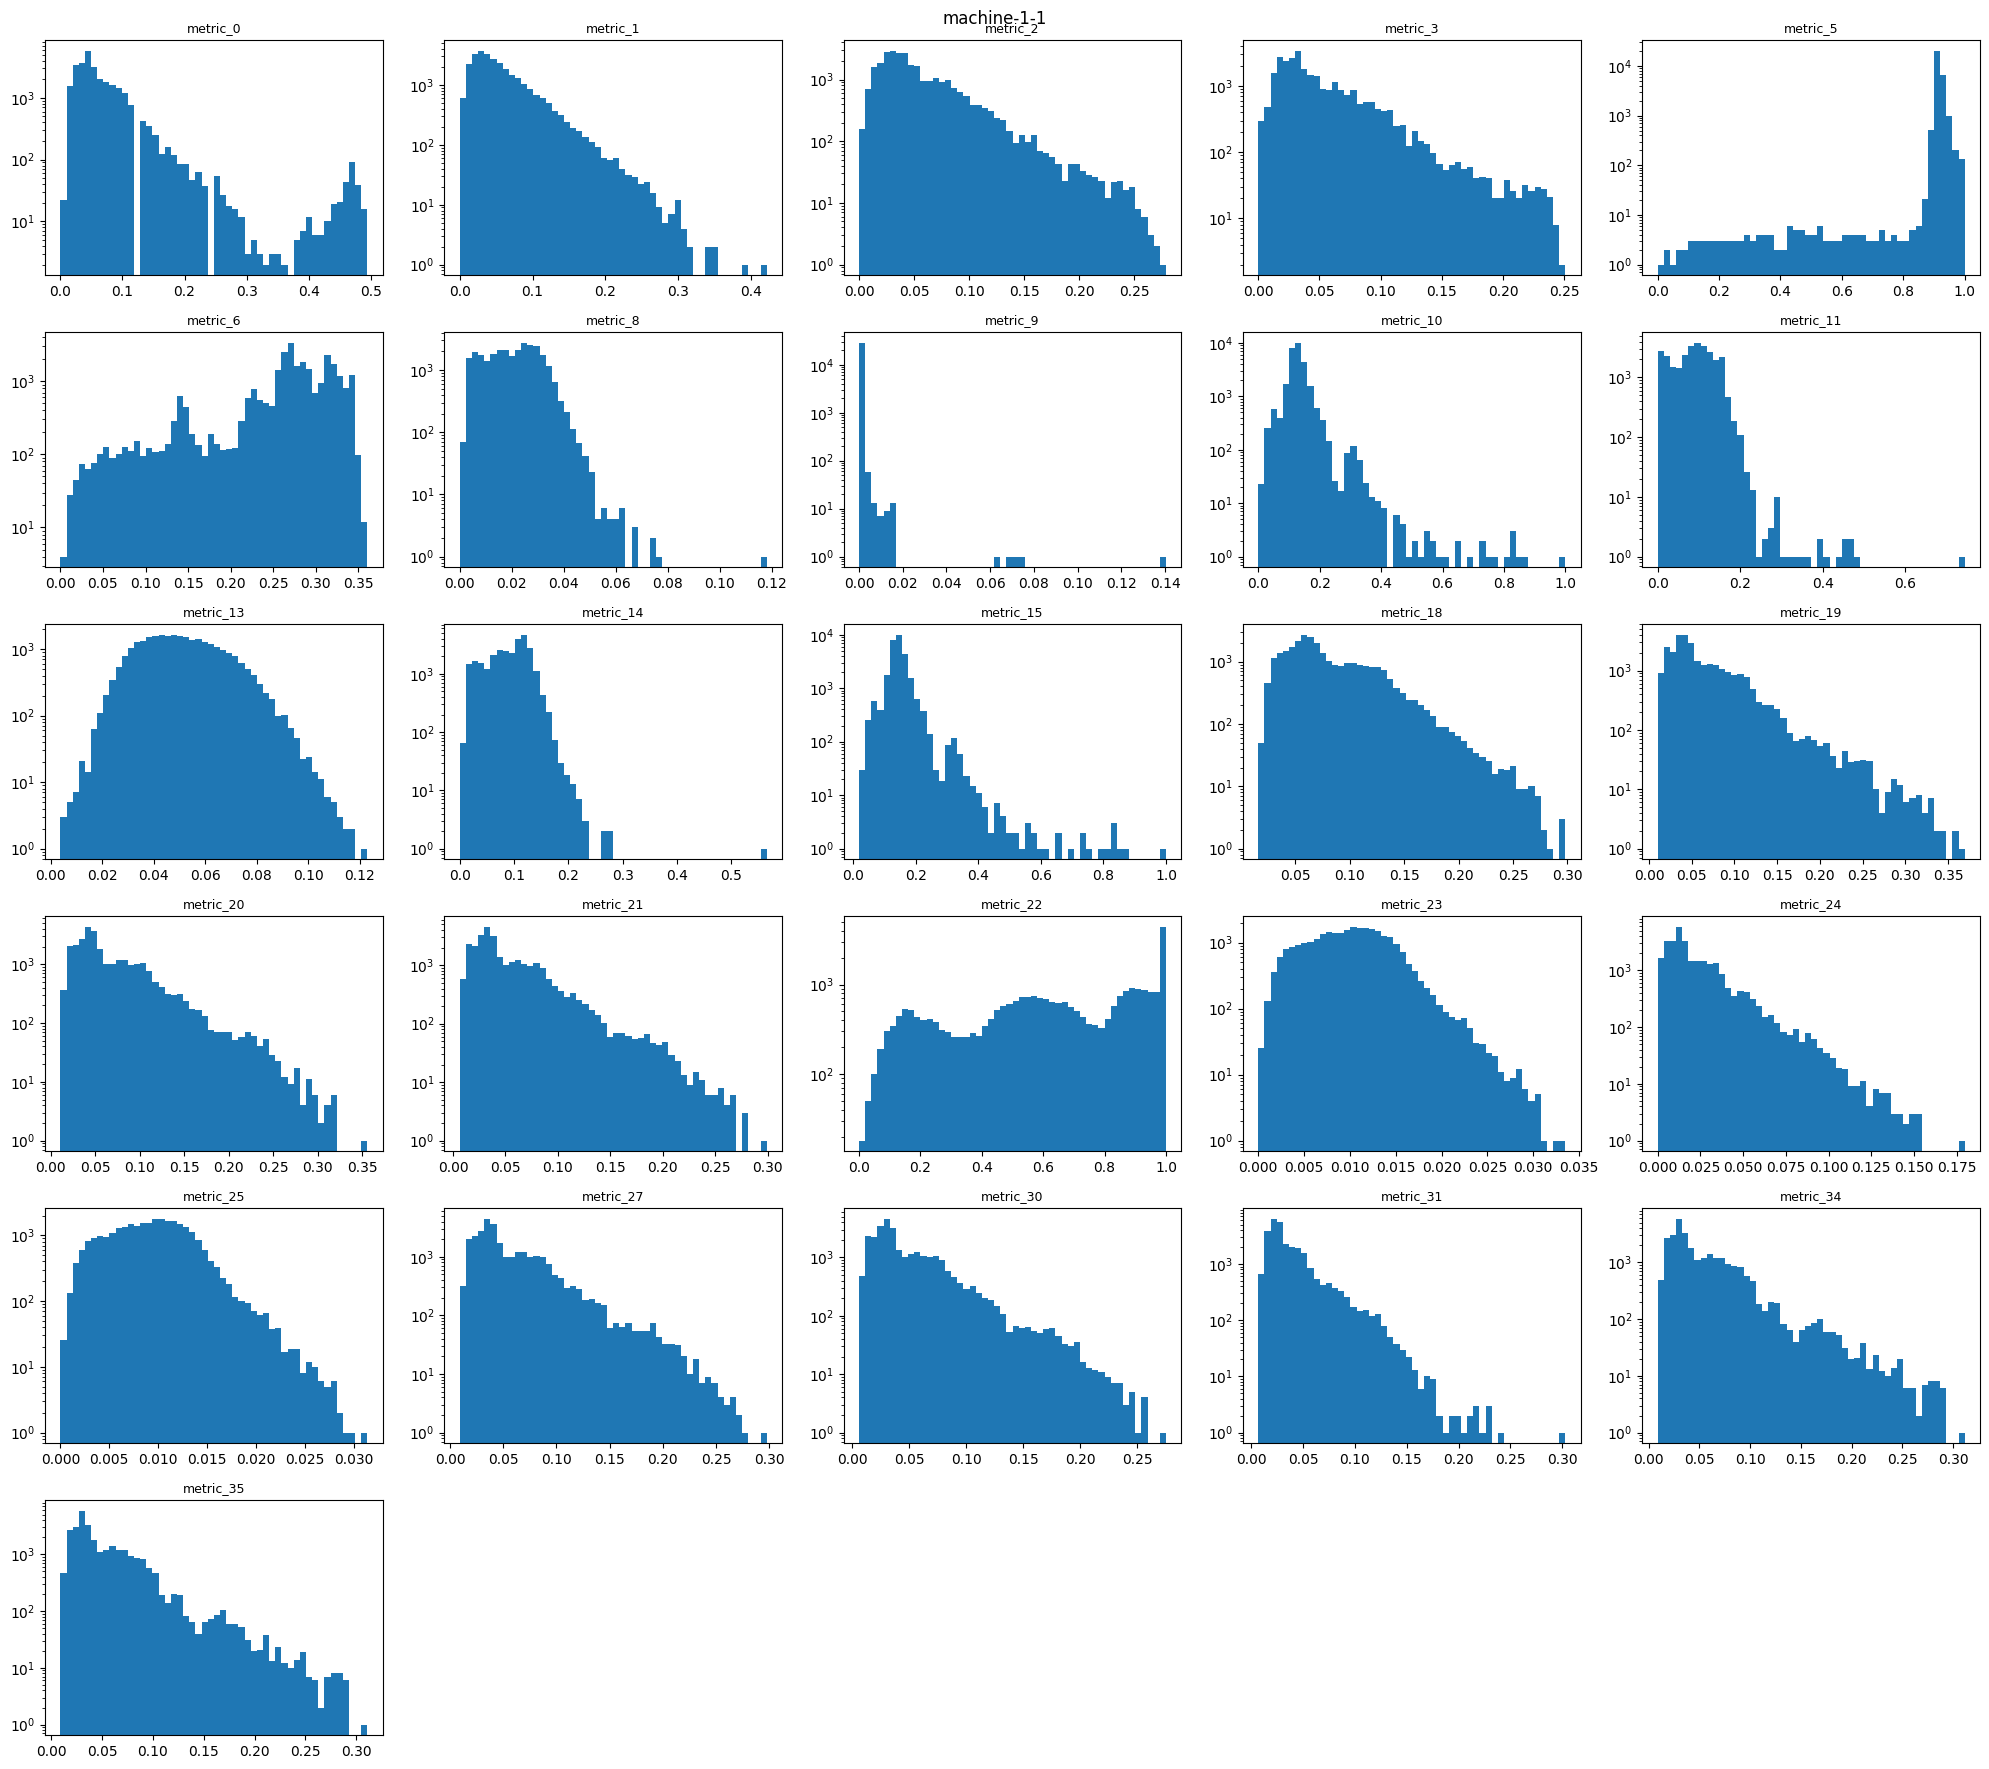

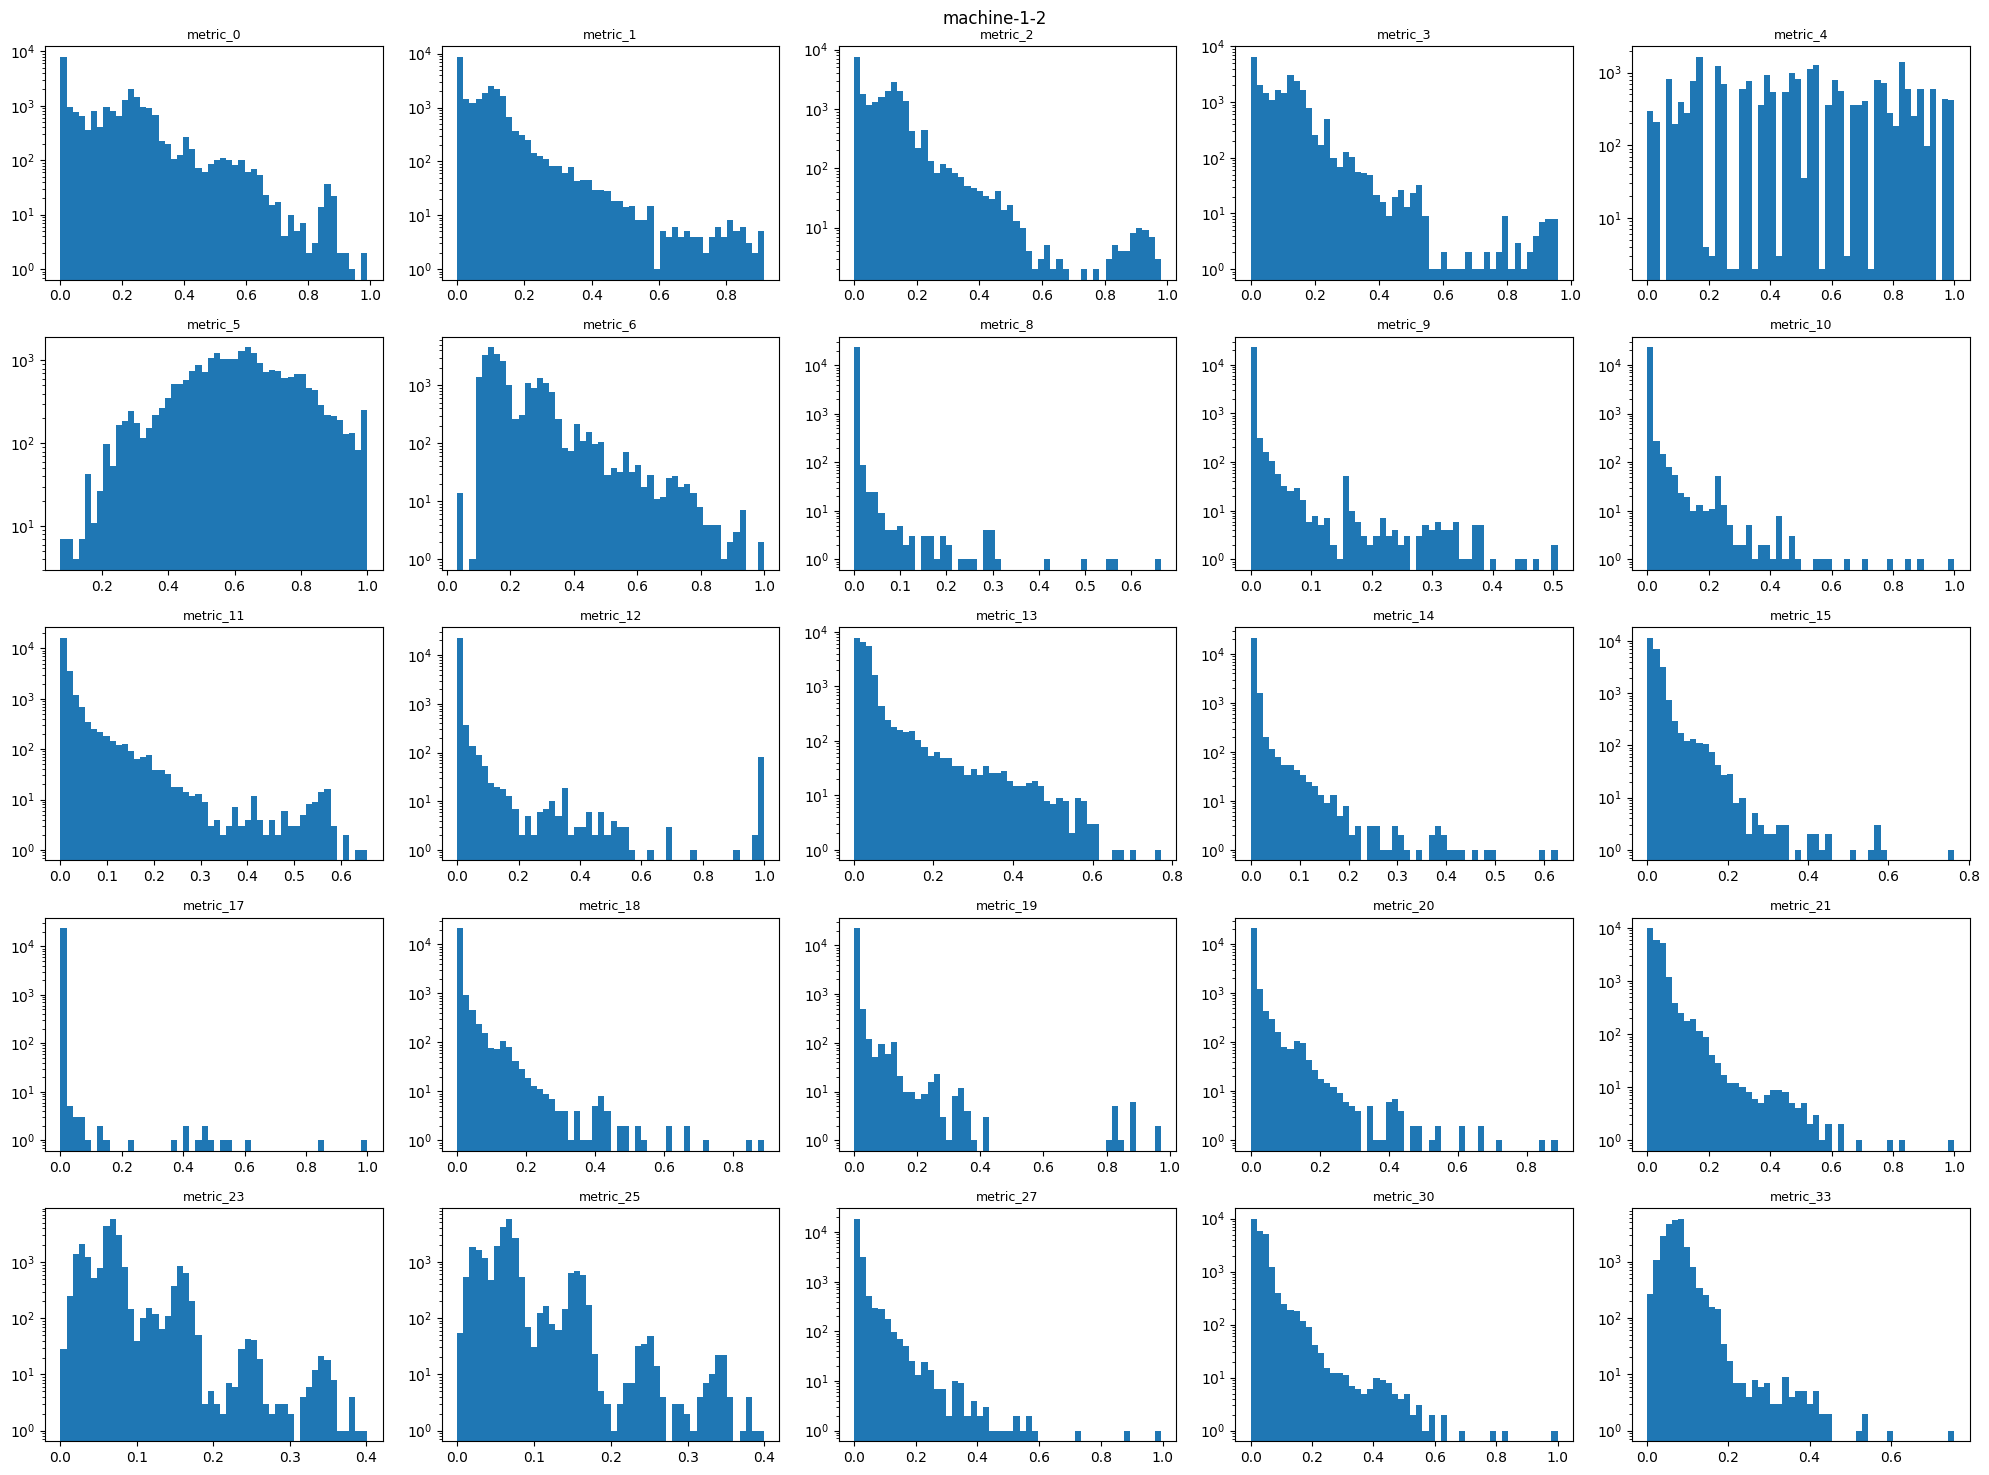

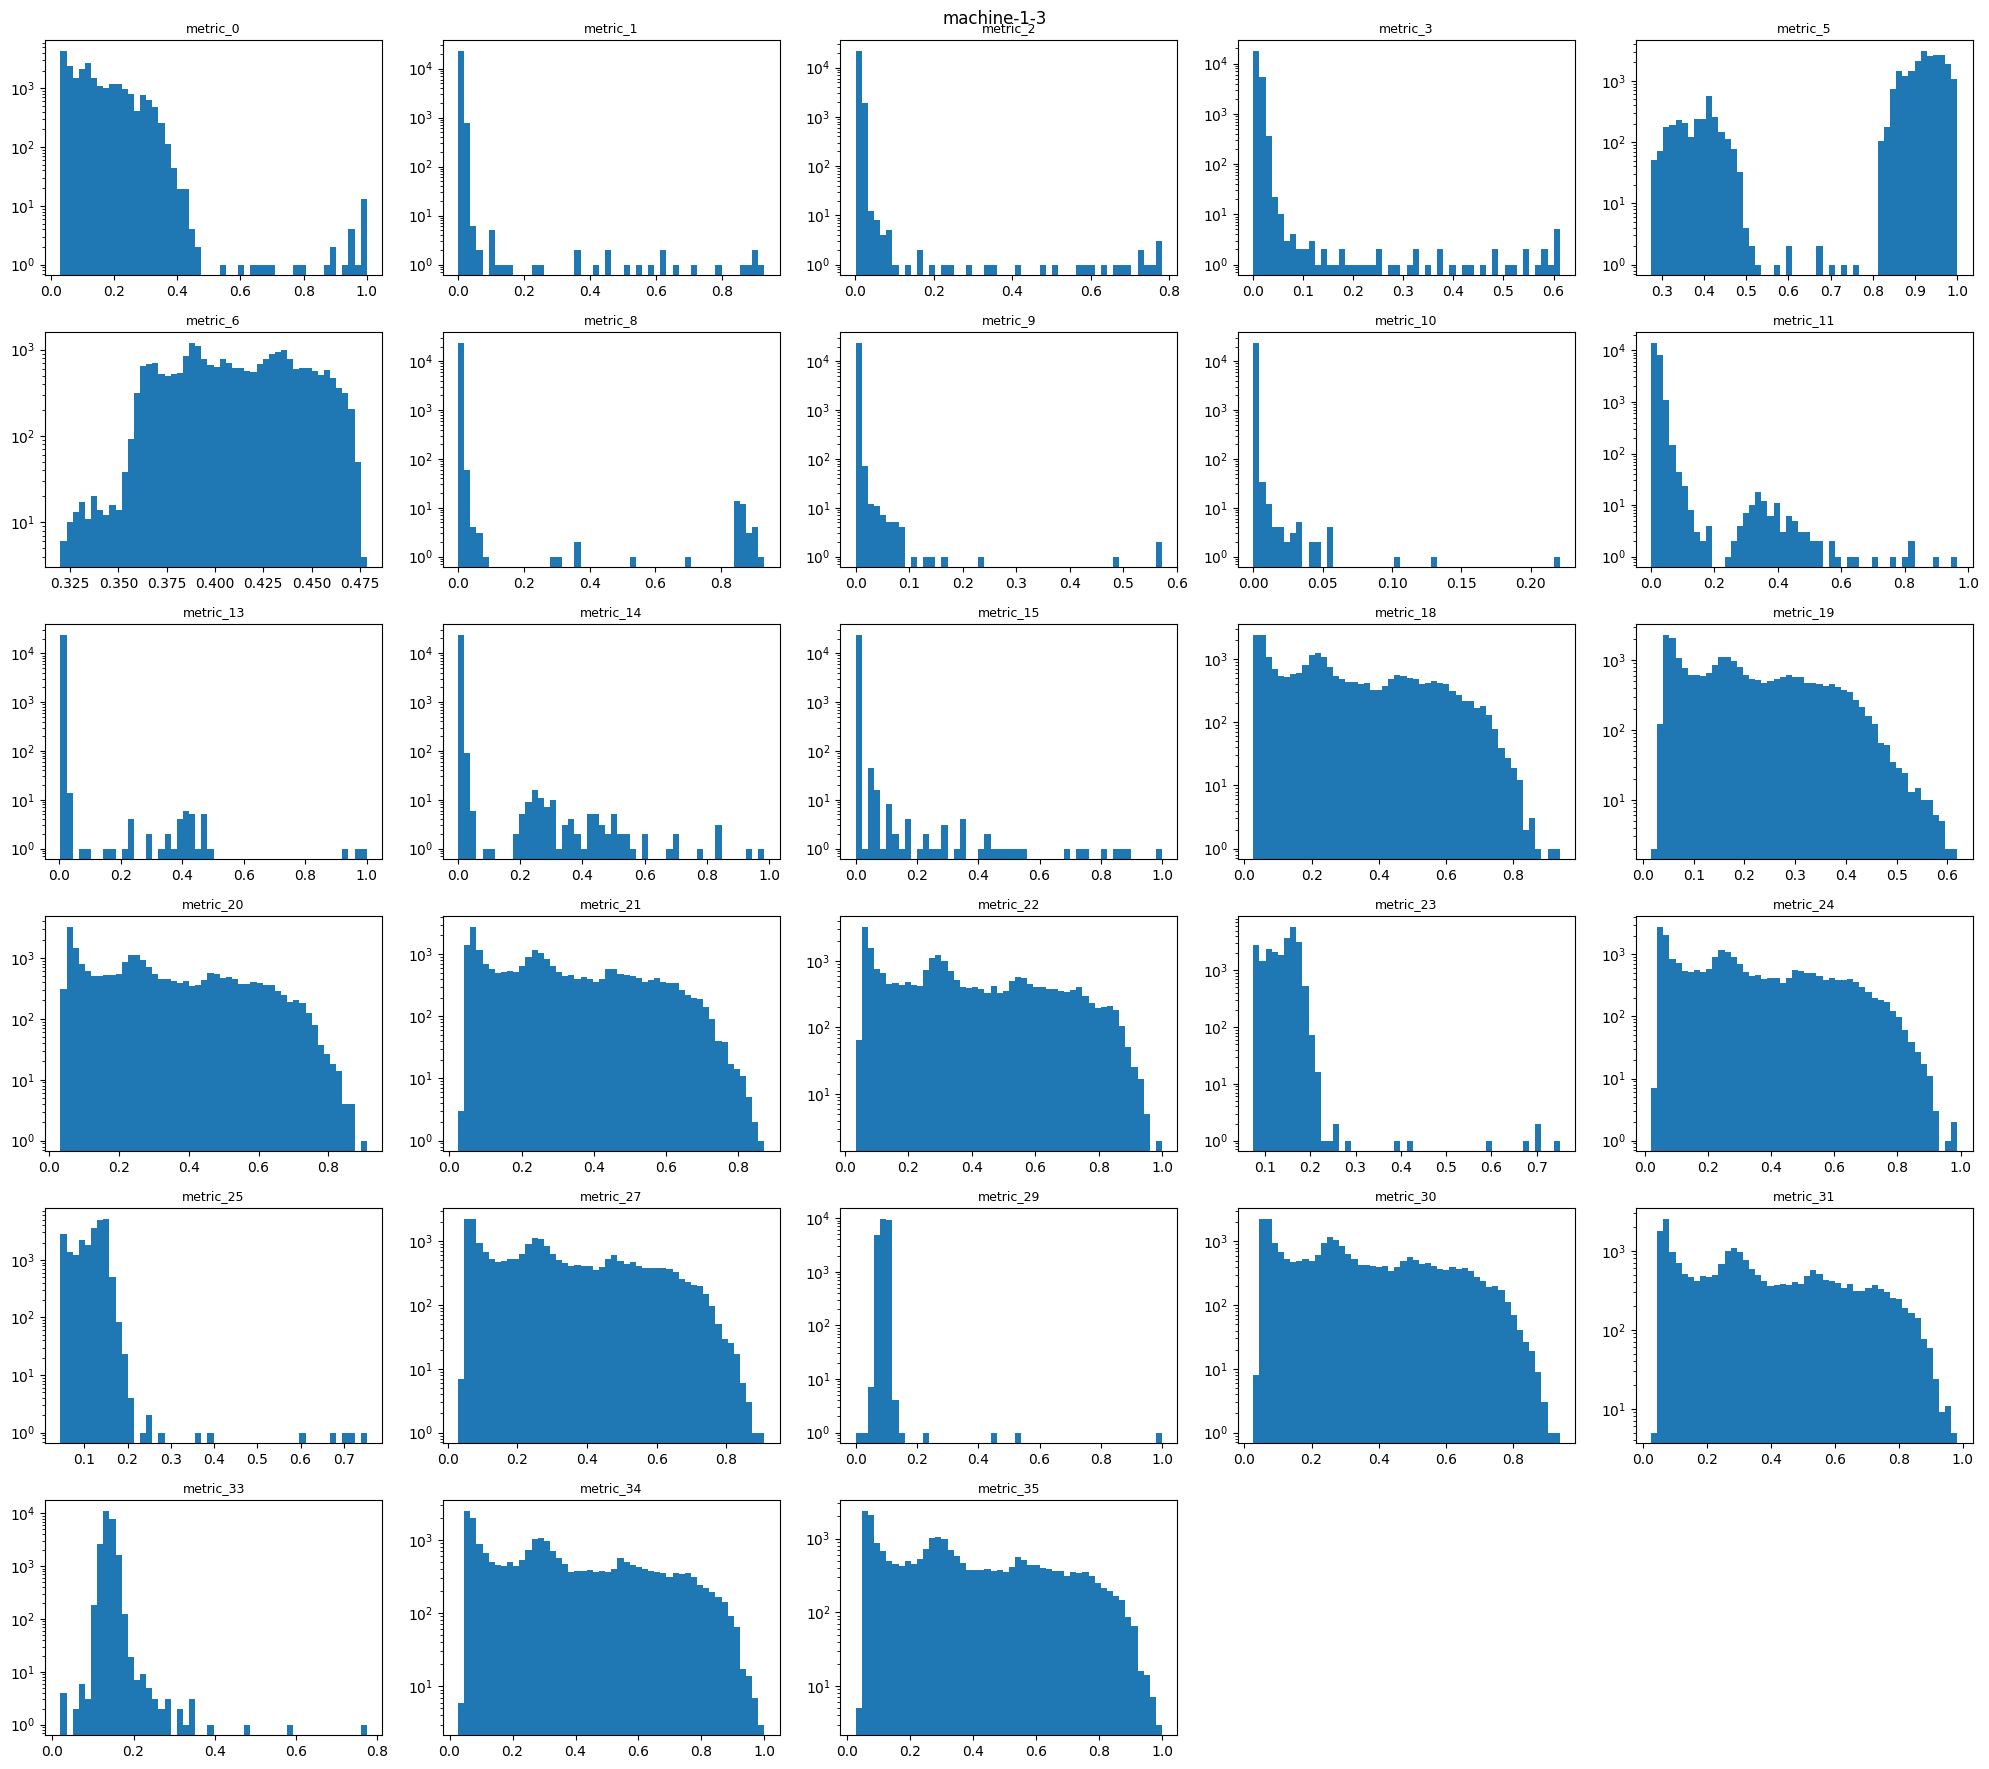

machine-1-1 identical columns: []
machine-1-2 identical columns: []
machine-1-3 identical columns: []


In [20]:
import matplotlib.pyplot as plt

def dist_summary(df, cols):
    x = df[cols]
    q1, q3 = x.quantile(0.25), x.quantile(0.75)
    iqr = q3 - q1
    out = pd.DataFrame({
        "min": x.min(), "q01": x.quantile(0.01), "median": x.median(),
        "mean": x.mean(), "q99": x.quantile(0.99), "max": x.max(),
        "std": x.std(), "skew": x.skew(), "kurt": x.kurt(),
        "pct_zero": (x == 0).mean() * 100,
        "pct_outside_IQR": ((x < q1 - 1.5*iqr) | (x > q3 + 1.5*iqr)).mean() * 100,
    })
    return out.round(4)

for name, df in data.items():
    print(f"\n===== {name} (continuous, sorted by skew) =====")
    print(dist_summary(df, groups[name]["cont"]).sort_values("skew", ascending=False).to_string())

# Histograms (log y-axis so rare tails are visible)
for name, df in data.items():
    cols = groups[name]["cont"]
    nrows = int(np.ceil(len(cols) / 5))
    fig, axes = plt.subplots(nrows, 5, figsize=(20, 3 * nrows))
    for ax, c in zip(axes.ravel(), cols):
        ax.hist(df[c], bins=50)
        ax.set_yscale("log")
        ax.set_title(c, fontsize=9)
    for ax in axes.ravel()[len(cols):]:
        ax.axis("off")
    fig.suptitle(name)
    plt.tight_layout()
    plt.show()

# Exact duplicate columns among non-dead metrics
for name, df in data.items():
    live = df.loc[:, df.nunique() > 1]
    dup = live.columns[live.T.duplicated(keep=False)].tolist()
    print(name, "identical columns:", dup)


machine-1-1: rows where >=5 metrics are in their top 1%: 339
top 10 rows by number of extreme metrics:
17888    18
20831    17
20903    16
20894    16
20891    16
17896    16
17869    16
17887    16
20849    16
20898    16

machine-1-2: rows where >=5 metrics are in their top 1%: 245
top 10 rows by number of extreme metrics:
21033    10
14809     9
22324     9
7586      9
19610     9
17172     9
1829      8
22256     8
22257     8
11910     8

machine-1-3: rows where >=5 metrics are in their top 1%: 386
top 10 rows by number of extreme metrics:
21305    21
22662    17
2501     16
20953    16
12571    16
22667    15
3944     15
12575    15
12569    15
12551    15

machine-1-1: rows with >=8 continuous metrics equal to 0: 0
14653    4
3154     3
4591     3
8875     3
8929     3

machine-1-2: rows with >=8 continuous metrics equal to 0: 512
13132    11
18768     9
2971      9
3151      9
22291     9

machine-1-3: rows with >=8 continuous metrics equal to 0: 0
4558     3
7419     3
1424  

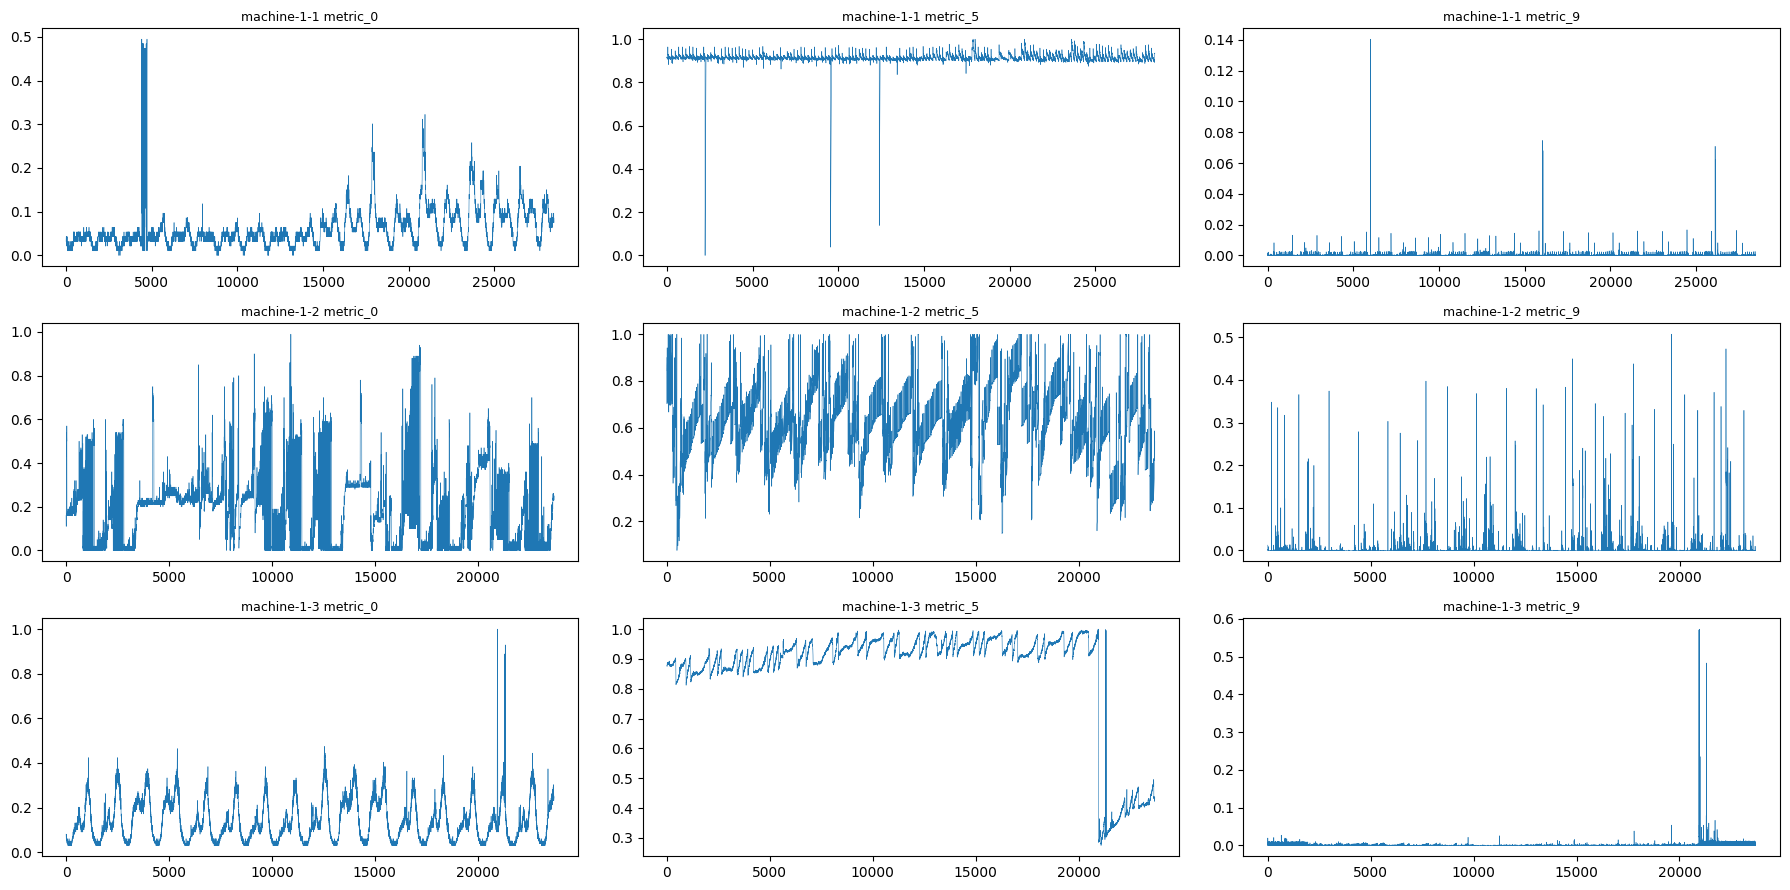

In [21]:
# 1) Are extreme rows shared across metrics? (per machine, continuous metrics only)
for name, df in data.items():
    cols = groups[name]["cont"]
    x = df[cols]
    q99 = x.quantile(0.99)
    extreme = (x > q99)                       # per-metric top 1%
    per_row = extreme.sum(axis=1)
    print(f"\n{name}: rows where >=5 metrics are in their top 1%: {(per_row >= 5).sum()}")
    print("top 10 rows by number of extreme metrics:")
    print(per_row.sort_values(ascending=False).head(10).to_string())

# 2) Rows where many metrics hit exactly 0 (machine-1-1 suspicion)
for name, df in data.items():
    cols = groups[name]["cont"]
    z = (df[cols] == 0).sum(axis=1)
    print(f"\n{name}: rows with >=8 continuous metrics equal to 0:", (z >= 8).sum())
    print(z.sort_values(ascending=False).head(5).to_string())

# 3) Side-by-side comparison of shared continuous metrics (median, q99, std)
shared = sorted(set.intersection(*[set(g["cont"]) for g in groups.values()]),
                key=lambda s: int(s.split("_")[1]))
cmp = pd.concat({name: df[shared].agg(["median", "std"]).T.round(4)
                 for name, df in data.items()}, axis=1)
print("\nShared continuous metrics:", len(shared))
print(cmp.to_string())

# 4) Plot a few metrics over time for each machine
fig, axes = plt.subplots(3, 3, figsize=(18, 9))
for i, (name, df) in enumerate(data.items()):
    for j, c in enumerate(["metric_0", "metric_5", "metric_9"]):
        axes[i, j].plot(df[c].values, lw=0.4)
        axes[i, j].set_title(f"{name} {c}", fontsize=9)
plt.tight_layout(); plt.show()

machine-1-2 zero-rows: 512 in 472 runs; longest: 3
first runs: [(np.int64(962), np.int64(962)), (np.int64(970), np.int64(970)), (np.int64(976), np.int64(976)), (np.int64(992), np.int64(992)), (np.int64(1005), np.int64(1005)), (np.int64(1008), np.int64(1008)), (np.int64(1012), np.int64(1012)), (np.int64(1022), np.int64(1022)), (np.int64(1061), np.int64(1061)), (np.int64(1120), np.int64(1120))]
machine-1-1 burst windows: [(np.int64(17846), np.int64(17922)), (np.int64(17929), np.int64(17934)), (np.int64(20788), np.int64(20919)), (np.int64(20945), np.int64(20952)), (np.int64(23551), np.int64(23551)), (np.int64(23582), np.int64(23591)), (np.int64(23623), np.int64(23653)), (np.int64(23662), np.int64(23699)), (np.int64(23713), np.int64(23713)), (np.int64(23746), np.int64(23746)), (np.int64(23834), np.int64(23838))]
machine-1-2 burst windows: [(np.int64(747), np.int64(747)), (np.int64(1829), np.int64(1829)), (np.int64(3318), np.int64(3318)), (np.int64(3635), np.int64(3635)), (np.int64(4711), n

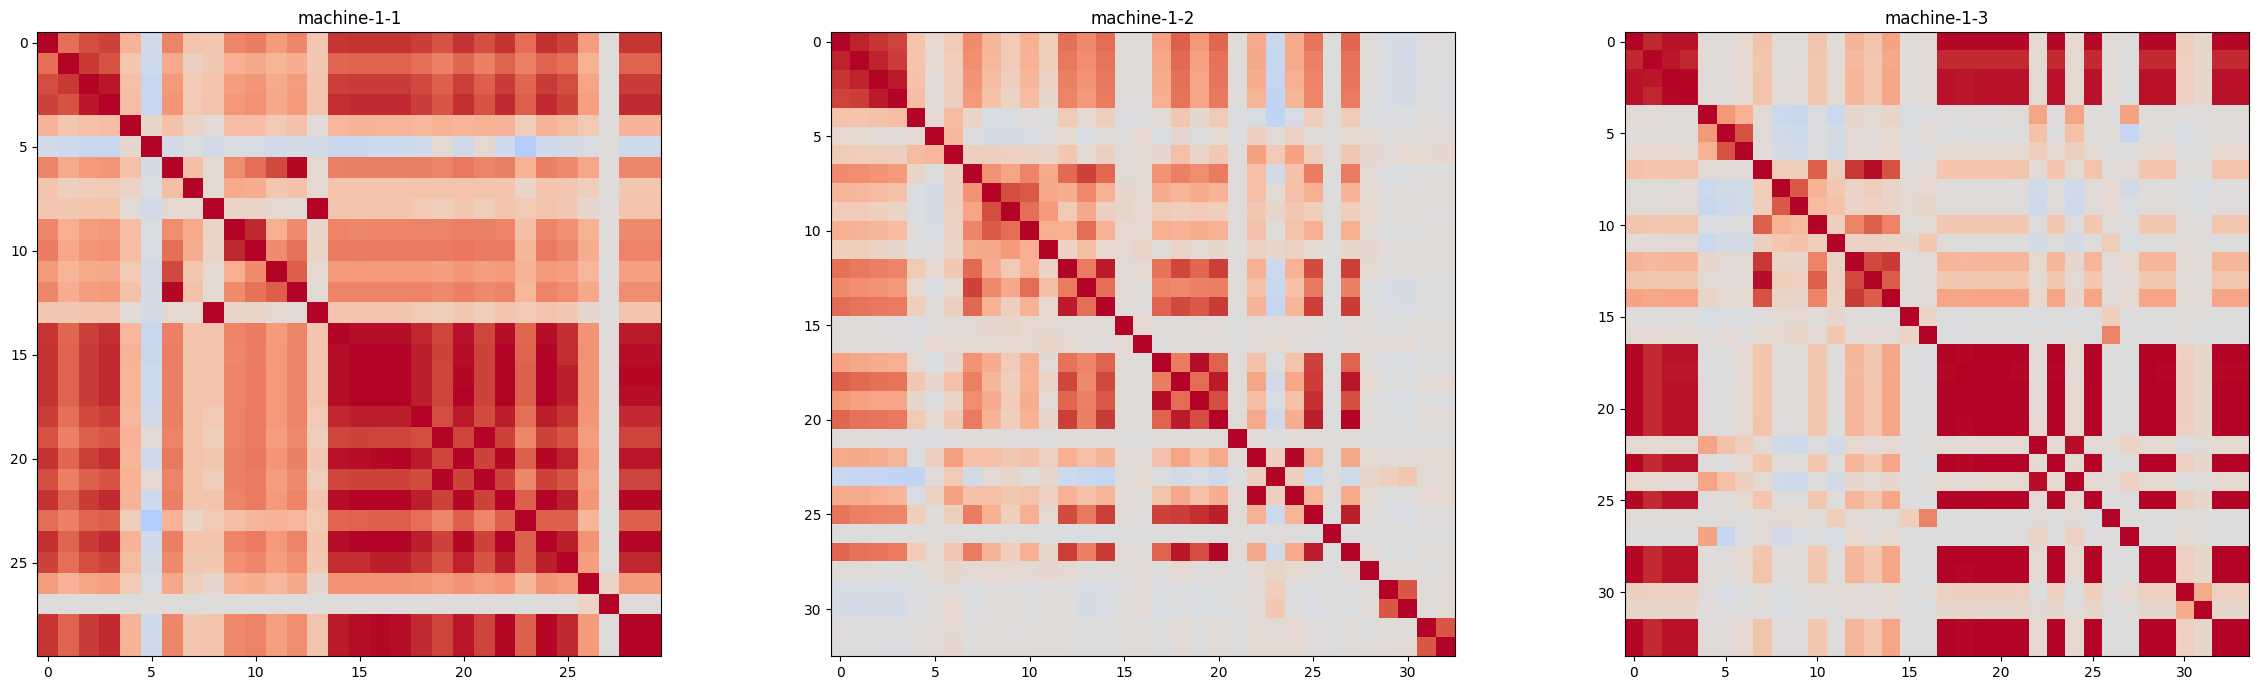

In [22]:
# 1) Are the machine-1-2 zero rows contiguous (dropout) or scattered?
df = data["machine-1-2"]; cols = groups["machine-1-2"]["cont"]
z_rows = (df[cols] == 0).sum(axis=1) >= 8
idx = np.where(z_rows)[0]
runs = np.split(idx, np.where(np.diff(idx) != 1)[0] + 1)
print("machine-1-2 zero-rows:", len(idx), "in", len(runs), "runs; longest:", max(len(r) for r in runs))
print("first runs:", [(r[0], r[-1]) for r in runs[:10]])

# 2) Burst windows: contiguous runs of rows with >=8 metrics in top 1%
for name, d in data.items():
    c = groups[name]["cont"]
    ext = ((d[c] > d[c].quantile(0.99)).sum(axis=1) >= 8).values
    i = np.where(ext)[0]
    rs = np.split(i, np.where(np.diff(i) > 5)[0] + 1) if len(i) else []
    print(name, "burst windows:", [(r[0], r[-1]) for r in rs if len(r)])

# 3) Scaling check: spread of the live metrics, per machine
for name, d in data.items():
    live = d.loc[:, d.nunique() > 1]
    s = live.std()
    rng = live.quantile(0.99) - live.quantile(0.01)
    print(f"\n{name}: std min/median/max = {s.min():.4f} / {s.median():.4f} / {s.max():.4f}")
    print(f"  q99-q01 range min/median/max = {rng.min():.4f} / {rng.median():.4f} / {rng.max():.4f}")
    print("  narrowest metrics (q99-q01):", rng.sort_values().head(5).round(4).to_dict())

# 4) Correlations (Spearman, live metrics only, per machine)
for name, d in data.items():
    live = d.loc[:, d.nunique() > 1]
    corr = live.corr(method="spearman")
    pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
    high = pairs[pairs.abs() > 0.95].sort_values(ascending=False)
    print(f"\n{name}: {len(high)} pairs with |rho|>0.95 (of {len(pairs)})")
    print(high.head(15).round(3).to_string())
    print("weakest-connected metrics (mean |rho|):")
    print(corr.abs().mean().sort_values().head(5).round(3).to_dict())

# 5) Heatmaps
fig, axes = plt.subplots(1, 3, figsize=(24, 7))
for ax, (name, d) in zip(axes, data.items()):
    live = d.loc[:, d.nunique() > 1]
    ax.imshow(live.corr(method="spearman"), cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_title(name)
plt.tight_layout(); plt.show()

In [23]:
for name, df in data.items():
    print(f"\n===== {name} =====")
    print("dtypes:", df.dtypes.unique())
    display(df.head())
    display(df.describe().T.round(4))

# Compare all 38 metrics side by side (mean and std per machine)
cmp_all = pd.concat({n: d.agg(["mean", "std"]).T.round(4) for n, d in data.items()}, axis=1)
display(cmp_all)


===== machine-1-1 =====
dtypes: [dtype('float64')]


,metric_0,metric_1,metric_2,metric_3,metric_4,metric_5,metric_6,metric_7,metric_8,metric_9,...,metric_28,metric_29,metric_30,metric_31,metric_32,metric_33,metric_34,metric_35,metric_36,metric_37
0,0.032258,0.039195,0.027871,0.024390,0.0,0.915385,0.343691,0.0,0.020011,0.000122,...,0.0,0.004298,0.029993,0.022131,0.0,0.000045,0.034677,0.034747,0.0,0.0
1,0.043011,0.048729,0.033445,0.025552,0.0,0.915385,0.344633,0.0,0.019160,0.001722,...,0.0,0.004298,0.030041,0.028821,0.0,0.000045,0.035763,0.035833,0.0,0.0
2,0.043011,0.034958,0.032330,0.025552,0.0,0.915385,0.344633,0.0,0.020011,0.000122,...,0.0,0.004298,0.026248,0.021101,0.0,0.000045,0.033012,0.033082,0.0,0.0
3,0.032258,0.028602,0.030100,0.024390,0.0,0.912821,0.342750,0.0,0.021289,0.000000,...,0.0,0.004298,0.030169,0.025733,0.0,0.000022,0.035112,0.035182,0.0,0.0
4,0.032258,0.019068,0.026756,0.023229,0.0,0.912821,0.342750,0.0,0.018734,0.000000,...,0.0,0.004298,0.027240,0.022645,0.0,0.000034,0.033447,0.033517,0.0,0.0


,count,mean,std,min,25%,50%,75%,max
metric_0,28479.0,0.0642,0.0567,0.0000,0.0323,0.0430,0.0860,0.4946
metric_1,28479.0,0.0569,0.0425,0.0000,0.0275,0.0456,0.0752,0.4216
metric_2,28479.0,0.0535,0.0377,0.0000,0.0279,0.0424,0.0702,0.2787
metric_3,28479.0,0.0502,0.0374,0.0000,0.0244,0.0372,0.0674,0.2509
metric_4,28479.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
metric_5,28479.0,0.9136,0.0380,0.0000,0.9077,0.9128,0.9205,1.0000
metric_6,28479.0,0.2623,0.0667,0.0000,0.2514,0.2740,0.3117,0.3606
metric_7,28479.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
metric_8,28479.0,0.0203,0.0100,0.0000,0.0123,0.0210,0.0280,0.1181
metric_9,28479.0,0.0002,0.0013,0.0000,0.0000,0.0000,0.0001,0.1404



===== machine-1-2 =====
dtypes: [dtype('float64')]


,metric_0,metric_1,metric_2,metric_3,metric_4,metric_5,metric_6,metric_7,metric_8,metric_9,...,metric_28,metric_29,metric_30,metric_31,metric_32,metric_33,metric_34,metric_35,metric_36,metric_37
0,0.16,0.058339,0.090032,0.114586,0.122642,0.899967,0.262767,0.0,0.000746,0.012437,...,0.0,0.0,0.045032,0.0,0.25,0.090278,0.0,0.0,0.0,0.0
1,0.11,0.048404,0.083601,0.111170,0.122642,0.859680,0.262093,0.0,0.000187,0.000315,...,0.0,0.0,0.028284,0.0,0.25,0.076389,0.0,0.0,0.0,0.0
2,0.11,0.044599,0.076923,0.107227,0.122642,0.860669,0.261962,0.0,0.000187,0.000005,...,0.0,0.0,0.034611,0.0,0.25,0.069444,0.0,0.0,0.0,0.0
3,0.12,0.053266,0.075686,0.105125,0.122642,0.781639,0.184000,0.0,0.000187,0.000438,...,0.0,0.0,0.071083,0.0,0.25,0.069444,0.0,0.0,0.0,0.0
4,0.11,0.044599,0.070492,0.101708,0.122642,0.702331,0.106054,0.0,0.000840,0.000000,...,0.0,0.0,0.025307,0.0,0.25,0.069444,0.0,0.0,0.0,0.0


,count,mean,std,min,25%,50%,75%,max
metric_0,23694.0,0.1488,0.1502,0.0000,0.0100,0.1300,0.2400,0.9900
metric_1,23694.0,0.0748,0.0880,0.0000,0.0042,0.0617,0.1146,0.9129
metric_2,23694.0,0.0875,0.0915,0.0000,0.0096,0.0787,0.1331,0.9790
metric_3,23694.0,0.0919,0.0883,0.0000,0.0163,0.0857,0.1388,0.9590
metric_4,23694.0,0.4983,0.2732,0.0000,0.2453,0.4811,0.7453,1.0000
metric_5,23694.0,0.6139,0.1581,0.0755,0.5133,0.6164,0.7187,1.0000
metric_6,23694.0,0.2009,0.1028,0.0321,0.1373,0.1619,0.2616,1.0000
metric_7,23694.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
metric_8,23694.0,0.0009,0.0115,0.0000,0.0000,0.0000,0.0002,0.6635
metric_9,23694.0,0.0028,0.0209,0.0000,0.0000,0.0000,0.0001,0.5074



===== machine-1-3 =====
dtypes: [dtype('float64')]


,metric_0,metric_1,metric_2,metric_3,metric_4,metric_5,metric_6,metric_7,metric_8,metric_9,...,metric_28,metric_29,metric_30,metric_31,metric_32,metric_33,metric_34,metric_35,metric_36,metric_37
0,0.080808,0.003671,0.003107,0.003900,1.0,0.878507,0.432112,0.0,0.000178,0.000000,...,0.0,0.10119,0.155461,0.167464,0.125,0.139073,0.162944,0.162359,0.0,0.0
1,0.070707,0.003337,0.003169,0.003900,1.0,0.876800,0.430267,0.0,0.000059,0.000000,...,0.0,0.10119,0.143482,0.154067,0.125,0.158940,0.152691,0.152530,0.0,0.0
2,0.060606,0.003449,0.003231,0.003900,1.0,0.878358,0.431871,0.0,0.000475,0.019782,...,0.0,0.10119,0.129686,0.138756,0.125,0.145695,0.140242,0.140153,0.0,0.0
3,0.060606,0.005618,0.003915,0.004134,1.0,0.878284,0.431711,0.0,0.001722,0.000000,...,0.0,0.10119,0.130022,0.138756,0.125,0.152318,0.139876,0.139789,0.0,0.0
4,0.060606,0.006842,0.004723,0.004523,1.0,0.875983,0.429224,0.0,0.000119,0.000000,...,0.0,0.10119,0.131032,0.141627,0.000,0.112583,0.144636,0.144521,0.0,0.0


,count,mean,std,min,25%,50%,75%,max
metric_0,23702.0,0.1395,0.0937,0.0303,0.0606,0.1111,0.2020,1.0000
metric_1,23702.0,0.0077,0.0193,0.0003,0.0031,0.0057,0.0100,0.9300
metric_2,23702.0,0.0083,0.0190,0.0010,0.0032,0.0062,0.0110,0.7821
metric_3,23702.0,0.0100,0.0182,0.0014,0.0036,0.0075,0.0136,0.6125
metric_4,23702.0,0.9927,0.0216,0.9286,1.0000,1.0000,1.0000,1.0000
metric_5,23702.0,0.8645,0.1769,0.2749,0.8805,0.9221,0.9543,1.0000
metric_6,23702.0,0.4119,0.0307,0.3199,0.3876,0.4110,0.4365,0.4786
metric_7,23702.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
metric_8,23702.0,0.0018,0.0336,0.0000,0.0001,0.0002,0.0005,0.9318
metric_9,23702.0,0.0005,0.0071,0.0000,0.0000,0.0000,0.0000,0.5726


machine-1-1         machine-1-2         machine-1-3        
                 mean     std        mean     std        mean     std
metric_0       0.0642  0.0567      0.1488  0.1502      0.1395  0.0937
metric_1       0.0569  0.0425      0.0748  0.0880      0.0077  0.0193
metric_2       0.0535  0.0377      0.0875  0.0915      0.0083  0.0190
metric_3       0.0502  0.0374      0.0919  0.0883      0.0100  0.0182
metric_4       0.0000  0.0000      0.4983  0.2732      0.9927  0.0216
metric_5       0.9136  0.0380      0.6139  0.1581      0.8645  0.1769
metric_6       0.2623  0.0667      0.2009  0.1028      0.4119  0.0307
metric_7       0.0000  0.0000      0.0000  0.0000      0.0000  0.0000
metric_8       0.0203  0.0100      0.0009  0.0115      0.0018  0.0336
metric_9       0.0002  0.0013      0.0028  0.0209      0.0005  0.0071
metric_10      0.1300  0.0395      0.0035  0.0265      0.0001  0.0022
metric_11      0.0870  0.0455      0.0217  0.0482      0.0223  0.0298
metric_12      0.0266  0.0165      0.0067  0.0635      0.0018  0.0386
metric_13      0.0512  0.0156      0.0372  0.0566      0.0101  0.0182
metric_14      0.0896  0.0371      0.0064  0.0188      0.0066  0.0274
metric_15      0.1458  0.0391      0.0214  0.0301      0.0027  0.0197
metric_16      0.0000  0.0000      0.0001  0.0070      0.0000  0.0003
metric_17      0.0000  0.0000      0.0003  0.0133      0.0000  0.0004
metric_18      0.0804  0.0397      0.0094  0.0309      0.2743  0.2004
metric_19      0.0619  0.0415      0.0098  0.0307      0.1940  0.1199
metric_20      0.0658  0.0426      0.0111  0.0310      0.2982  0.2005
metric_21      0.0510  0.0359      0.0341  0.0417      0.2903  0.1922
metric_22      0.6485  0.2857      0.0367  0.0427      0.3491  0.2355
metric_23      0.0101  0.0044      0.0701  0.0414      0.1385  0.0330
metric_24      0.0209  0.0179      0.0804  0.1027      0.3074  0.2157
metric_25      0.0092  0.0041      0.0679  0.0414      0.1150  0.0353
metric_26      0.0000  0.0000      0.0000  0.0000      0.0000  0.0000
metric_27      0.0549  0.0356      0.0175  0.0311      0.3047  0.2013
metric_28      0.0000  0.0000      0.0000  0.0000      0.0001  0.0097
metric_29      0.0055  0.0025      0.0000  0.0065      0.0909  0.0123
metric_30      0.0473  0.0331      0.0338  0.0417      0.3140  0.2109
metric_31      0.0362  0.0237      0.0009  0.0172      0.3445  0.2345
metric_32      0.0002  0.0002      0.1474  0.1240      0.0312  0.0542
metric_33      0.0000  0.0000      0.0699  0.0321      0.1389  0.0148
metric_34      0.0504  0.0350      0.0020  0.0335      0.3510  0.2399
metric_35      0.0504  0.0350      0.0032  0.0415      0.3508  0.2399
metric_36      0.0000  0.0000      0.0000  0.0000      0.0000  0.0000
metric_37      0.0000  0.0000      0.0000  0.0000      0.0000  0.0000

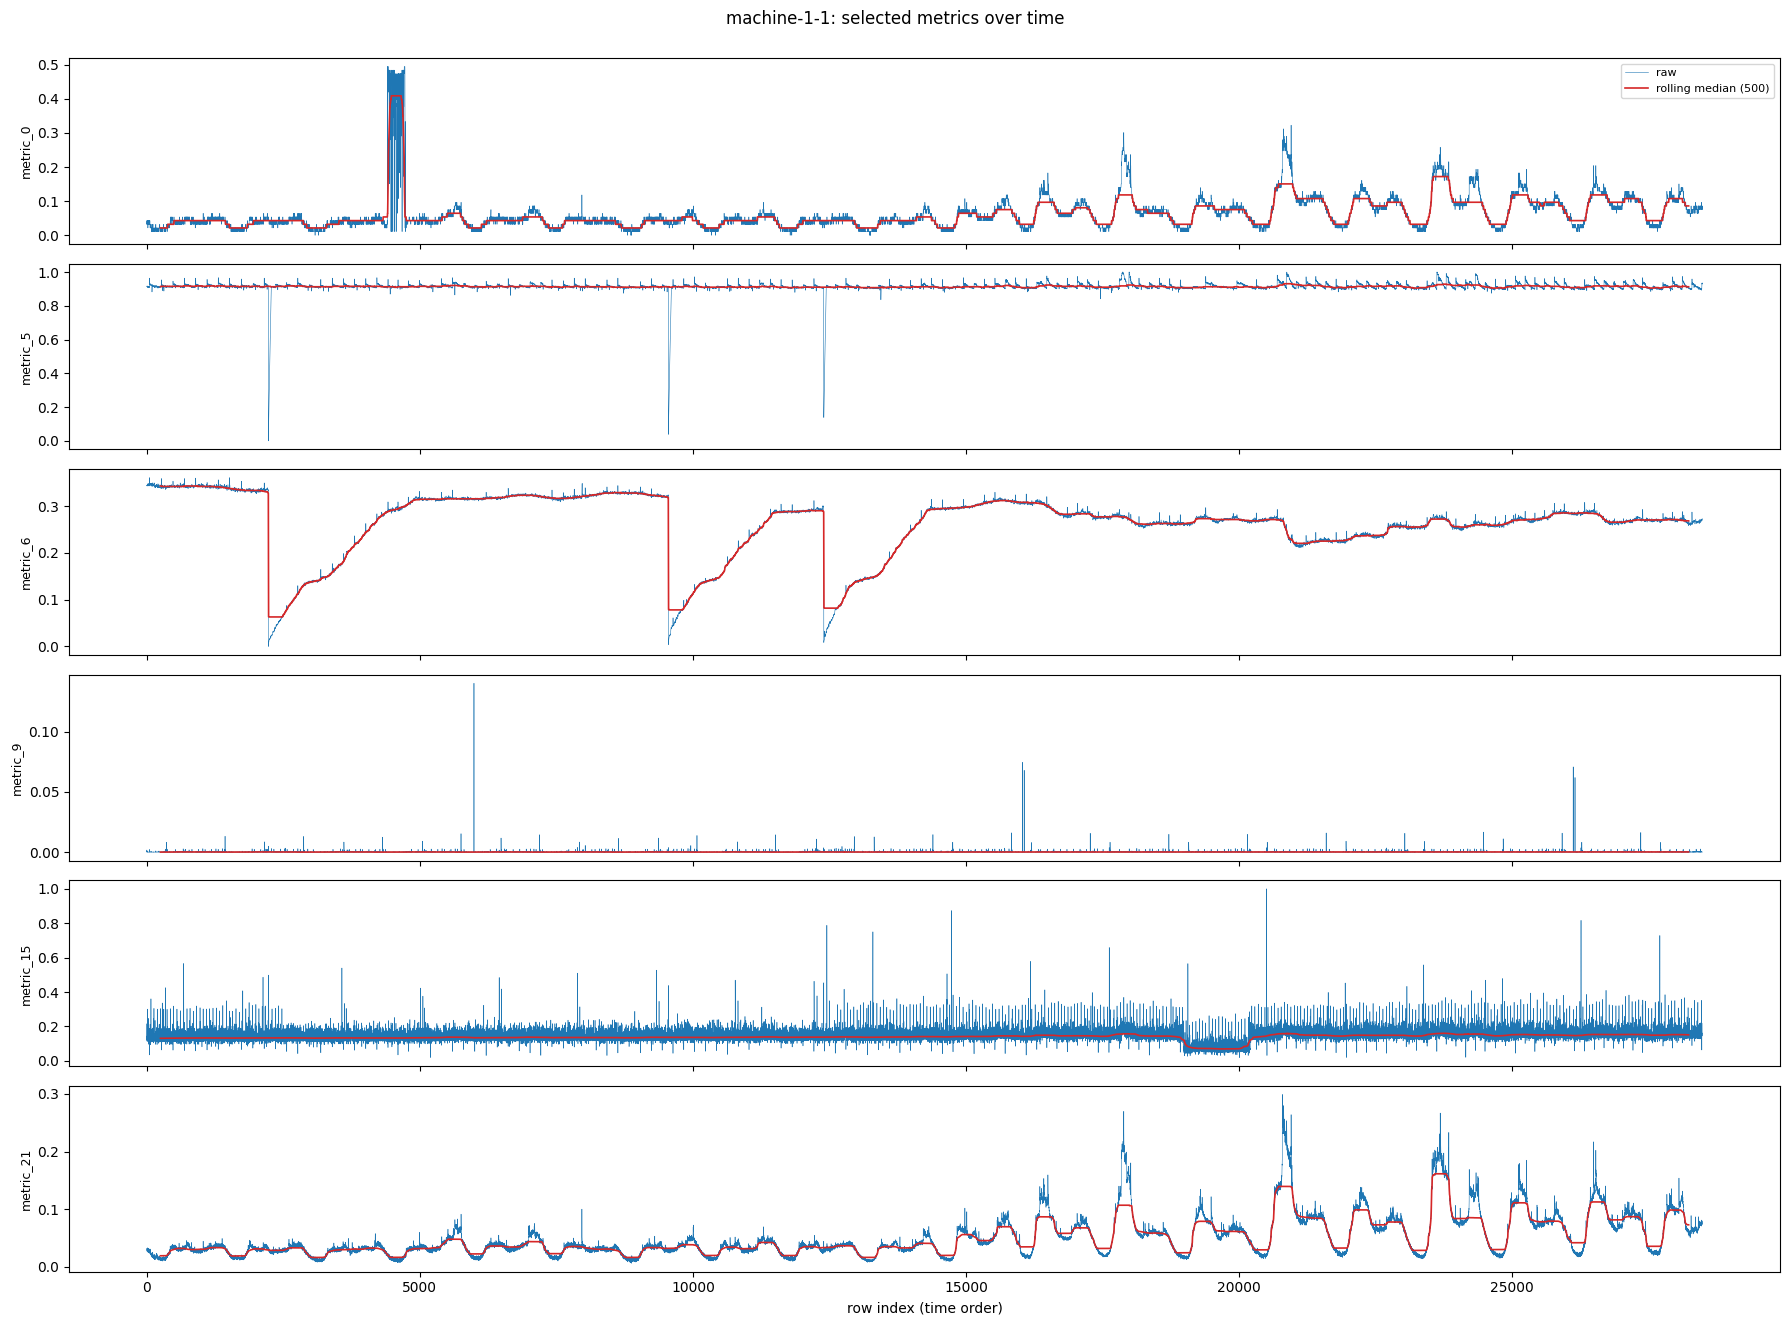

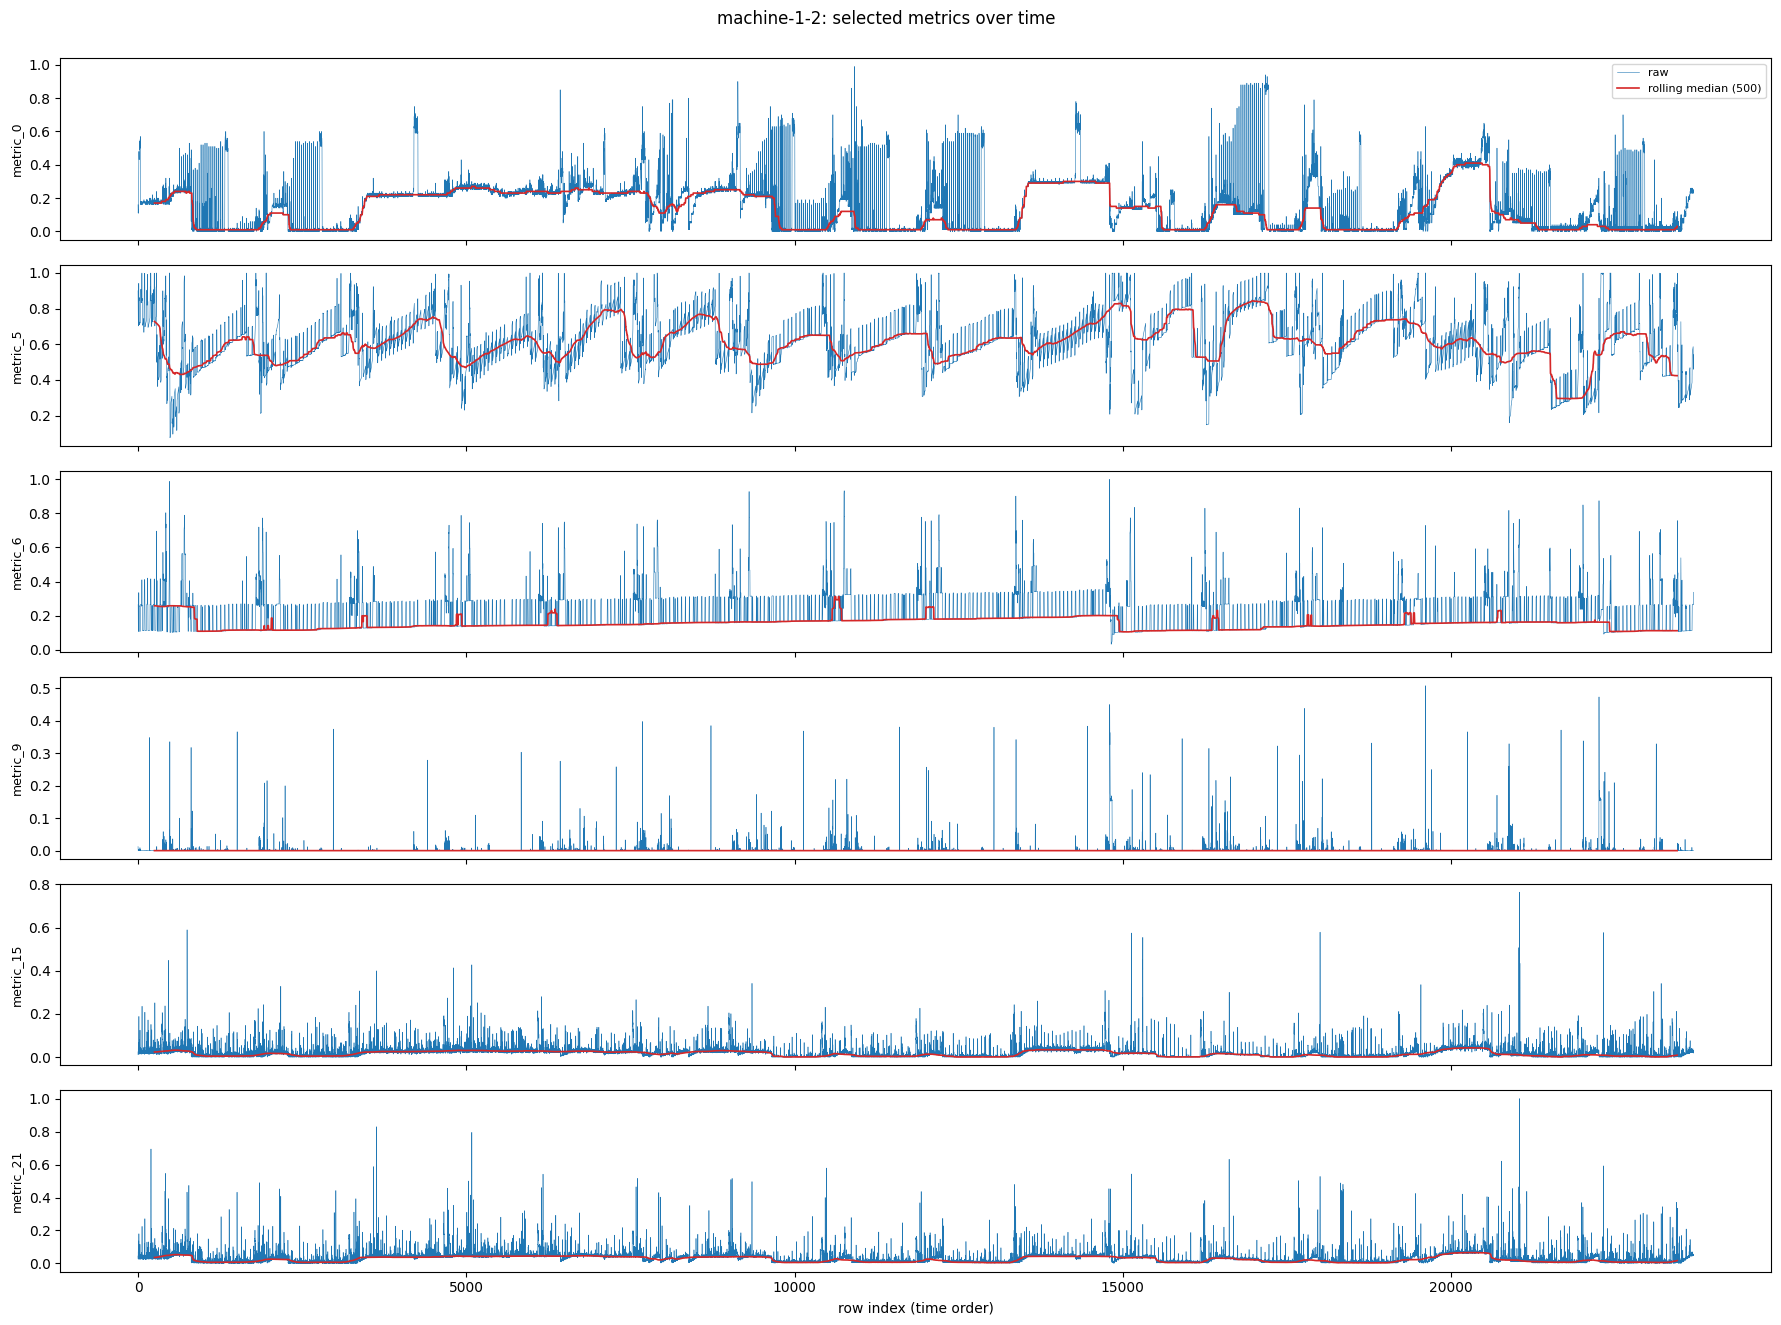

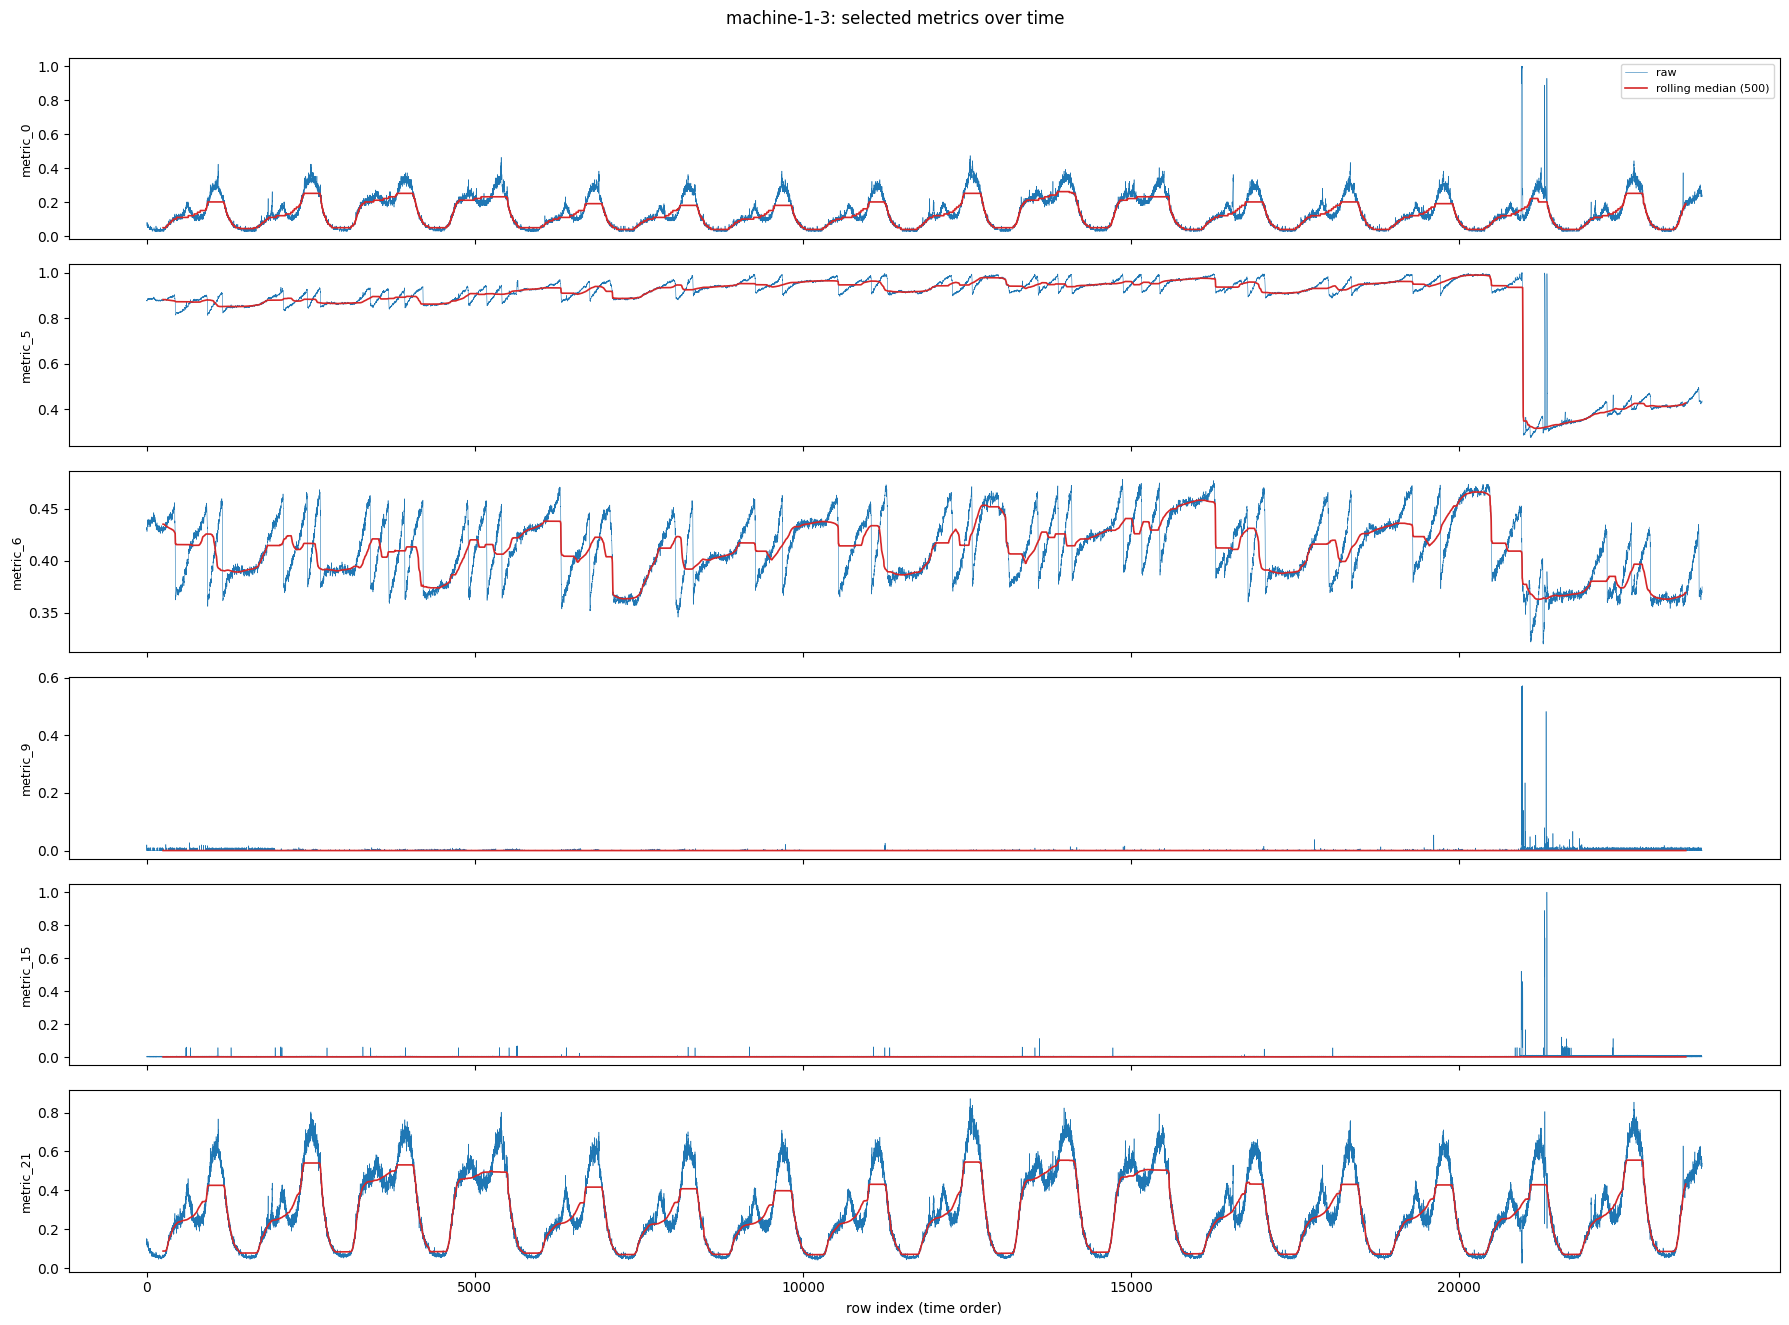

In [24]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plot_metrics = ["metric_0", "metric_5", "metric_6", "metric_9", "metric_15", "metric_21"]

for name, df in data.items():
    fig, axes = plt.subplots(len(plot_metrics), 1, figsize=(18, 2.2 * len(plot_metrics)), sharex=True)
    for ax, c in zip(axes, plot_metrics):
        ax.plot(df[c].values, lw=0.4, color="tab:blue", label="raw")
        ax.plot(df[c].rolling(500, center=True).median().values, lw=1.2, color="tab:red", label="rolling median (500)")
        ax.set_ylabel(c, fontsize=9)
    axes[0].legend(loc="upper right", fontsize=8)
    axes[-1].set_xlabel("row index (time order)")
    fig.suptitle(f"{name}: selected metrics over time", y=1.0)
    plt.tight_layout()
    plt.show()

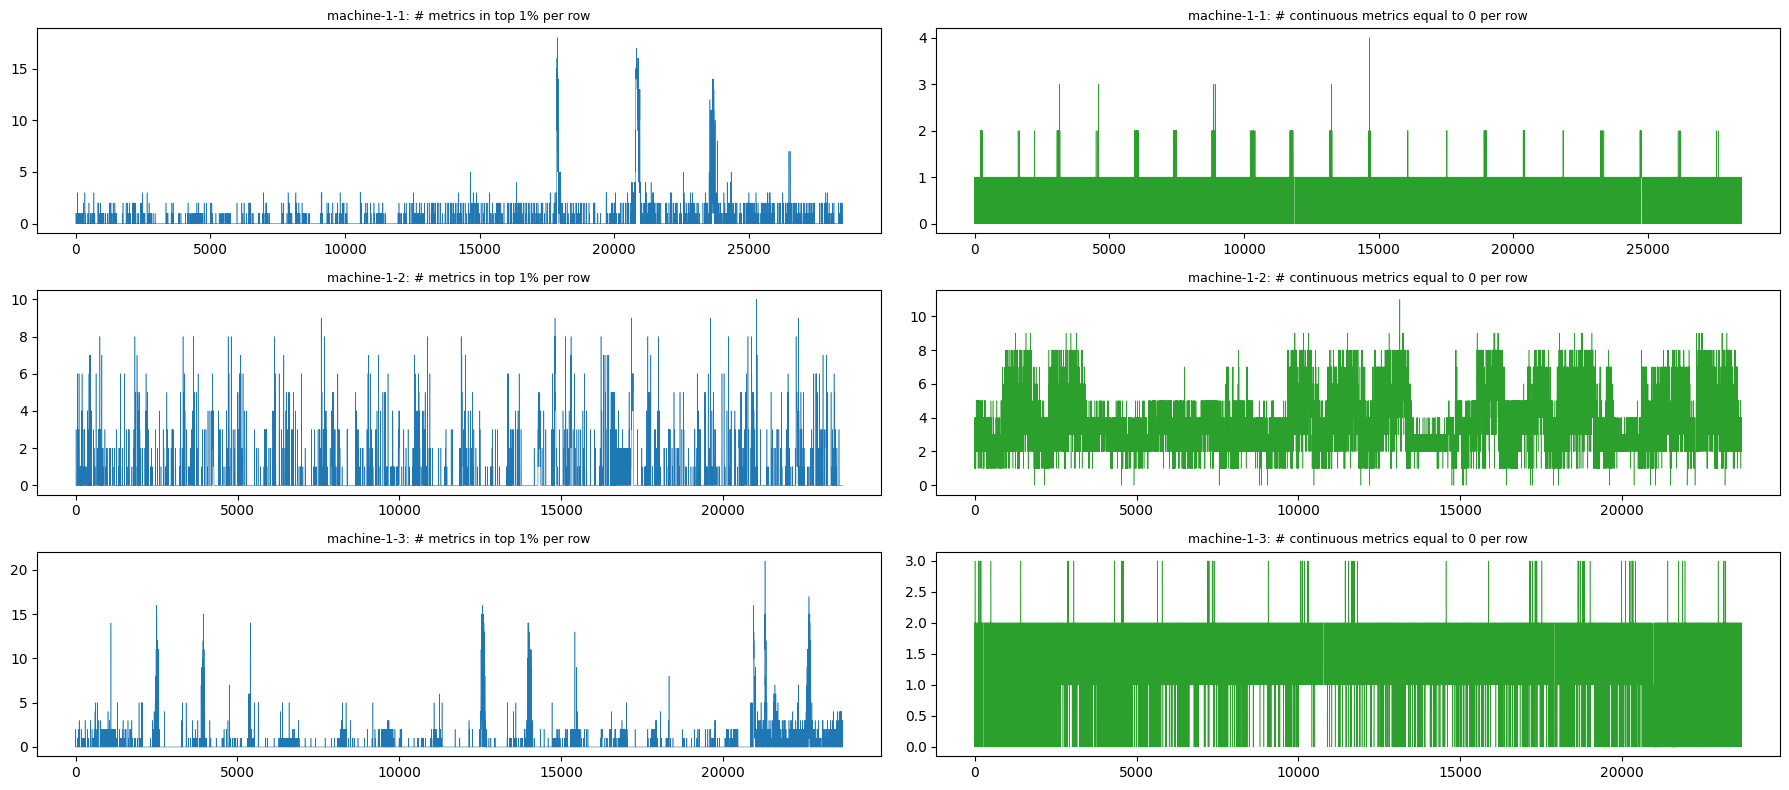

first / last zero-row: 962 23508
0        40
2000     47
8000     23
10000    74
12000    71
14000    42
16000    55
18000    67
20000    21
22000    72
dtype: int64


In [25]:
fig, axes = plt.subplots(3, 2, figsize=(18, 8))
for i, (name, df) in enumerate(data.items()):
    c = groups[name]["cont"]
    n_extreme = (df[c] > df[c].quantile(0.99)).sum(axis=1)
    n_zero = (df[c] == 0).sum(axis=1)
    axes[i, 0].plot(n_extreme.values, lw=0.4)
    axes[i, 0].set_title(f"{name}: # metrics in top 1% per row", fontsize=9)
    axes[i, 1].plot(n_zero.values, lw=0.4, color="tab:green")
    axes[i, 1].set_title(f"{name}: # continuous metrics equal to 0 per row", fontsize=9)
plt.tight_layout()
plt.show()

# Where do machine-1-2's zero rows start, and are they spread evenly?
d = data["machine-1-2"]; c = groups["machine-1-2"]["cont"]
z = np.where((d[c] == 0).sum(axis=1) >= 8)[0]
print("first / last zero-row:", z.min(), z.max())
print(pd.Series(z).groupby(pd.Series(z) // 2000 * 2000).size())   # count per 2000-row block

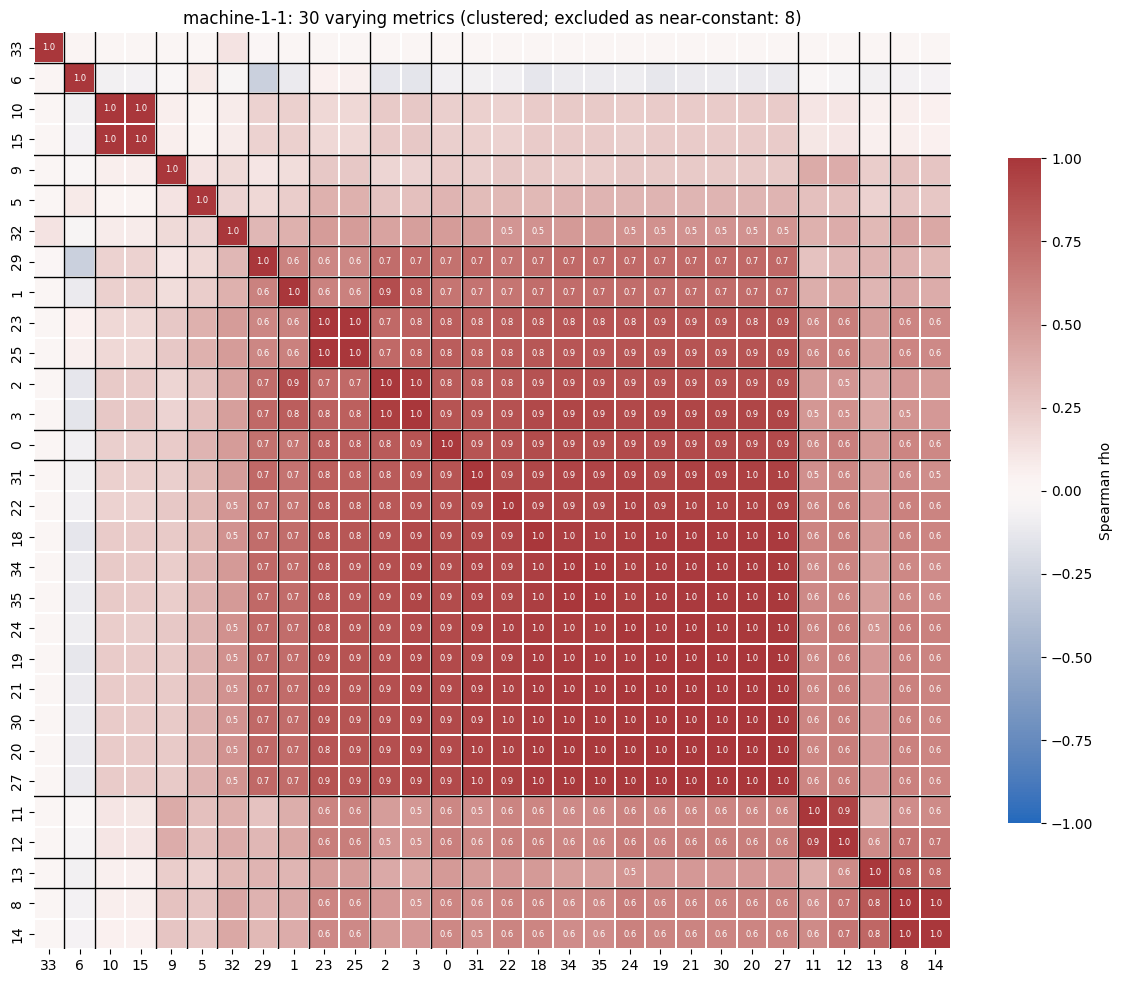

machine-1-1 excluded (near-constant): ['4', '7', '16', '17', '26', '28', '36', '37']
  group 1: ['10', '15']
  group 2: ['23', '25']
  group 3: ['2', '3']
  group 4: ['18', '19', '20', '21', '22', '24', '27', '30', '31', '34', '35']
  group 8: ['11', '12']
  group 9: ['8', '14']


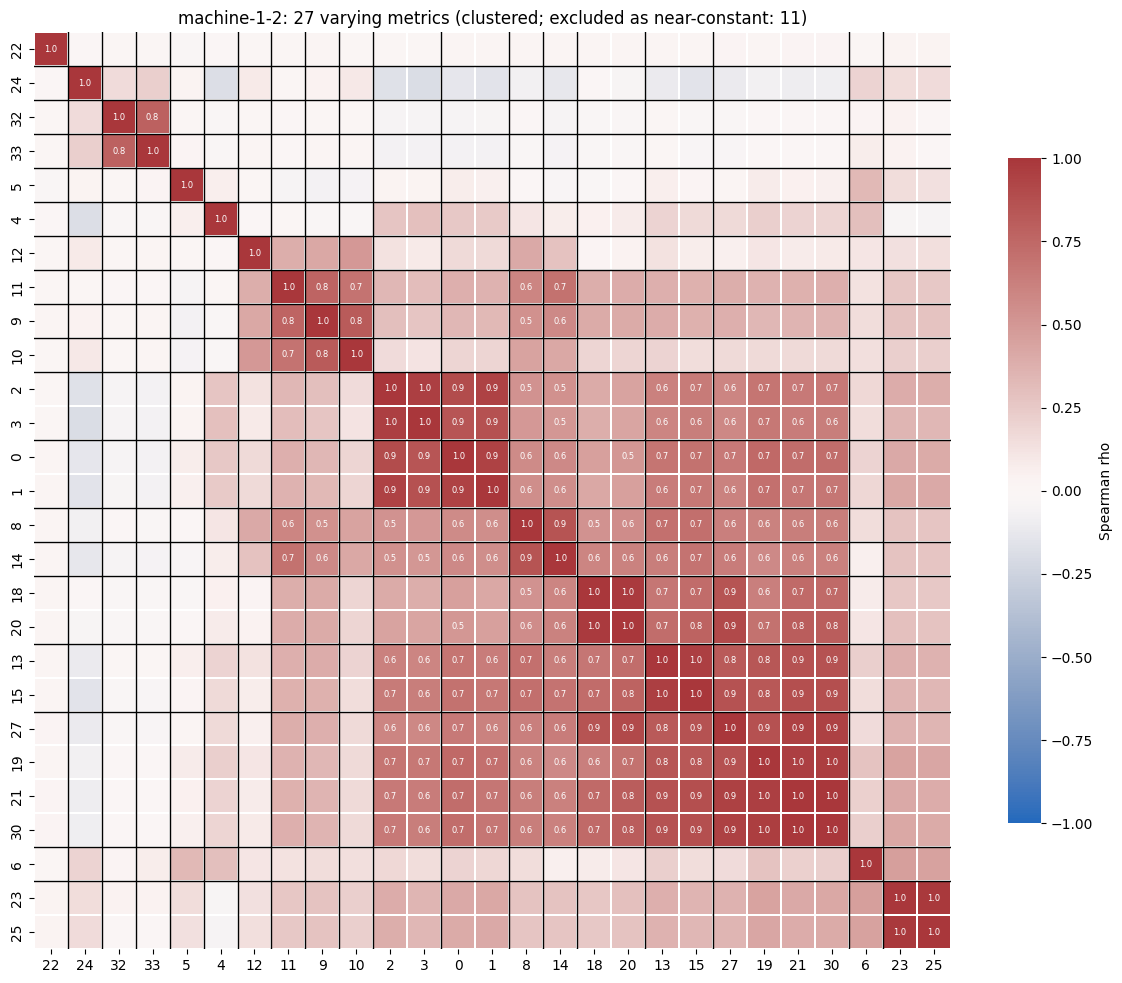

machine-1-2 excluded (near-constant): ['7', '16', '17', '26', '28', '29', '31', '34', '35', '36', '37']
  group 8: ['2', '3']
  group 9: ['0', '1']
  group 12: ['18', '20']
  group 13: ['13', '15']
  group 14: ['19', '21', '27', '30']
  group 15: ['23', '25']


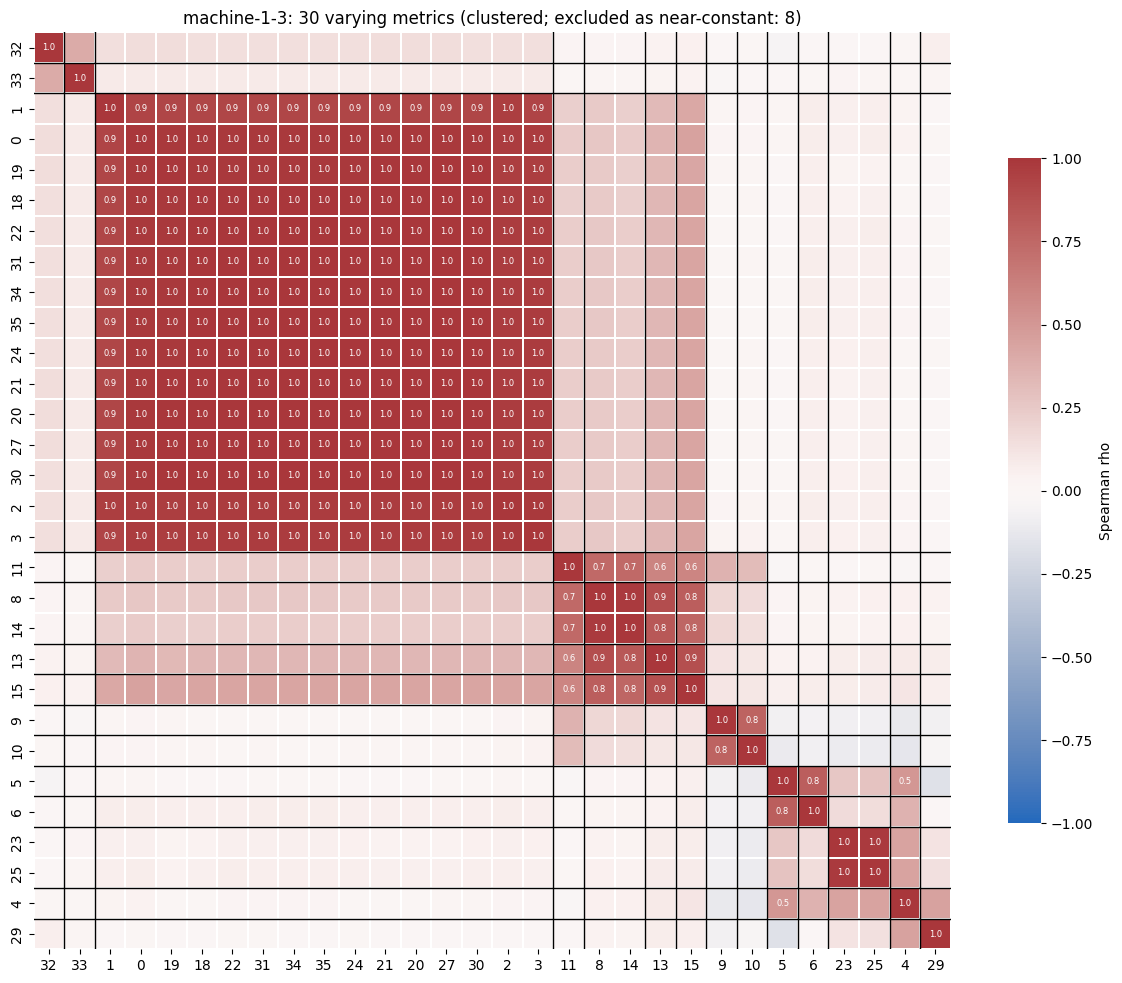

machine-1-3 excluded (near-constant): ['7', '12', '16', '17', '26', '28', '36', '37']
  group 3: ['0', '1', '2', '3', '18', '19', '20', '21', '22', '24', '27', '30', '31', '34', '35']
  group 4: ['8', '14']
  group 12: ['23', '25']


In [26]:
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, leaves_list, fcluster
from scipy.spatial.distance import squareform

def clean_corr(df, top_freq_max=0.95, method="spearman"):
    # keep only metrics that really vary (one value in <95% of rows)
    keep = [c for c in df.columns
            if df[c].nunique() > 1 and df[c].value_counts(normalize=True).iloc[0] < top_freq_max]
    dropped = [c for c in df.columns if c not in keep]
    corr = df[keep].corr(method=method).fillna(0)
    return corr, dropped

def order_and_groups(corr, cut=0.10):
    # distance = 1 - |rho|; cut=0.10 means groups with average |rho| >= ~0.9
    dist = 1 - corr.abs().values
    np.fill_diagonal(dist, 0)
    dist = (dist + dist.T) / 2
    Z = linkage(squareform(dist, checks=False), method="average")
    return leaves_list(Z), fcluster(Z, t=cut, criterion="distance")

def plot_corr(name, df, cut=0.10):
    corr, dropped = clean_corr(df)
    order, labels = order_and_groups(corr, cut)
    co = corr.iloc[order, order]
    lab_o = labels[order]
    short = [c.replace("metric_", "") for c in co.columns]

    annot = np.where(co.abs().values >= 0.5, co.round(1).astype(str).values, "")
    fig, ax = plt.subplots(figsize=(12, 10))
    sns.heatmap(co, cmap="vlag", vmin=-1, vmax=1, center=0, square=True,
                xticklabels=short, yticklabels=short,
                annot=annot, fmt="", annot_kws={"fontsize": 6},
                linewidths=0.3, linecolor="white",
                cbar_kws={"shrink": 0.7, "label": "Spearman rho"}, ax=ax)
    # outline the groups
    for i in range(1, len(lab_o)):
        if lab_o[i] != lab_o[i - 1]:
            ax.axhline(i, color="black", lw=1)
            ax.axvline(i, color="black", lw=1)
    ax.set_title(f"{name}: {len(co)} varying metrics (clustered; "
                 f"excluded as near-constant: {len(dropped)})")
    plt.tight_layout()
    plt.show()

    print(f"{name} excluded (near-constant):", [d.replace('metric_','') for d in dropped])
    for g in sorted(set(labels)):
        members = [corr.columns[i].replace("metric_", "") for i in range(len(labels)) if labels[i] == g]
        if len(members) > 1:
            print(f"  group {g}: {members}")

for name, df in data.items():
    plot_corr(name, df)

In [27]:
for name, df in data.items():
    corr, dropped = clean_corr(df)
    order, labels = order_and_groups(corr, cut=0.25)
    print(f"\n{name}")
    for g in sorted(set(labels)):
        members = [corr.columns[i].replace("metric_", "") for i in range(len(labels)) if labels[i] == g]
        print(f"  group {g}: {members}")


machine-1-1
  group 1: ['10', '15']
  group 2: ['0', '2', '3', '18', '19', '20', '21', '22', '23', '24', '25', '27', '30', '31', '34', '35']
  group 3: ['1']
  group 4: ['29']
  group 5: ['11', '12']
  group 6: ['8', '13', '14']
  group 7: ['32']
  group 8: ['5']
  group 9: ['9']
  group 10: ['6']
  group 11: ['33']

machine-1-2
  group 1: ['32', '33']
  group 2: ['24']
  group 3: ['9', '10']
  group 4: ['11']
  group 5: ['12']
  group 6: ['0', '1', '2', '3']
  group 7: ['8', '14']
  group 8: ['13', '15', '18', '19', '20', '21', '27', '30']
  group 9: ['23', '25']
  group 10: ['6']
  group 11: ['4']
  group 12: ['5']
  group 13: ['22']

machine-1-3
  group 1: ['32']
  group 2: ['33']
  group 3: ['0', '1', '2', '3', '18', '19', '20', '21', '22', '24', '27', '30', '31', '34', '35']
  group 4: ['8', '13', '14', '15']
  group 5: ['11']
  group 6: ['9', '10']
  group 7: ['5', '6']
  group 8: ['23', '25']
  group 9: ['4']
  group 10: ['29']


# **TEST**

In [28]:
import pandas as pd
import numpy as np

paths = {
    "machine-1-1": r"OmniAnomaly-master\ServerMachineDataset\test\machine-1-1.txt",   # adjust to your actual paths
    "machine-1-2": r"OmniAnomaly-master\ServerMachineDataset\test\machine-1-2.txt",
    "machine-1-3": r"OmniAnomaly-master\ServerMachineDataset\test\machine-1-3.txt",
}

cols = [f"metric_{i}" for i in range(38)]
test = {}
for name, p in paths.items():
    pop = pd.read_csv(p, header=None, names=cols)
    test[name] = pop
    print(f"{name}: shape={pop.shape}")

machine-1-1: shape=(28479, 38)
machine-1-2: shape=(23694, 38)
machine-1-3: shape=(23703, 38)


In [29]:
def inspect(name, pop):
    print(f"\n===== {name} =====")
    print("Shape:", pop.shape)
    print("Dtypes:", pop.dtypes.value_counts().to_dict())
    print("Missing values:", pop.isna().sum().sum())
    print("Duplicate rows:", pop.duplicated().sum())
    print("Constant columns:", [c for c in pop.columns if pop[c].nunique() == 1])
    print("Global min/max:", pop.min().min(), pop.max().max())

for name, pop in test.items():
    inspect(name, pop)

# Per-metric statistics for one machine
test["machine-1-1"].describe().T


===== machine-1-1 =====
Shape: (28479, 38)
Dtypes: {dtype('float64'): 38}
Missing values: 0
Duplicate rows: 0
Constant columns: ['metric_4', 'metric_7', 'metric_16', 'metric_17', 'metric_36', 'metric_37']
Global min/max: 0.0 1.0

===== machine-1-2 =====
Shape: (23694, 38)
Dtypes: {dtype('float64'): 38}
Missing values: 0
Duplicate rows: 0
Constant columns: ['metric_7', 'metric_26', 'metric_28', 'metric_36', 'metric_37']
Global min/max: 0.0 1.0

===== machine-1-3 =====
Shape: (23703, 38)
Dtypes: {dtype('float64'): 38}
Missing values: 0
Duplicate rows: 0
Constant columns: ['metric_7', 'metric_26', 'metric_36', 'metric_37']
Global min/max: 0.0 1.0


,count,mean,std,min,25%,50%,75%,max
metric_0,28479.0,0.145166,0.136204,0.010753,0.064516,0.096774,0.161290,1.000000
metric_1,28479.0,0.108322,0.102157,0.000000,0.047669,0.079449,0.131356,1.000000
metric_2,28479.0,0.107874,0.102078,0.002230,0.050167,0.080268,0.120401,1.000000
metric_3,28479.0,0.106855,0.103836,0.001161,0.048780,0.080139,0.117305,1.000000
metric_4,28479.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
metric_5,28479.0,0.915816,0.030684,0.107692,0.897436,0.907692,0.925641,1.000000
metric_6,28479.0,0.254842,0.072073,0.005650,0.248588,0.270245,0.282486,1.000000
metric_7,28479.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
metric_8,28479.0,0.023751,0.019688,0.000000,0.013625,0.024269,0.031223,1.000000
metric_9,28479.0,0.001014,0.015724,0.000000,0.000000,0.000122,0.000244,1.000000


In [30]:
summary = []
for name, pop in test.items():
    summary.append({
        "machine": name,
        "rows": pop.shape[0],
        "cols": pop.shape[1],
        "missing": int(pop.isna().sum().sum()),
        "duplicate_rows": int(pop.duplicated().sum()),
        "constant_cols": [c for c in pop.columns if pop[c].nunique() == 1],
        "n_constant": sum(pop[c].nunique() == 1 for c in pop.columns),
        "min": pop.min().min(),
        "max": pop.max().max(),
        "non_numeric_cols": int((~pop.dtypes.apply(pd.api.types.is_numeric_dtype)).sum()),
    })

summary_test = pd.DataFrame(summary).set_index("machine")
summary_test

,rows,cols,missing,duplicate_rows,constant_cols,n_constant,min,max,non_numeric_cols
machine,,,,,,,,,
machine-1-1,28479,38,0,0,"[metric_4, metric_7, metric_16, metric_17, met...",6,0.0,1.0,0
machine-1-2,23694,38,0,0,"[metric_7, metric_26, metric_28, metric_36, me...",5,0.0,1.0,0
machine-1-3,23703,38,0,0,"[metric_7, metric_26, metric_36, metric_37]",4,0.0,1.0,0


In [31]:
for name, pop in test.items():
    print(f"\n===== {name} =====")
    display(pop.describe().T.head(10))   # peek at the first 10 metrics


===== machine-1-1 =====


,count,mean,std,min,25%,50%,75%,max
metric_0,28479.0,0.145166,0.136204,0.010753,0.064516,0.096774,0.161290,1.0
metric_1,28479.0,0.108322,0.102157,0.000000,0.047669,0.079449,0.131356,1.0
metric_2,28479.0,0.107874,0.102078,0.002230,0.050167,0.080268,0.120401,1.0
metric_3,28479.0,0.106855,0.103836,0.001161,0.048780,0.080139,0.117305,1.0
metric_4,28479.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
metric_5,28479.0,0.915816,0.030684,0.107692,0.897436,0.907692,0.925641,1.0
metric_6,28479.0,0.254842,0.072073,0.005650,0.248588,0.270245,0.282486,1.0
metric_7,28479.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
metric_8,28479.0,0.023751,0.019688,0.000000,0.013625,0.024269,0.031223,1.0
metric_9,28479.0,0.001014,0.015724,0.000000,0.000000,0.000122,0.000244,1.0



===== machine-1-2 =====


,count,mean,std,min,25%,50%,75%,max
metric_0,23694.0,0.173994,0.151507,0.000000,0.050000,0.150000,0.270000,1.000000
metric_1,23694.0,0.086841,0.089469,0.000000,0.025787,0.068907,0.126189,1.000000
metric_2,23694.0,0.101265,0.093207,0.000247,0.036854,0.085580,0.149394,1.000000
metric_3,23694.0,0.106570,0.090602,0.000000,0.041524,0.094612,0.157424,1.000000
metric_4,23694.0,0.471876,0.146956,0.132075,0.358491,0.481132,0.584906,0.783019
metric_5,23694.0,0.609584,0.162802,0.000000,0.496403,0.585912,0.719147,1.000000
metric_6,23694.0,0.215991,0.120569,0.000000,0.122453,0.176664,0.265695,0.977154
metric_7,23694.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
metric_8,23694.0,0.001073,0.013556,0.000000,0.000000,0.000000,0.000187,1.000000
metric_9,23694.0,0.004041,0.025827,0.000000,0.000000,0.000005,0.000052,1.000000



===== machine-1-3 =====


,count,mean,std,min,25%,50%,75%,max
metric_0,23703.0,0.138915,0.104119,0.0,0.050505,0.111111,0.202020,1.0
metric_1,23703.0,0.008256,0.029078,0.0,0.002892,0.005618,0.010012,1.0
metric_2,23703.0,0.008935,0.030392,0.0,0.002858,0.006027,0.011061,1.0
metric_3,23703.0,0.010839,0.031529,0.0,0.003198,0.007253,0.013648,1.0
metric_4,23703.0,0.970154,0.126321,0.0,1.000000,1.000000,1.000000,1.0
metric_5,23703.0,0.564897,0.116263,0.0,0.513730,0.580822,0.644872,1.0
metric_6,23703.0,0.350439,0.060016,0.0,0.337156,0.350309,0.378779,1.0
metric_7,23703.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0
metric_8,23703.0,0.001967,0.036907,0.0,0.000119,0.000178,0.000297,1.0
metric_9,23703.0,0.000901,0.014448,0.0,0.000000,0.000000,0.000000,1.0


In [32]:
const_test = {name: {c for c in pop.columns if pop[c].nunique() == 1} for name, pop in test.items()}

for name, s in const_test.items():
    print(name, sorted(s, key=lambda x: int(x.split("_")[1])))

print("\nConstant in ALL machines:", sorted(set.intersection(*const_test.values()), key=lambda x: int(x.split("_")[1])))
print("Constant in ANY machine:", sorted(set.union(*const_test.values()), key=lambda x: int(x.split("_")[1])))

machine-1-1 ['metric_4', 'metric_7', 'metric_16', 'metric_17', 'metric_36', 'metric_37']
machine-1-2 ['metric_7', 'metric_26', 'metric_28', 'metric_36', 'metric_37']
machine-1-3 ['metric_7', 'metric_26', 'metric_36', 'metric_37']

Constant in ALL machines: ['metric_7', 'metric_36', 'metric_37']
Constant in ANY machine: ['metric_4', 'metric_7', 'metric_16', 'metric_17', 'metric_26', 'metric_28', 'metric_36', 'metric_37']


In [33]:
with open("/content/test/machine-1-1.txt") as f:
    lines = f.read().splitlines()
bad = [i for i, l in enumerate(lines) if len(l.split(",")) != 38]
print("raw lines:", len(lines), "| lines without 38 fields (0-indexed):", bad[:10])
for i in bad[:3]:
    print(i, lines[i][:200])

FileNotFoundError: [Errno 2] No such file or directory: '/content/test/machine-1-1.txt'

In [ ]:
import numpy as np

m = "machine-1-1"
train_arr = data[m].values      # train, already loaded
test_arr  = test[m].values      # test, already loaded

print("Train shape:", train_arr.shape)
print("Test shape:", test_arr.shape)
print("Any NaN in test:", np.isnan(test_arr).any())
print("Exactly identical:", np.array_equal(train_arr, test_arr))   # expect False

Train shape: (28479, 38)
Test shape: (28479, 38)
Any NaN in test: False
Exactly identical: False


In [ ]:
for name, pop in test.items():
    nunique = pop.nunique().sort_values()
    print(f"\n{name}: lowest unique counts")
    print(nunique.head(12).to_string())


machine-1-1: lowest unique counts
metric_7      1
metric_4      1
metric_17     1
metric_16     1
metric_36     1
metric_37     1
metric_26    13
metric_12    46
metric_32    61
metric_11    64
metric_0     88
metric_29    91

machine-1-2: lowest unique counts
metric_7      1
metric_28     1
metric_26     1
metric_37     1
metric_36     1
metric_29     2
metric_34     3
metric_35     3
metric_31     4
metric_32     5
metric_24     6
metric_16    13

machine-1-3: lowest unique counts
metric_7      1
metric_26     1
metric_36     1
metric_37     1
metric_28     8
metric_32     9
metric_16    14
metric_4     15
metric_12    16
metric_17    26
metric_29    40
metric_0     70


In [ ]:
def group_metrics(pop, low_thresh=20):
    nun = pop.nunique()
    dead = nun[nun == 1].index.tolist()
    low  = nun[(nun > 1) & (nun <= low_thresh)].index.tolist()
    cont = nun[nun > low_thresh].index.tolist()
    return dead, low, cont

groups_test = {}
for name, pop in test.items():
    dead, low, cont = group_metrics(pop)
    groups_test[name] = {"dead": dead, "low": low, "cont": cont}
    print(f"{name}: dead={len(dead)}, low-card={len(low)}, continuous={len(cont)}")

# What values do the low-cardinality metrics actually take?
for name, pop in test.items():
    print(f"\n{name}")
    for c in groups_test[name]["low"]:
        print(c, sorted(pop[c].round(4).unique().tolist()))

machine-1-1: dead=6, low-card=1, continuous=31
machine-1-2: dead=5, low-card=7, continuous=26
machine-1-3: dead=4, low-card=5, continuous=29

machine-1-1
metric_26 [0.0, 0.0588, 0.1176, 0.1765, 0.2353, 0.4706, 0.5882, 0.6471, 0.7059, 0.7647, 0.8235, 0.8824, 1.0]

machine-1-2
metric_16 [0.0, 0.0024, 0.0049, 0.0073, 0.0097, 0.0122, 0.0146, 0.017, 0.0195, 0.0243, 0.0268, 0.0389, 0.0608]
metric_24 [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
metric_29 [0.0, 1.0]
metric_31 [0.0, 0.3333, 0.6667, 1.0]
metric_32 [0.0, 0.25, 0.5, 0.75, 1.0]
metric_34 [0.0, 0.5, 1.0]
metric_35 [0.0, 0.5, 1.0]

machine-1-3
metric_4 [0.0, 0.0714, 0.1429, 0.2143, 0.2857, 0.3571, 0.4286, 0.5, 0.5714, 0.6429, 0.7143, 0.7857, 0.8571, 0.9286, 1.0]
metric_12 [0.0, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.08, 0.09, 0.11, 0.13, 0.3, 0.39, 0.88, 0.99, 1.0]
metric_16 [0.0, 0.0227, 0.0455, 0.0682, 0.0909, 0.1136, 0.1364, 0.1591, 0.1818, 0.2045, 0.2273, 0.3636, 0.3864, 1.0]
metric_28 [0.0, 0.0099, 0.0208, 0.0256, 0.1688, 0.2049, 0.2357, 0.340

In [ ]:
# 1) How often does each level occur in the low-card metrics?
for name, pop in test.items():
    print(f"\n===== {name} =====")
    for c in groups_test[name]["low"]:
        vc = pop[c].round(4).value_counts(normalize=True).sort_index()
        print(f"\n{c}")
        print((vc * 100).round(3).to_string())

# 2) What value do the dead columns hold?
for name, pop in test.items():
    d = groups_test[name]["dead"]
    print(name, pop[d].iloc[0].round(4).to_dict())

# 3) Per-metric range for continuous metrics (is the train max really 1.0?)
for name, pop in test.items():
    c = groups_test[name]["cont"]
    r = pop[c].agg(["min", "max", "mean", "std"]).T.round(4)
    print(f"\n{name}: continuous metrics with max < 0.5")
    print(r[r["max"] < 0.5].to_string())


===== machine-1-1 =====

metric_26
metric_26
0.0000    99.923
0.0588     0.004
0.1176     0.011
0.1765     0.011
0.2353     0.007
0.4706     0.004
0.5882     0.004
0.6471     0.004
0.7059     0.011
0.7647     0.004
0.8235     0.014
0.8824     0.004
1.0000     0.004

===== machine-1-2 =====

metric_16
metric_16
0.0000    99.683
0.0024     0.160
0.0049     0.038
0.0073     0.017
0.0097     0.021
0.0122     0.017
0.0146     0.021
0.0170     0.013
0.0195     0.013
0.0243     0.004
0.0268     0.004
0.0389     0.004
0.0608     0.004

metric_24
metric_24
0.0    84.608
0.2    14.472
0.4     0.793
0.6     0.110
0.8     0.013
1.0     0.004

metric_29
metric_29
0.0    99.992
1.0     0.008

metric_31
metric_31
0.0000    99.607
0.3333     0.384
0.6667     0.004
1.0000     0.004

metric_32
metric_32
0.00    40.445
0.25    59.310
0.50     0.224
0.75     0.017
1.00     0.004

metric_34
metric_34
0.0    99.257
0.5     0.717
1.0     0.025

metric_35
metric_35
0.0    98.949
0.5     1.026
1.0     0.025




===== machine-1-1 (continuous, sorted by skew) =====
              min     q01  median    mean     q99     max     std     skew       kurt  pct_zero  pct_outside_IQR
metric_9   0.0000  0.0000  0.0001  0.0010  0.0140  1.0000  0.0157  39.1433  1835.4542   47.6737           6.0255
metric_28  0.0000  0.0000  0.0000  0.0005  0.0000  1.0000  0.0185  38.7854  1599.4887   99.2099           0.7901
metric_32  0.0000  0.0000  0.0004  0.0008  0.0008  1.0000  0.0197  38.0410  1531.6437   42.4945           0.9410
metric_33  0.0000  0.0000  0.0000  0.0007  0.0002  1.0000  0.0203  36.3386  1385.7893    0.0000           1.5169
metric_25  0.0007  0.0025  0.0123  0.0129  0.0302  1.0000  0.0220  32.9239  1210.0705    0.0000           2.4720
metric_23  0.0014  0.0027  0.0134  0.0140  0.0323  1.0000  0.0223  32.7525  1208.7245    0.0000           2.3807
metric_29  0.0043  0.0057  0.0172  0.0219  0.0573  1.0000  0.0264  22.1446   668.7637    0.0000           0.4073
metric_8   0.0000  0.0037  0.0243  0.0238 

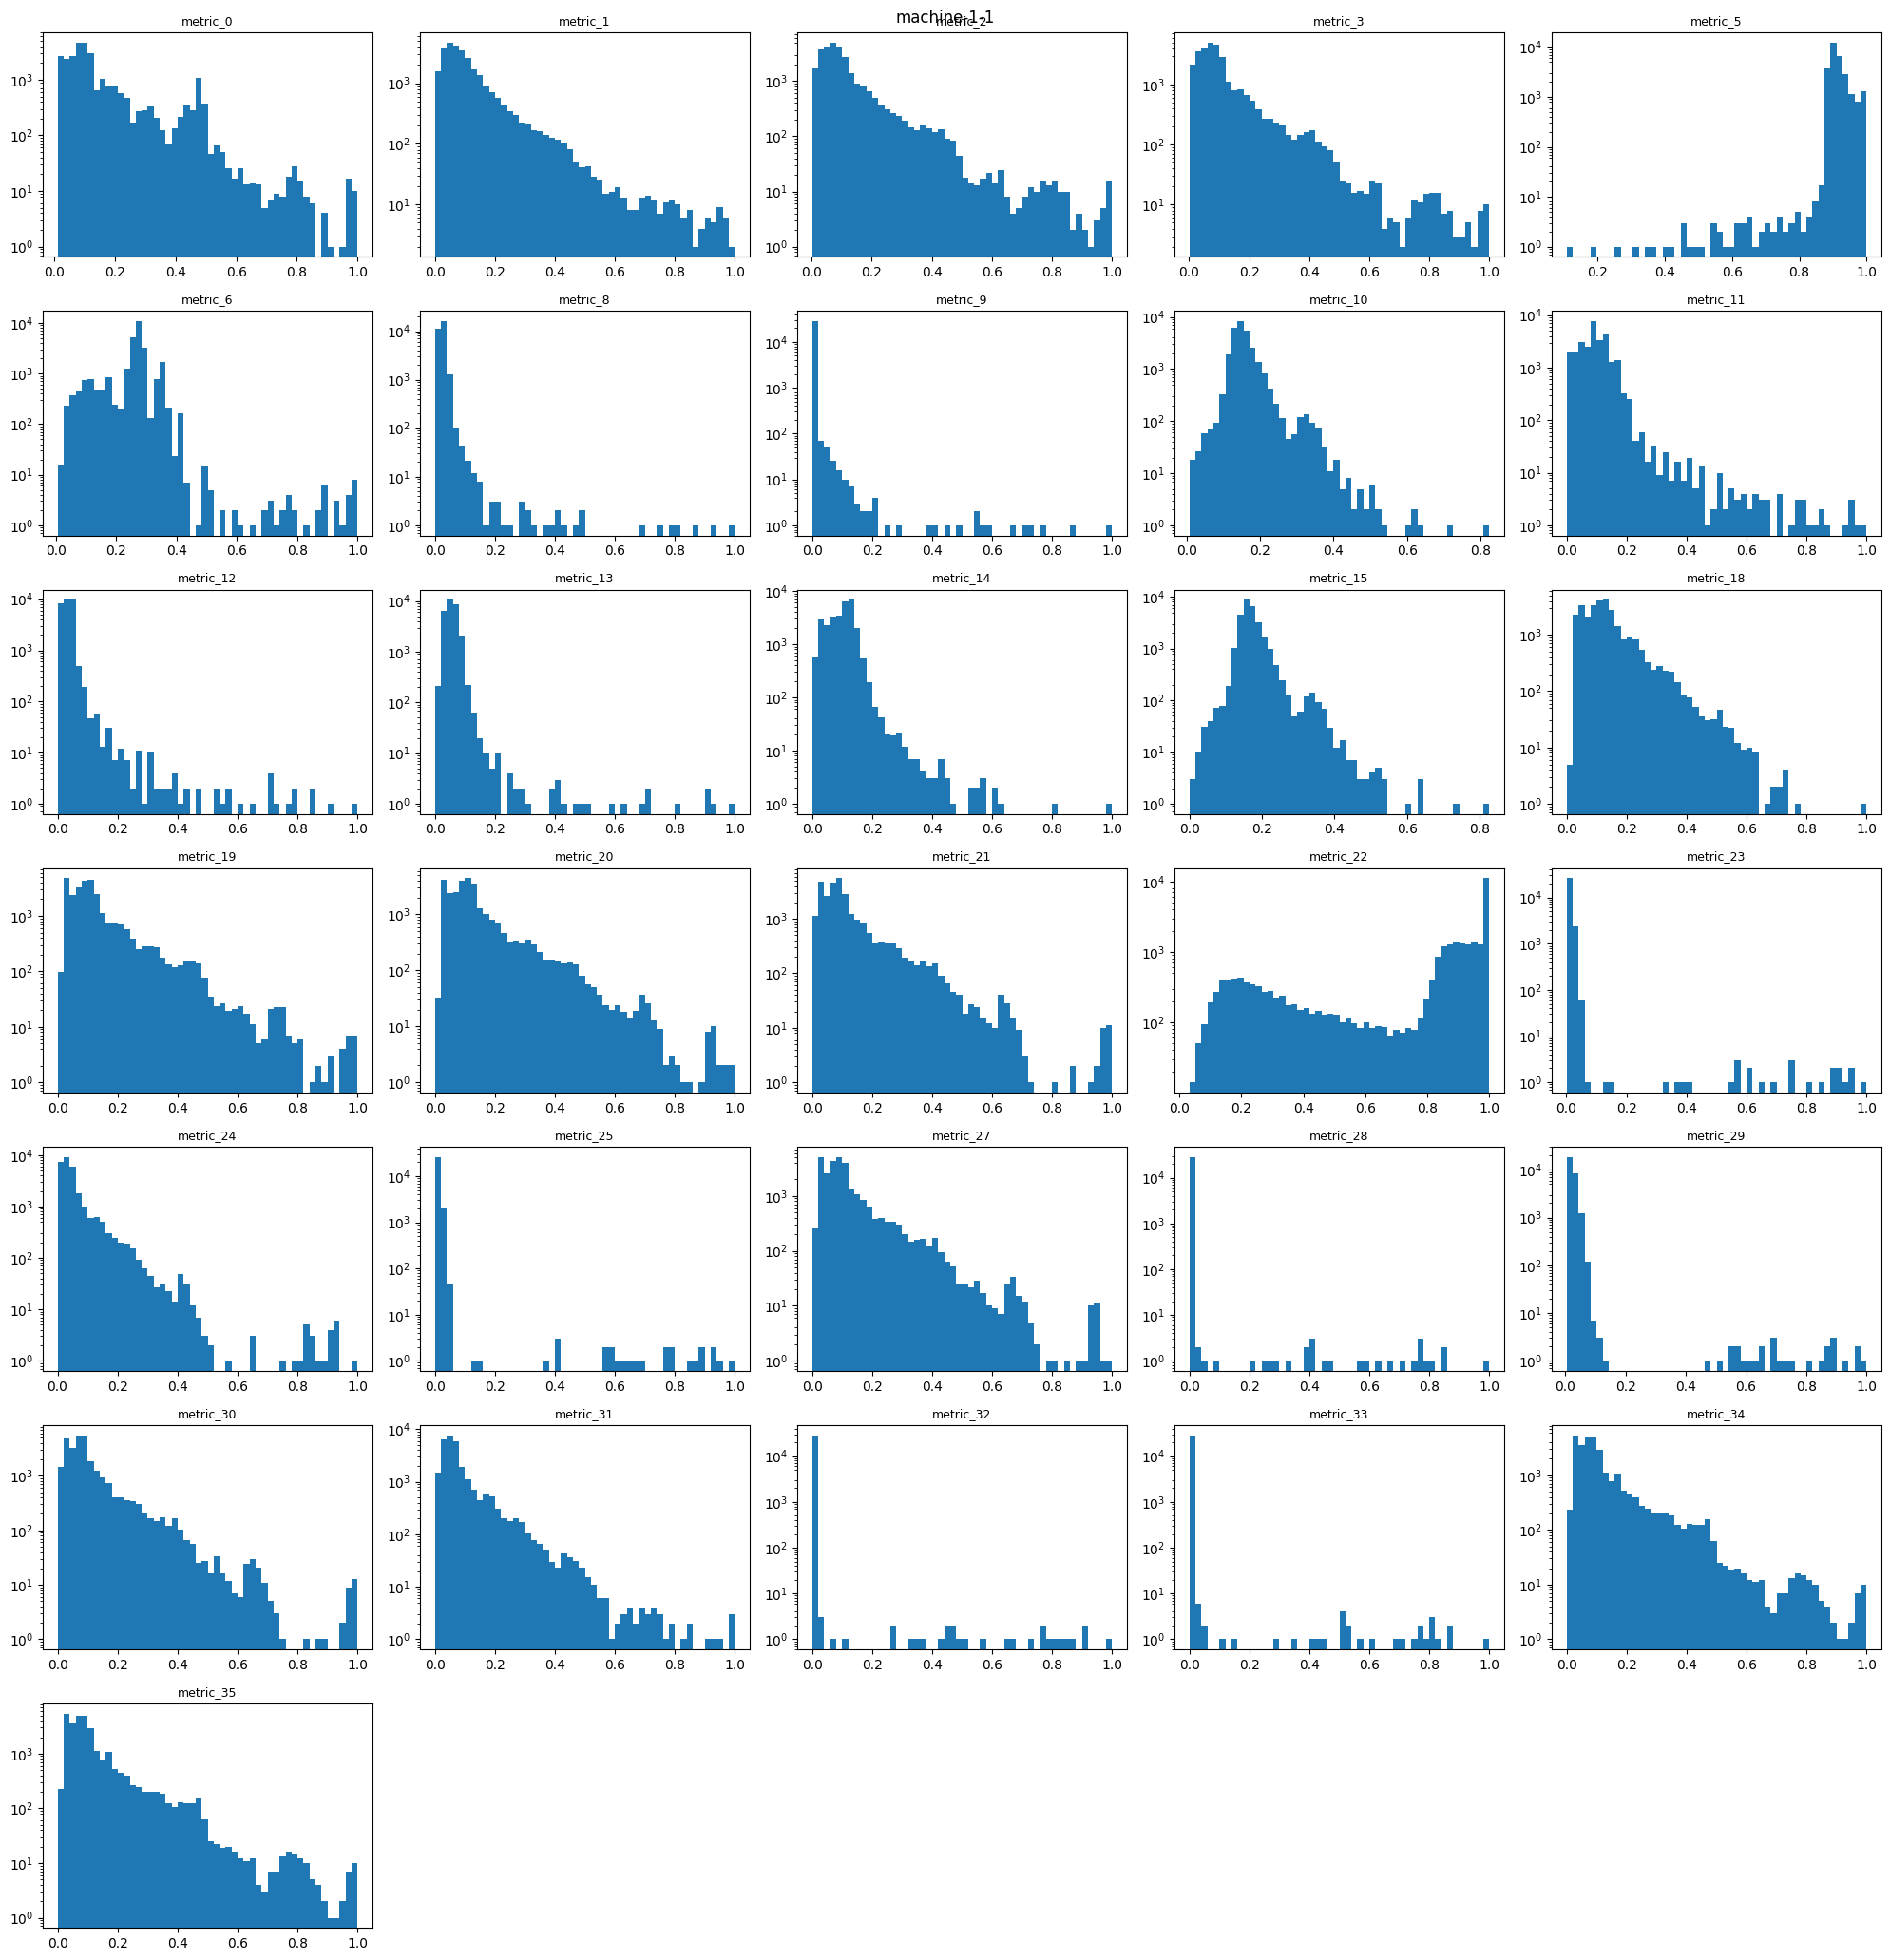

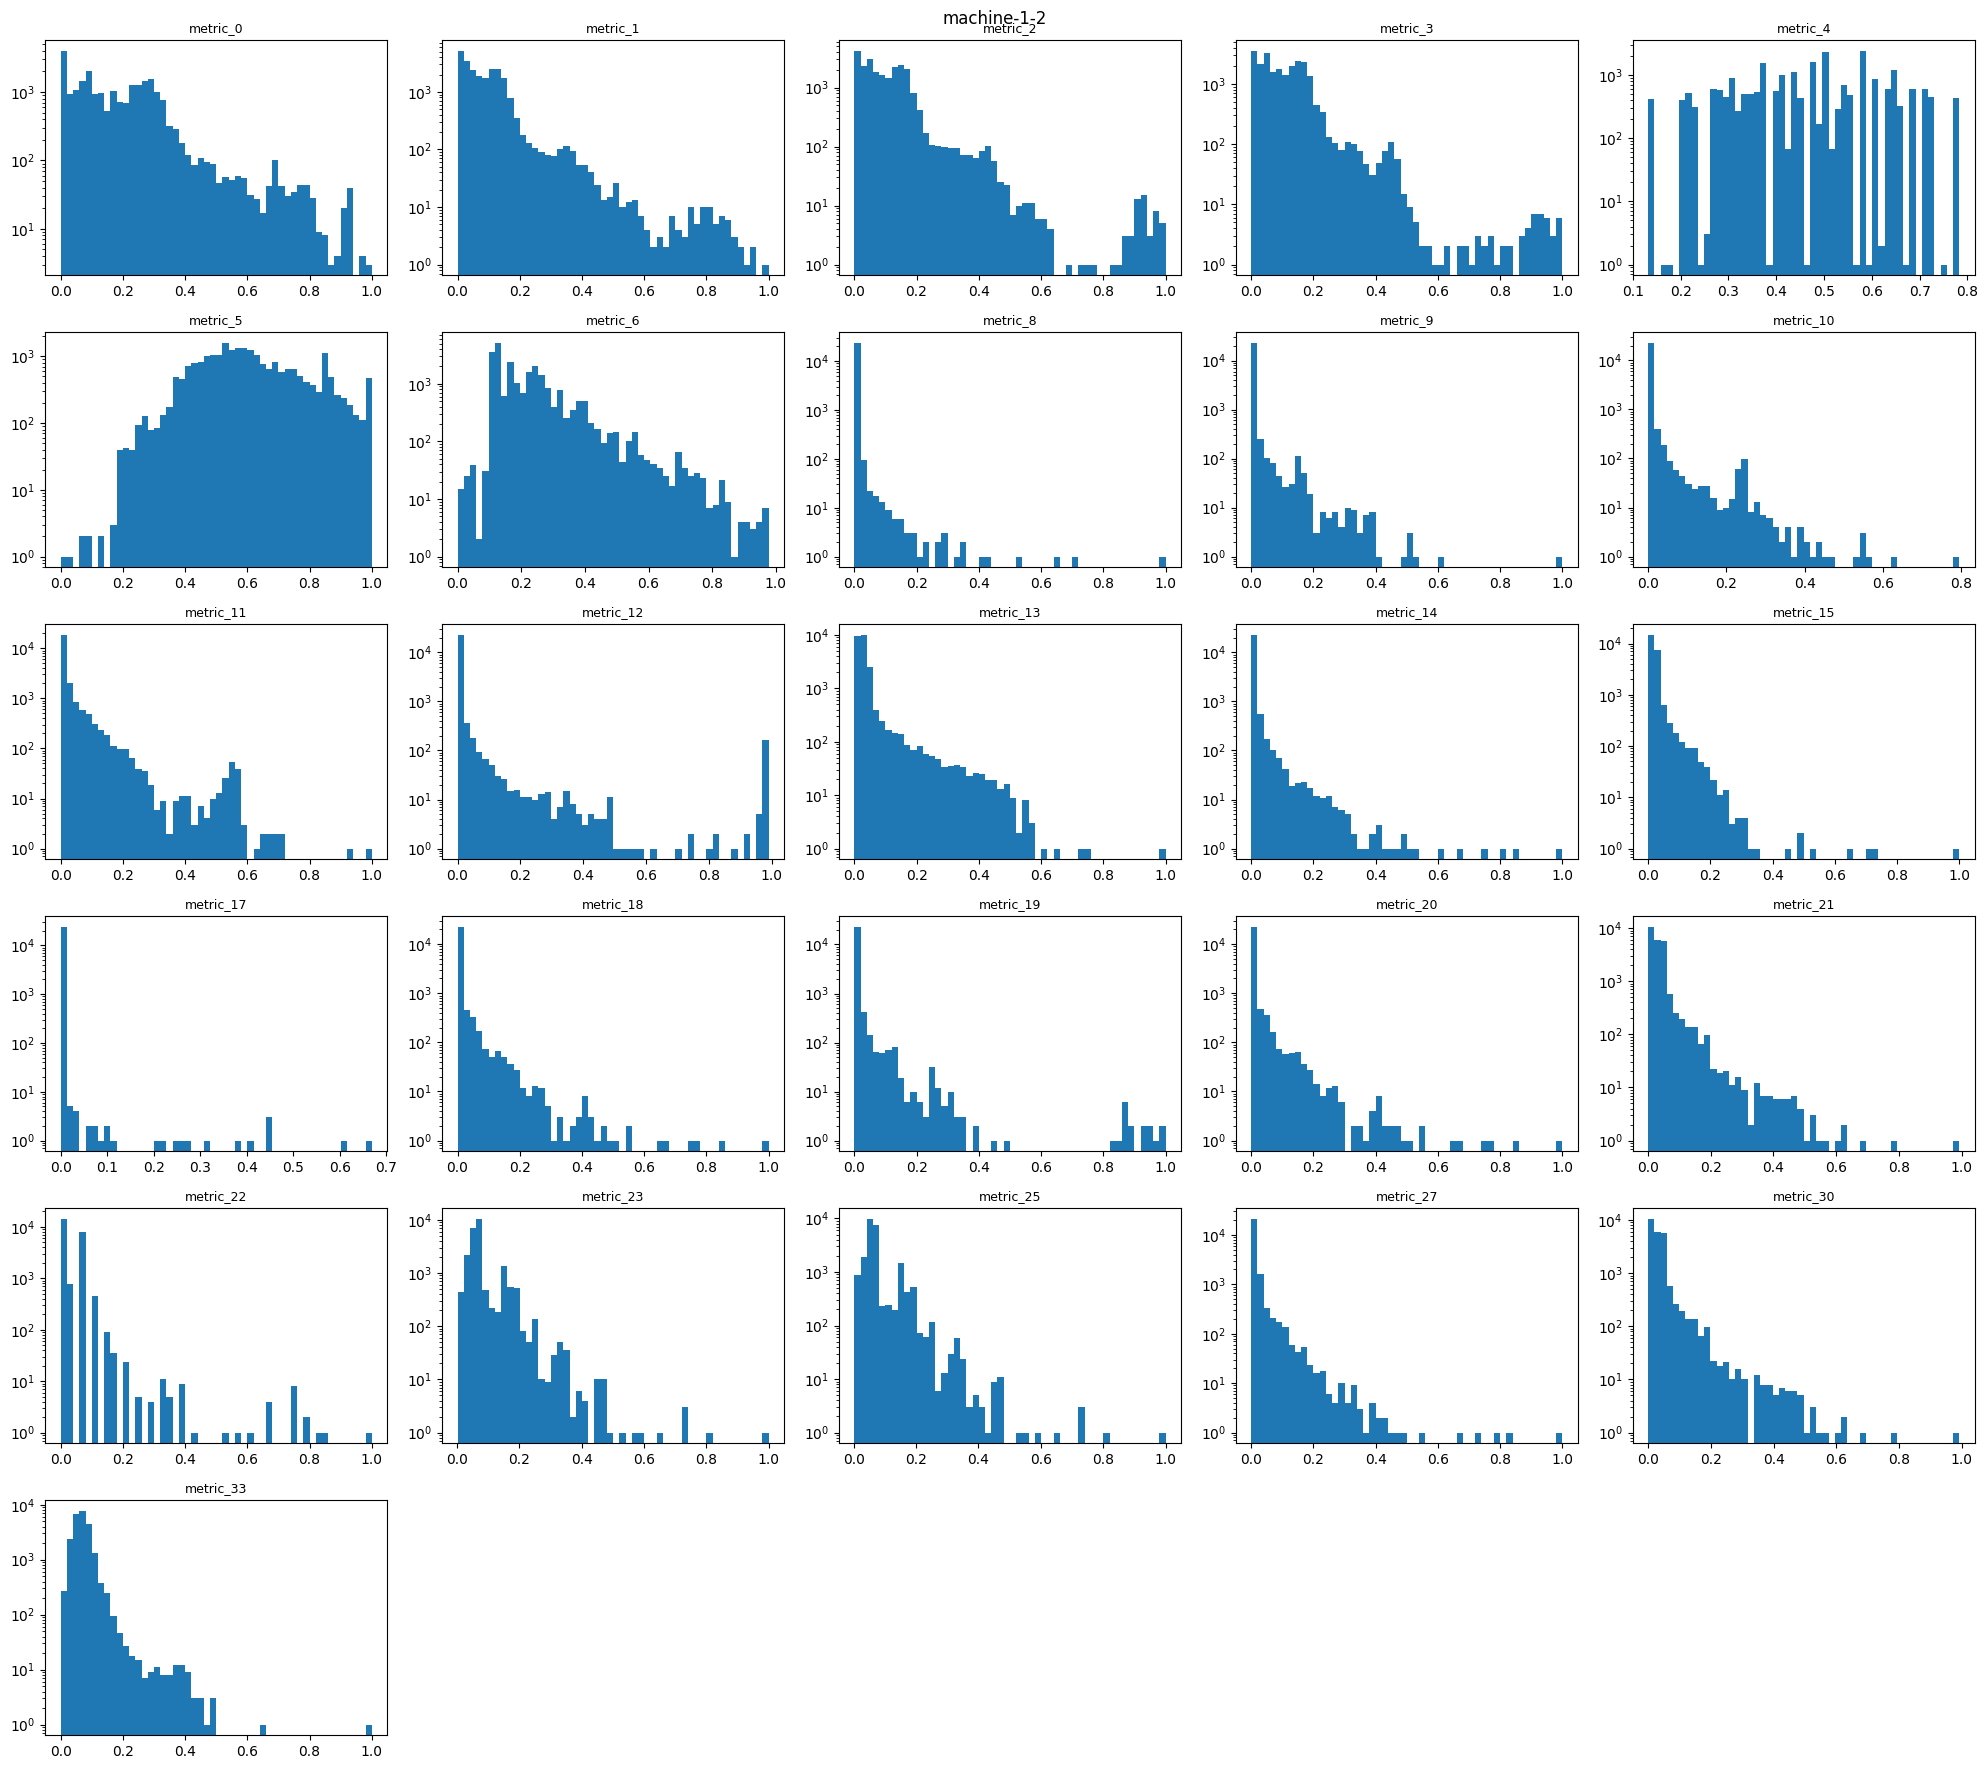

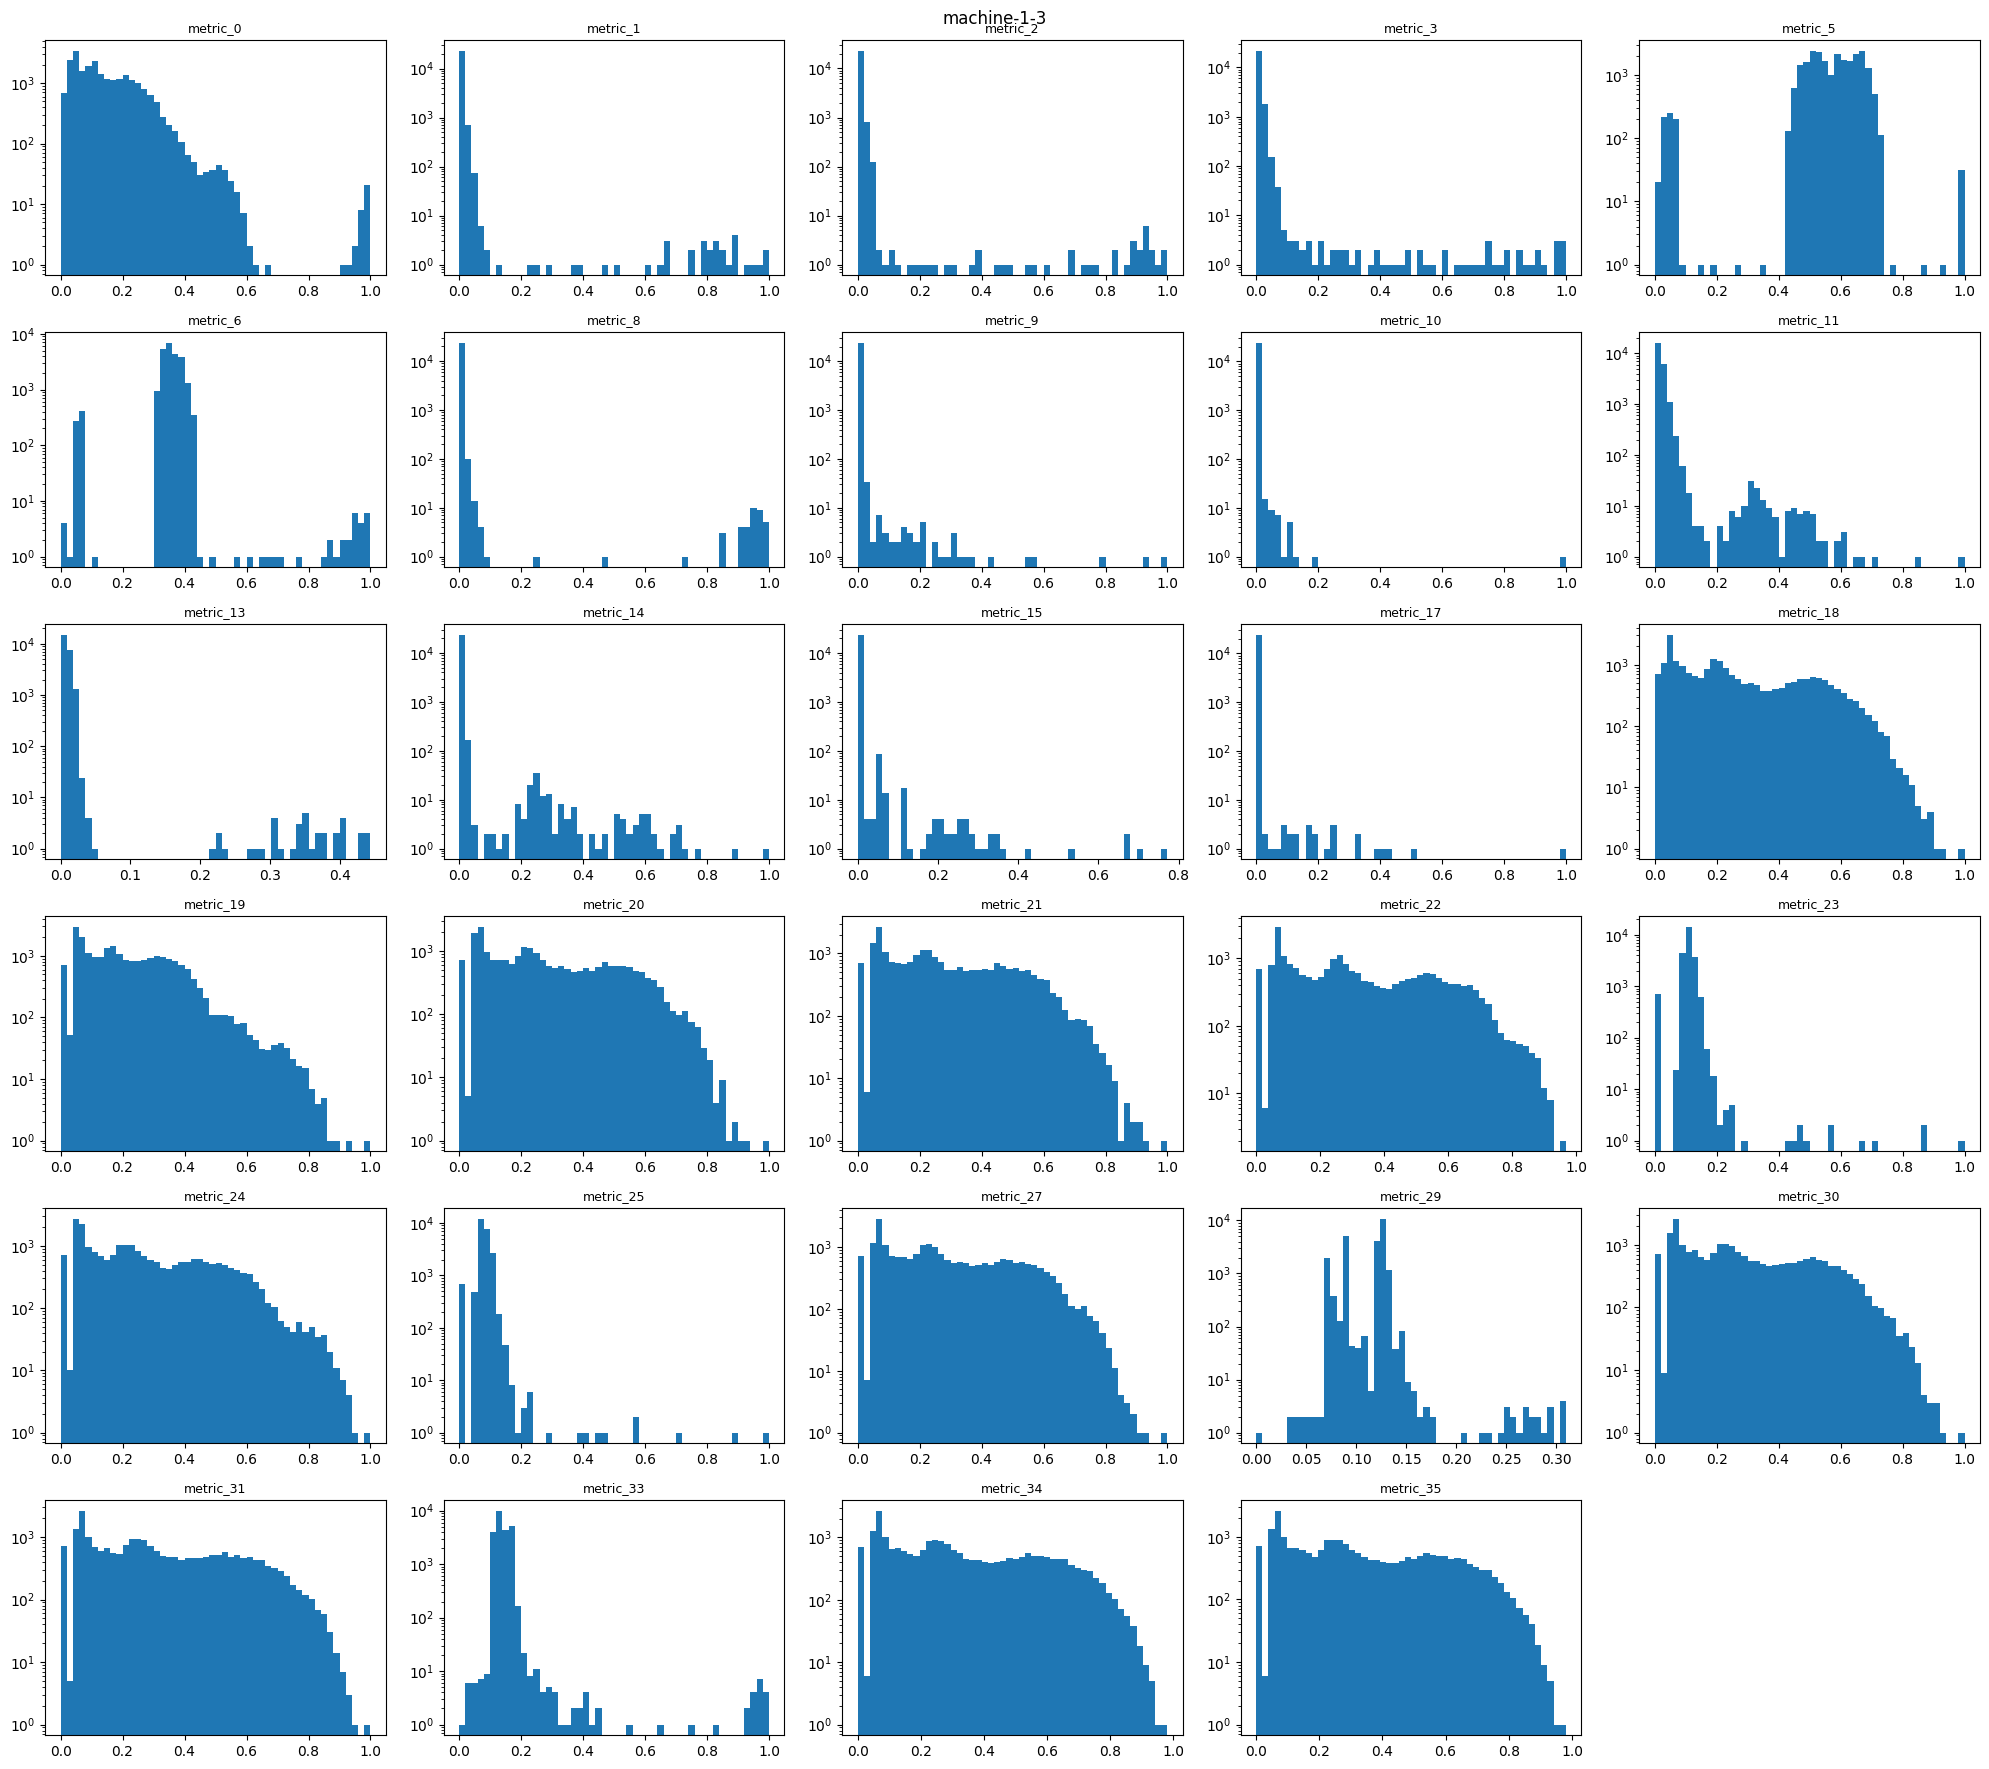

machine-1-1 identical columns: []
machine-1-2 identical columns: []
machine-1-3 identical columns: []


In [ ]:
import matplotlib.pyplot as plt

def dist_summary(pop, cols):
    x = pop[cols]
    q1, q3 = x.quantile(0.25), x.quantile(0.75)
    iqr = q3 - q1
    out = pd.DataFrame({
        "min": x.min(), "q01": x.quantile(0.01), "median": x.median(),
        "mean": x.mean(), "q99": x.quantile(0.99), "max": x.max(),
        "std": x.std(), "skew": x.skew(), "kurt": x.kurt(),
        "pct_zero": (x == 0).mean() * 100,
        "pct_outside_IQR": ((x < q1 - 1.5*iqr) | (x > q3 + 1.5*iqr)).mean() * 100,
    })
    return out.round(4)

for name, pop in test.items():
    print(f"\n===== {name} (continuous, sorted by skew) =====")
    print(dist_summary(pop, groups_test[name]["cont"]).sort_values("skew", ascending=False).to_string())

# Histograms (log y-axis so rare tails are visible)
for name, pop in test.items():
    cols = groups_test[name]["cont"]
    nrows = int(np.ceil(len(cols) / 5))
    fig, axes = plt.subplots(nrows, 5, figsize=(20, 3 * nrows))
    for ax, c in zip(axes.ravel(), cols):
        ax.hist(pop[c], bins=50)
        ax.set_yscale("log")
        ax.set_title(c, fontsize=9)
    for ax in axes.ravel()[len(cols):]:
        ax.axis("off")
    fig.suptitle(name)
    plt.tight_layout()
    plt.show()

# Exact duplicate columns among non-dead metrics
for name, pop in test.items():
    live = pop.loc[:, pop.nunique() > 1]
    dup = live.columns[live.T.duplicated(keep=False)].tolist()
    print(name, "identical columns:", dup)


machine-1-1: rows where >=5 metrics are in their top 1%: 370
top 10 rows by number of extreme metrics:
17478    28
17483    28
17484    28
17488    28
17479    27
17476    27
17475    27
17473    27
17472    27
17471    27

machine-1-2: rows where >=5 metrics are in their top 1%: 198
top 10 rows by number of extreme metrics:
17225    10
23114    10
15928     9
8373      9
2614      9
2964      9
23105     9
15597     8
5966      8
13175     8

machine-1-3: rows where >=5 metrics are in their top 1%: 438
top 10 rows by number of extreme metrics:
22999    17
22977    17
22992    16
22980    16
22993    16
22986    16
22994    16
22978    16
22981    16
22976    16

machine-1-1: rows with >=8 continuous metrics equal to 0: 1
28478    10
23297     5
13441     5
14850     5
9124      5

machine-1-2: rows with >=8 continuous metrics equal to 0: 812
3164    10
3636    10
6854    10
7672    10
4944    10

machine-1-3: rows with >=8 continuous metrics equal to 0: 4
23008    12
23007    11
2300

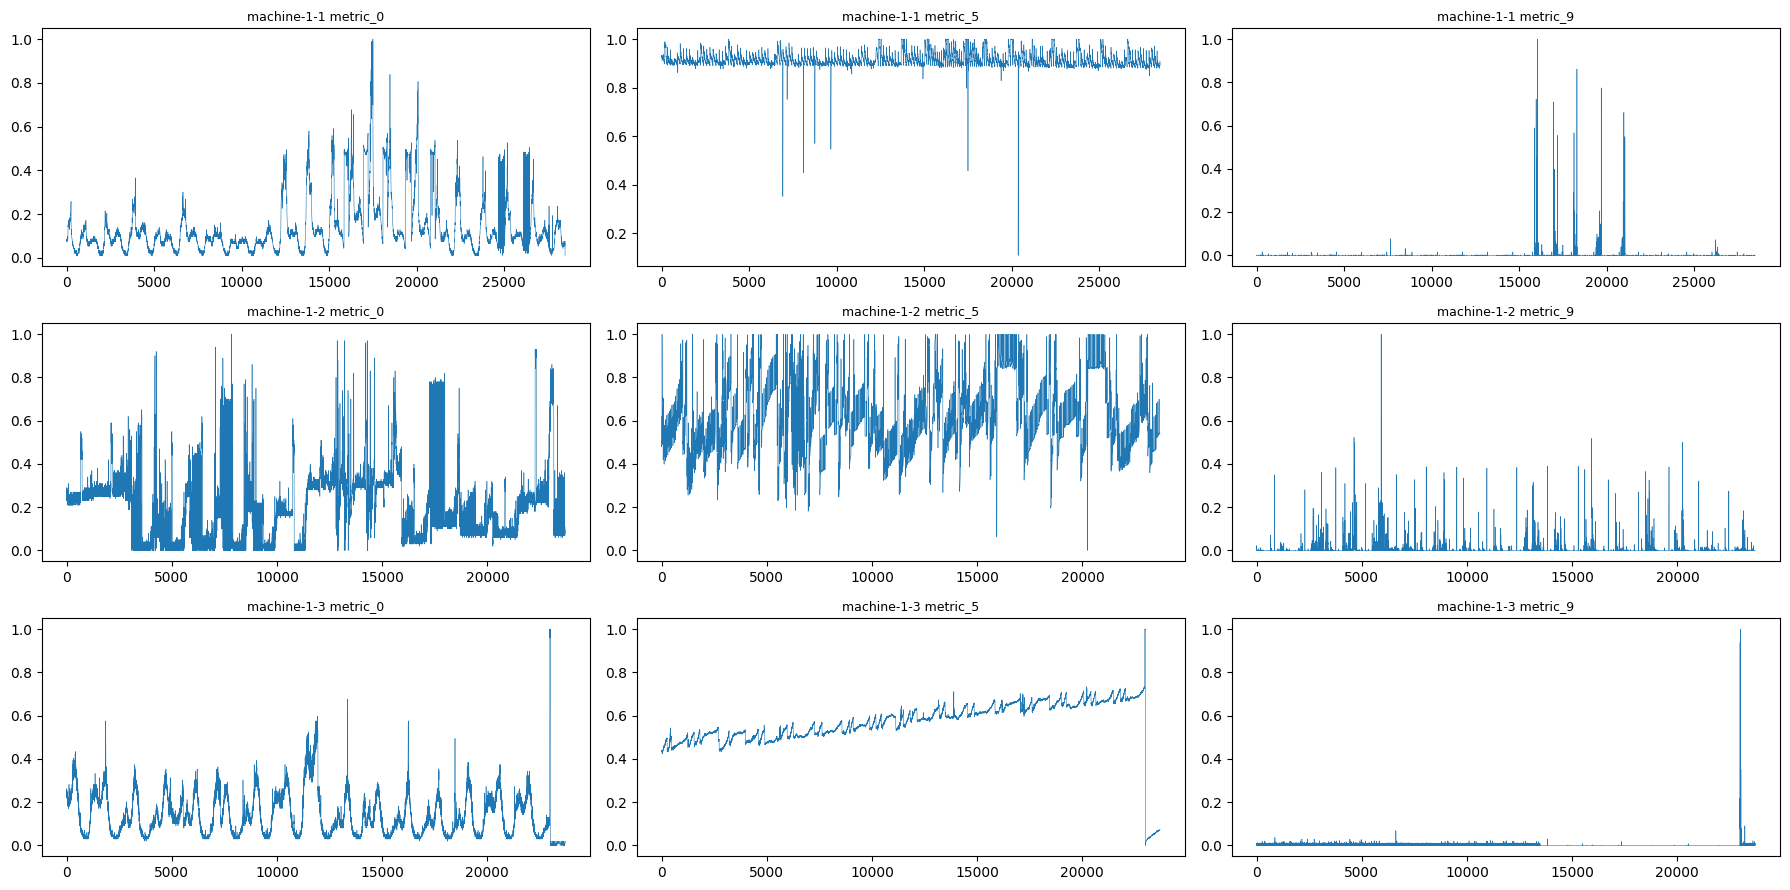

In [ ]:
# 1) Are extreme rows shared across metrics? (per machine, continuous metrics only)
for name, pop in test.items():
    cols = groups_test[name]["cont"]
    x = pop[cols]
    q99 = x.quantile(0.99)
    extreme = (x > q99)                       # per-metric top 1%
    per_row = extreme.sum(axis=1)
    print(f"\n{name}: rows where >=5 metrics are in their top 1%: {(per_row >= 5).sum()}")
    print("top 10 rows by number of extreme metrics:")
    print(per_row.sort_values(ascending=False).head(10).to_string())

# 2) Rows where many metrics hit exactly 0 (machine-1-1 suspicion)
for name, pop in test.items():
    cols = groups_test[name]["cont"]
    z = (pop[cols] == 0).sum(axis=1)
    print(f"\n{name}: rows with >=8 continuous metrics equal to 0:", (z >= 8).sum())
    print(z.sort_values(ascending=False).head(5).to_string())

# 3) Side-by-side comparison of shared continuous metrics (median, q99, std)
shared = sorted(set.intersection(*[set(g["cont"]) for g in groups_test.values()]),
                key=lambda s: int(s.split("_")[1]))
cmp_test = pd.concat({name: pop[shared].agg(["median", "std"]).T.round(4)
                 for name, pop in test.items()}, axis=1)
print("\nShared continuous metrics:", len(shared))
print(cmp_test.to_string())

# 4) Plot a few metrics over time for each machine
fig, axes = plt.subplots(3, 3, figsize=(18, 9))
for i, (name, pop) in enumerate(test.items()):
    for j, c in enumerate(["metric_0", "metric_5", "metric_9"]):
        axes[i, j].plot(pop[c].values, lw=0.4)
        axes[i, j].set_title(f"{name} {c}", fontsize=9)
plt.tight_layout(); plt.show()

machine-1-2 zero-rows: 812 in 733 runs; longest: 3
first runs: [(np.int64(3110), np.int64(3110)), (np.int64(3138), np.int64(3138)), (np.int64(3145), np.int64(3145)), (np.int64(3162), np.int64(3162)), (np.int64(3164), np.int64(3164)), (np.int64(3204), np.int64(3205)), (np.int64(3208), np.int64(3208)), (np.int64(3218), np.int64(3218)), (np.int64(3220), np.int64(3220)), (np.int64(3226), np.int64(3226))]
machine-1-1 burst windows: [(np.int64(13826), np.int64(13826)), (np.int64(13844), np.int64(13844)), (np.int64(15154), np.int64(15170)), (np.int64(15178), np.int64(15178)), (np.int64(15252), np.int64(15258)), (np.int64(16257), np.int64(16274)), (np.int64(16378), np.int64(16378)), (np.int64(16387), np.int64(16387)), (np.int64(17340), np.int64(17342)), (np.int64(17359), np.int64(17506)), (np.int64(18463), np.int64(18480)), (np.int64(18499), np.int64(18499)), (np.int64(18518), np.int64(18519)), (np.int64(20003), np.int64(20081))]
machine-1-2 burst windows: [(np.int64(66), np.int64(66)), (np.in

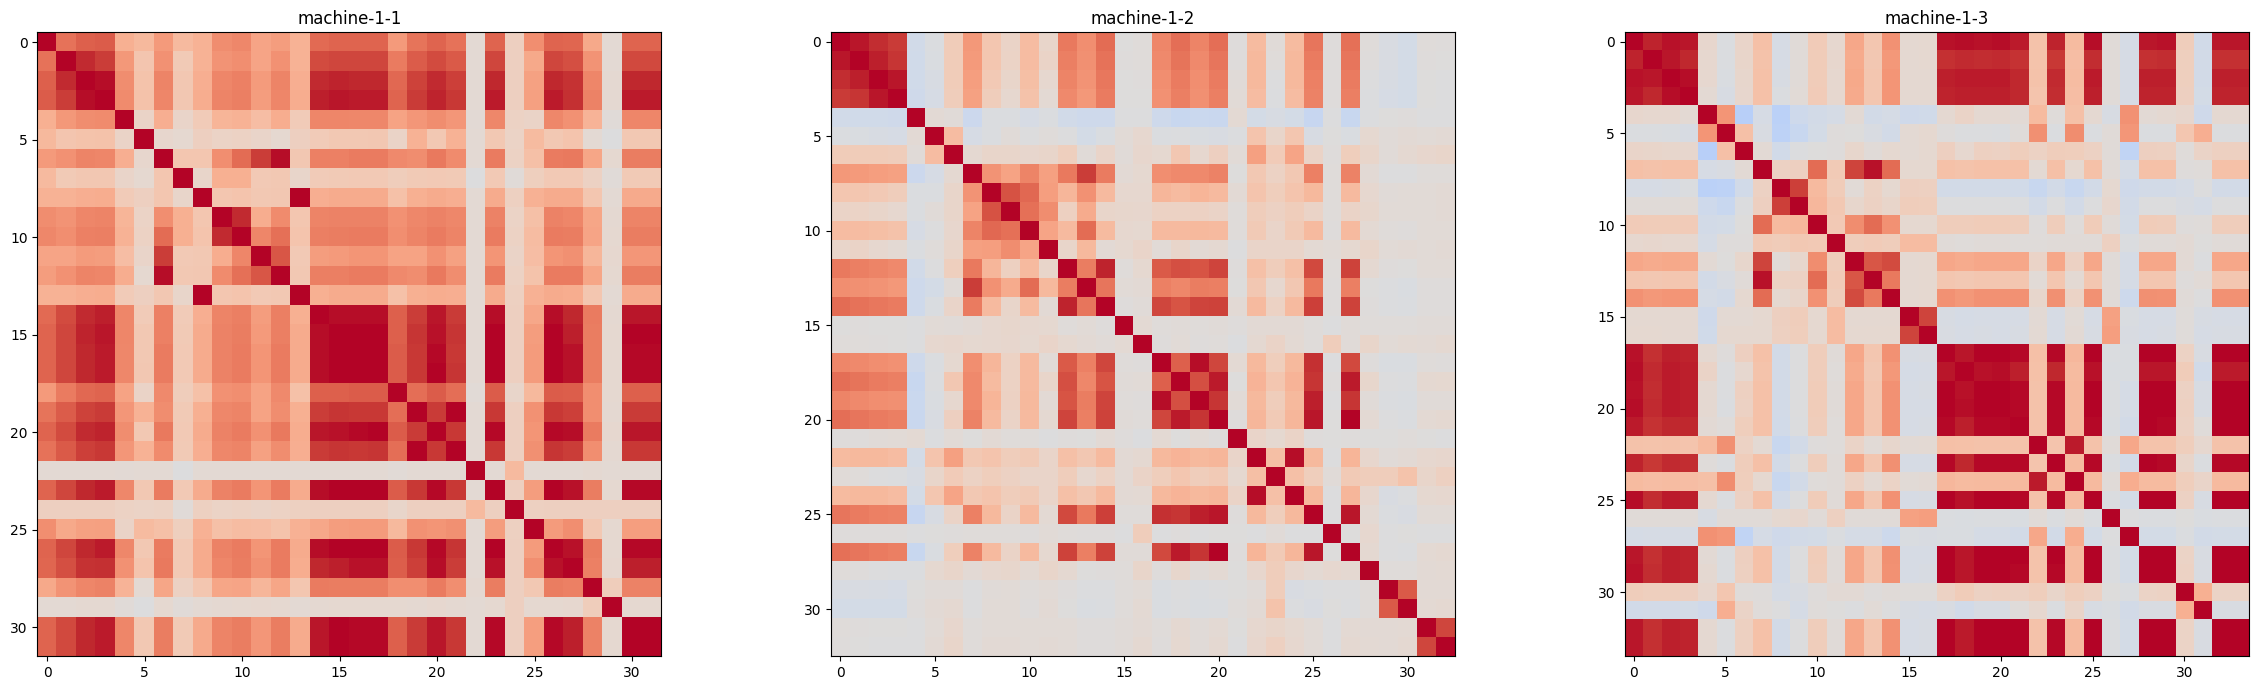

In [ ]:
# 1) Are the machine-1-2 zero rows contiguous (dropout) or scattered?
pop = test["machine-1-2"]; cols = groups_test["machine-1-2"]["cont"]
z_rows = (pop[cols] == 0).sum(axis=1) >= 8
idx = np.where(z_rows)[0]
runs = np.split(idx, np.where(np.diff(idx) != 1)[0] + 1)
print("machine-1-2 zero-rows:", len(idx), "in", len(runs), "runs; longest:", max(len(r) for r in runs))
print("first runs:", [(r[0], r[-1]) for r in runs[:10]])

# 2) Burst windows: contiguous runs of rows with >=8 metrics in top 1%
for name, d in test.items():
    c = groups_test[name]["cont"]
    ext = ((d[c] > d[c].quantile(0.99)).sum(axis=1) >= 8).values
    i = np.where(ext)[0]
    rs = np.split(i, np.where(np.diff(i) > 5)[0] + 1) if len(i) else []
    print(name, "burst windows:", [(r[0], r[-1]) for r in rs if len(r)])

# 3) Scaling check: spread of the live metrics, per machine
for name, d in test.items():
    live = d.loc[:, d.nunique() > 1]
    s = live.std()
    rng = live.quantile(0.99) - live.quantile(0.01)
    print(f"\n{name}: std min/median/max = {s.min():.4f} / {s.median():.4f} / {s.max():.4f}")
    print(f"  q99-q01 range min/median/max = {rng.min():.4f} / {rng.median():.4f} / {rng.max():.4f}")
    print("  narrowest metrics (q99-q01):", rng.sort_values().head(5).round(4).to_dict())

# 4) Correlations (Spearman, live metrics only, per machine)
for name, d in test.items():
    live = d.loc[:, d.nunique() > 1]
    corr = live.corr(method="spearman")
    pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
    high = pairs[pairs.abs() > 0.95].sort_values(ascending=False)
    print(f"\n{name}: {len(high)} pairs with |rho|>0.95 (of {len(pairs)})")
    print(high.head(15).round(3).to_string())
    print("weakest-connected metrics (mean |rho|):")
    print(corr.abs().mean().sort_values().head(5).round(3).to_dict())

# 5) Heatmaps
fig, axes = plt.subplots(1, 3, figsize=(24, 7))
for ax, (name, d) in zip(axes, test.items()):
    live = d.loc[:, d.nunique() > 1]
    ax.imshow(live.corr(method="spearman"), cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_title(name)
plt.tight_layout(); plt.show()

In [ ]:
for name, pop in test.items():
    print(f"\n===== {name} =====")
    print("dtypes:", pop.dtypes.unique())
    display(pop.head())
    display(pop.describe().T.round(4))

# Compare all 38 metrics side by side (mean and std per machine)
cmp_all_test = pd.concat({n: d.agg(["mean", "std"]).T.round(4) for n, d in test.items()}, axis=1)
display(cmp_all_test)


===== machine-1-1 =====
dtypes: [dtype('float64')]


,metric_0,metric_1,metric_2,metric_3,metric_4,metric_5,metric_6,metric_7,metric_8,metric_9,...,metric_28,metric_29,metric_30,metric_31,metric_32,metric_33,metric_34,metric_35,metric_36,metric_37
0,0.075269,0.065678,0.070234,0.074332,0.0,0.933333,0.274011,0.0,0.031081,0.000000,...,0.0,0.008596,0.068036,0.048893,0.000386,0.000034,0.064432,0.064500,0.0,0.0
1,0.086022,0.080508,0.075808,0.076655,0.0,0.930769,0.274953,0.0,0.031081,0.000122,...,0.0,0.008596,0.070020,0.050437,0.000386,0.000022,0.065228,0.065224,0.0,0.0
2,0.075269,0.064619,0.071349,0.074332,0.0,0.928205,0.274953,0.0,0.030940,0.000366,...,0.0,0.008596,0.069684,0.055069,0.000386,0.000045,0.067111,0.067178,0.0,0.0
3,0.086022,0.048729,0.063545,0.070848,0.0,0.928205,0.273070,0.0,0.027250,0.000244,...,0.0,0.010029,0.073253,0.051467,0.000000,0.000034,0.066676,0.066744,0.0,0.0
4,0.086022,0.051907,0.062430,0.070848,0.0,0.933333,0.274011,0.0,0.030940,0.000244,...,0.0,0.008596,0.070932,0.051467,0.000386,0.000022,0.066604,0.066671,0.0,0.0


,count,mean,std,min,25%,50%,75%,max
metric_0,28479.0,0.1452,0.1362,0.0108,0.0645,0.0968,0.1613,1.0000
metric_1,28479.0,0.1083,0.1022,0.0000,0.0477,0.0794,0.1314,1.0000
metric_2,28479.0,0.1079,0.1021,0.0022,0.0502,0.0803,0.1204,1.0000
metric_3,28479.0,0.1069,0.1038,0.0012,0.0488,0.0801,0.1173,1.0000
metric_4,28479.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
metric_5,28479.0,0.9158,0.0307,0.1077,0.8974,0.9077,0.9256,1.0000
metric_6,28479.0,0.2548,0.0721,0.0056,0.2486,0.2702,0.2825,1.0000
metric_7,28479.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
metric_8,28479.0,0.0238,0.0197,0.0000,0.0136,0.0243,0.0312,1.0000
metric_9,28479.0,0.0010,0.0157,0.0000,0.0000,0.0001,0.0002,1.0000



===== machine-1-2 =====
dtypes: [dtype('float64')]


,metric_0,metric_1,metric_2,metric_3,metric_4,metric_5,metric_6,metric_7,metric_8,metric_9,...,metric_28,metric_29,metric_30,metric_31,metric_32,metric_33,metric_34,metric_35,metric_36,metric_37
0,0.23,0.109491,0.126639,0.133771,0.226415,0.621045,0.409283,0.0,0.000093,0.000015,...,0.0,0.0,0.048009,0.0,0.00,0.062500,0.0,0.0,0.0,0.0
1,0.25,0.108856,0.127133,0.134034,0.226415,0.547274,0.336979,0.0,0.000093,0.000015,...,0.0,0.0,0.075177,0.0,0.00,0.055556,0.0,0.5,0.0,0.0
2,0.24,0.122807,0.130843,0.135348,0.226415,0.478450,0.264758,0.0,0.000653,0.000134,...,0.0,0.0,0.212877,0.0,0.00,0.069444,0.0,0.0,0.0,0.0
3,0.23,0.109279,0.128617,0.134823,0.226415,0.484109,0.264840,0.0,0.001026,0.000134,...,0.0,0.0,0.046148,0.0,0.25,0.090278,0.0,0.0,0.0,0.0
4,0.24,0.096174,0.125402,0.133771,0.226415,0.484959,0.264939,0.0,0.000187,0.000015,...,0.0,0.0,0.047637,0.0,0.00,0.055556,0.0,0.0,0.0,0.0


,count,mean,std,min,25%,50%,75%,max
metric_0,23694.0,0.1740,0.1515,0.0000,0.0500,0.1500,0.2700,1.0000
metric_1,23694.0,0.0868,0.0895,0.0000,0.0258,0.0689,0.1262,1.0000
metric_2,23694.0,0.1013,0.0932,0.0002,0.0369,0.0856,0.1494,1.0000
metric_3,23694.0,0.1066,0.0906,0.0000,0.0415,0.0946,0.1574,1.0000
metric_4,23694.0,0.4719,0.1470,0.1321,0.3585,0.4811,0.5849,0.7830
metric_5,23694.0,0.6096,0.1628,0.0000,0.4964,0.5859,0.7191,1.0000
metric_6,23694.0,0.2160,0.1206,0.0000,0.1225,0.1767,0.2657,0.9772
metric_7,23694.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
metric_8,23694.0,0.0011,0.0136,0.0000,0.0000,0.0000,0.0002,1.0000
metric_9,23694.0,0.0040,0.0258,0.0000,0.0000,0.0000,0.0001,1.0000



===== machine-1-3 =====
dtypes: [dtype('float64')]


,metric_0,metric_1,metric_2,metric_3,metric_4,metric_5,metric_6,metric_7,metric_8,metric_9,...,metric_28,metric_29,metric_30,metric_31,metric_32,metric_33,metric_34,metric_35,metric_36,metric_37
0,0.242424,0.013906,0.014913,0.017392,0.928571,0.435060,0.374048,0.0,0.002196,0.000394,...,0.0,0.077381,0.592839,0.626794,0.000,0.145695,0.636397,0.635967,0.0,0.0
1,0.242424,0.013850,0.014789,0.017392,0.928571,0.437287,0.376373,0.0,0.000119,0.000000,...,0.0,0.077381,0.571573,0.600000,0.000,0.139073,0.610033,0.609756,0.0,0.0
2,0.222222,0.013906,0.014975,0.017548,0.928571,0.436025,0.374930,0.0,0.000178,0.000000,...,0.0,0.077381,0.563497,0.605742,0.000,0.145695,0.610399,0.610120,0.0,0.0
3,0.232323,0.009957,0.013733,0.017080,0.928571,0.434689,0.373406,0.0,0.000178,0.000000,...,0.0,0.077381,0.569554,0.606699,0.000,0.125828,0.614061,0.613760,0.0,0.0
4,0.232323,0.009734,0.013236,0.016924,0.928571,0.435283,0.373967,0.0,0.000297,0.000000,...,0.0,0.077381,0.571236,0.604785,0.125,0.119205,0.610033,0.609392,0.0,0.0


,count,mean,std,min,25%,50%,75%,max
metric_0,23703.0,0.1389,0.1041,0.0000,0.0505,0.1111,0.2020,1.0000
metric_1,23703.0,0.0083,0.0291,0.0000,0.0029,0.0056,0.0100,1.0000
metric_2,23703.0,0.0089,0.0304,0.0000,0.0029,0.0060,0.0111,1.0000
metric_3,23703.0,0.0108,0.0315,0.0000,0.0032,0.0073,0.0136,1.0000
metric_4,23703.0,0.9702,0.1263,0.0000,1.0000,1.0000,1.0000,1.0000
metric_5,23703.0,0.5649,0.1163,0.0000,0.5137,0.5808,0.6449,1.0000
metric_6,23703.0,0.3504,0.0600,0.0000,0.3372,0.3503,0.3788,1.0000
metric_7,23703.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
metric_8,23703.0,0.0020,0.0369,0.0000,0.0001,0.0002,0.0003,1.0000
metric_9,23703.0,0.0009,0.0144,0.0000,0.0000,0.0000,0.0000,1.0000


machine-1-1         machine-1-2         machine-1-3        
                 mean     std        mean     std        mean     std
metric_0       0.1452  0.1362      0.1740  0.1515      0.1389  0.1041
metric_1       0.1083  0.1022      0.0868  0.0895      0.0083  0.0291
metric_2       0.1079  0.1021      0.1013  0.0932      0.0089  0.0304
metric_3       0.1069  0.1038      0.1066  0.0906      0.0108  0.0315
metric_4       0.0000  0.0000      0.4719  0.1470      0.9702  0.1263
metric_5       0.9158  0.0307      0.6096  0.1628      0.5649  0.1163
metric_6       0.2548  0.0721      0.2160  0.1206      0.3504  0.0600
metric_7       0.0000  0.0000      0.0000  0.0000      0.0000  0.0000
metric_8       0.0238  0.0197      0.0011  0.0136      0.0020  0.0369
metric_9       0.0010  0.0157      0.0040  0.0258      0.0009  0.0144
metric_10      0.1565  0.0398      0.0051  0.0304      0.0002  0.0071
metric_11      0.0929  0.0555      0.0262  0.0606      0.0222  0.0337
metric_12      0.0303  0.0287      0.0114  0.0883      0.0019  0.0390
metric_13      0.0556  0.0246      0.0351  0.0528      0.0096  0.0137
metric_14      0.0993  0.0431      0.0070  0.0244      0.0069  0.0316
metric_15      0.1717  0.0395      0.0181  0.0277      0.0026  0.0150
metric_16      0.0000  0.0000      0.0000  0.0007      0.0002  0.0087
metric_17      0.0000  0.0000      0.0003  0.0096      0.0003  0.0102
metric_18      0.1287  0.0818      0.0063  0.0280      0.2666  0.2011
metric_19      0.1219  0.1046      0.0099  0.0316      0.2135  0.1452
metric_20      0.1288  0.1064      0.0081  0.0280      0.2830  0.1961
metric_21      0.1056  0.0957      0.0315  0.0379      0.2776  0.1895
metric_22      0.8011  0.2865      0.0297  0.0438      0.3104  0.2159
metric_23      0.0140  0.0223      0.0762  0.0476      0.1074  0.0257
metric_24      0.0517  0.0617      0.0329  0.0806      0.2685  0.1950
metric_25      0.0129  0.0220      0.0734  0.0475      0.0793  0.0223
metric_26      0.0004  0.0166      0.0000  0.0000      0.0000  0.0000
metric_27      0.1095  0.0951      0.0149  0.0278      0.2872  0.1954
metric_28      0.0005  0.0185      0.0000  0.0000      0.0000  0.0032
metric_29      0.0219  0.0264      0.0001  0.0092      0.1113  0.0202
metric_30      0.0989  0.0923      0.0313  0.0379      0.2874  0.1992
metric_31      0.0750  0.0713      0.0014  0.0220      0.3148  0.2203
metric_32      0.0008  0.0197      0.1496  0.1241      0.0367  0.0607
metric_33      0.0007  0.0203      0.0689  0.0334      0.1419  0.0320
metric_34      0.1079  0.1022      0.0038  0.0451      0.3213  0.2271
metric_35      0.1079  0.1021      0.0054  0.0528      0.3212  0.2273
metric_36      0.0000  0.0000      0.0000  0.0000      0.0000  0.0000
metric_37      0.0000  0.0000      0.0000  0.0000      0.0000  0.0000

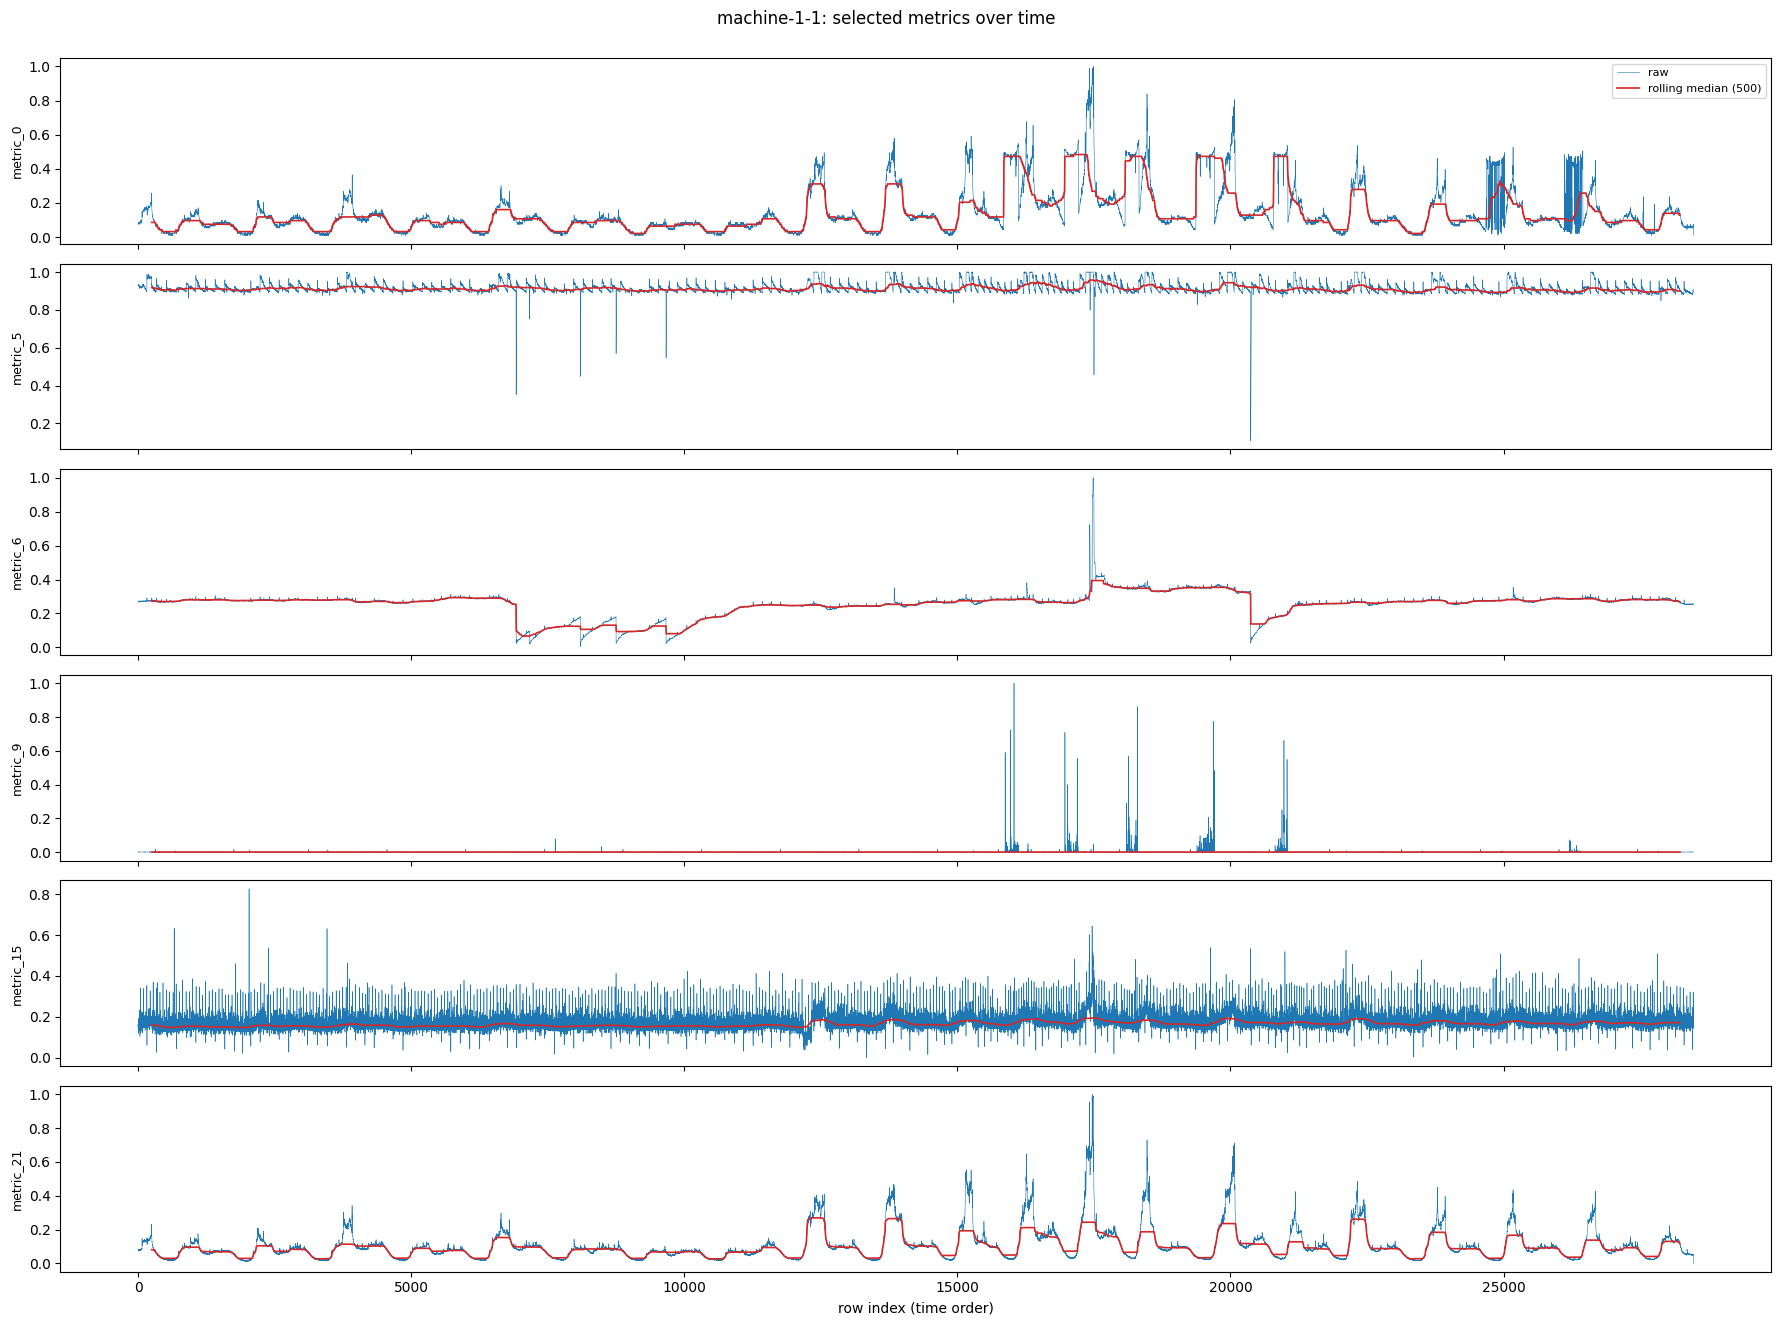

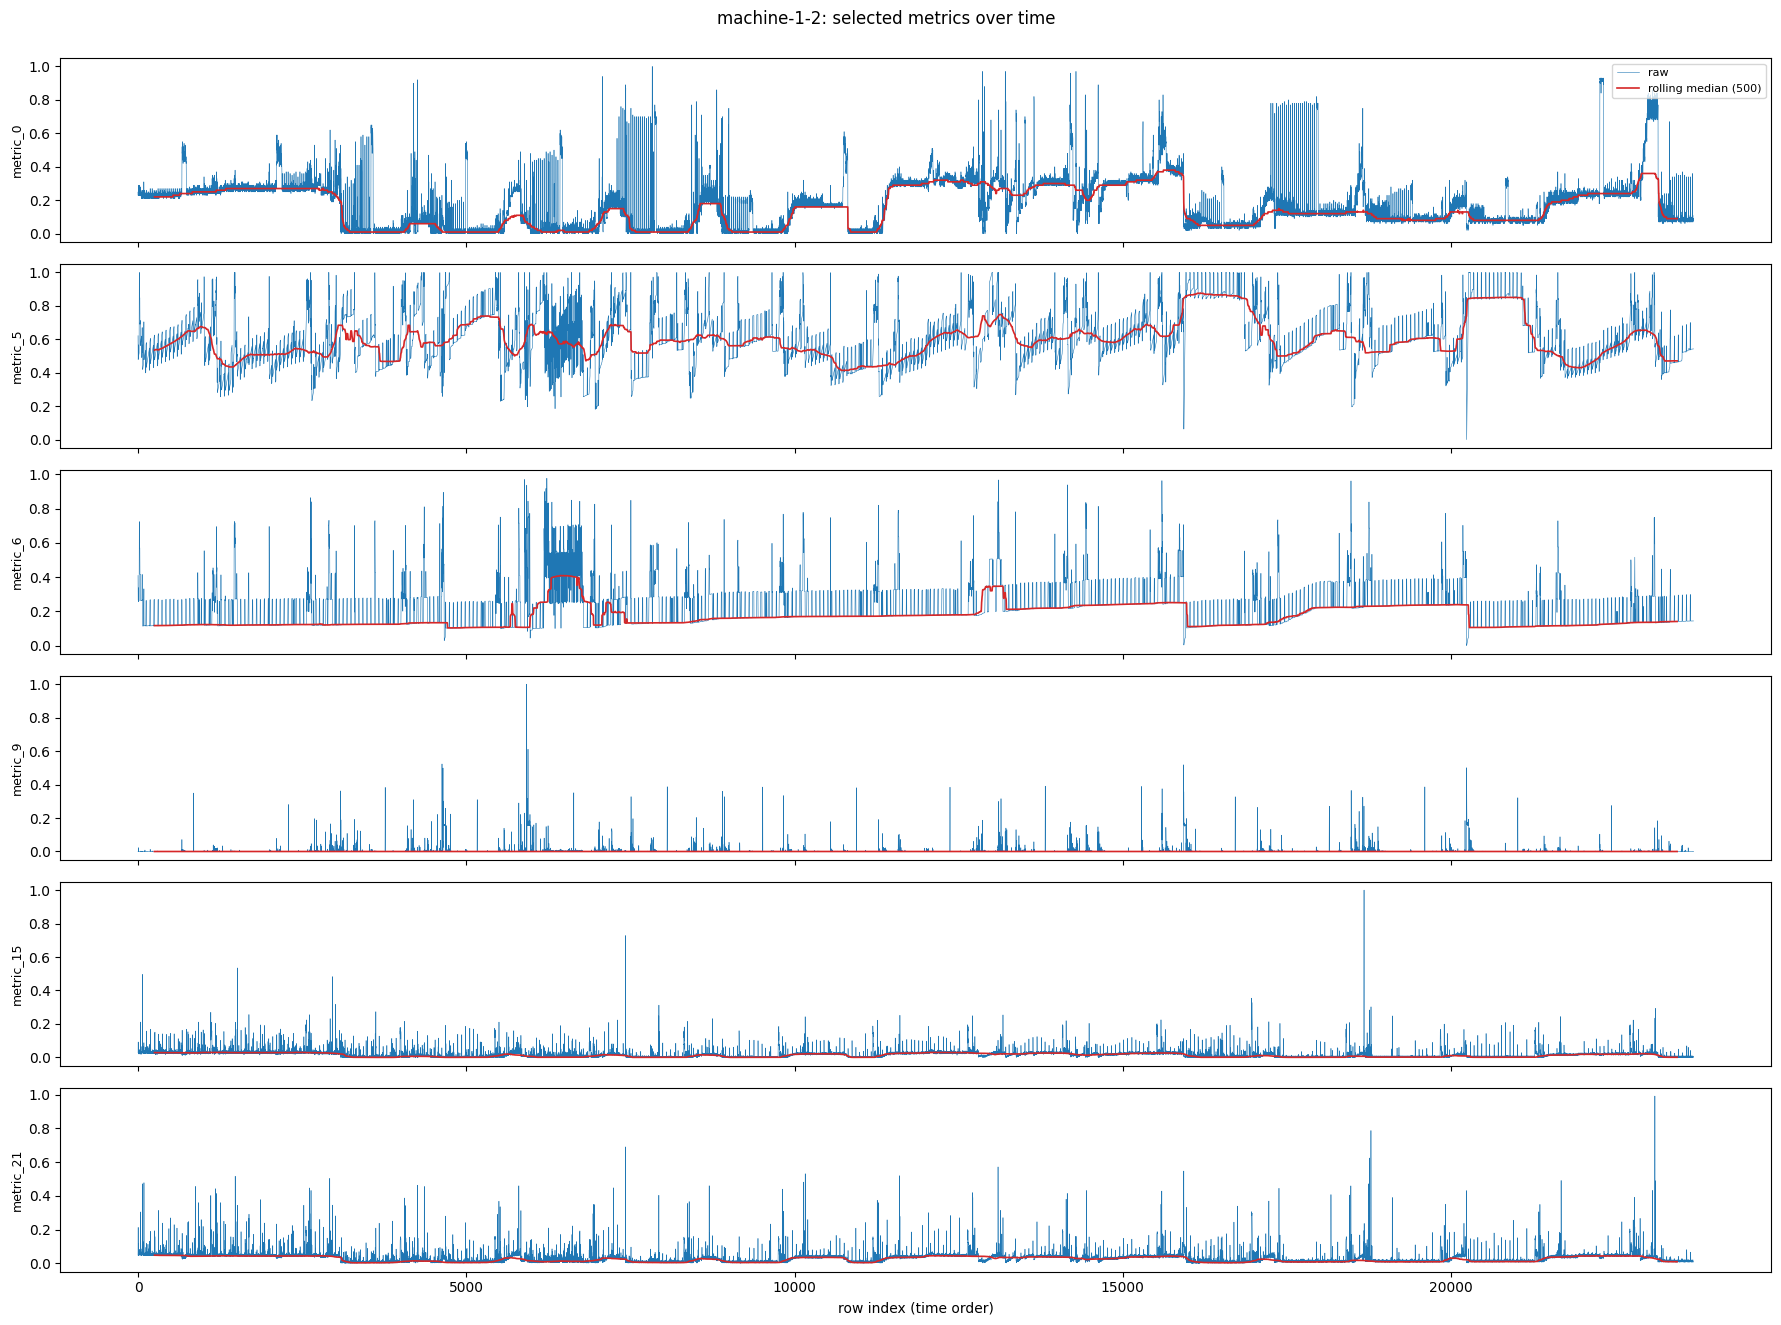

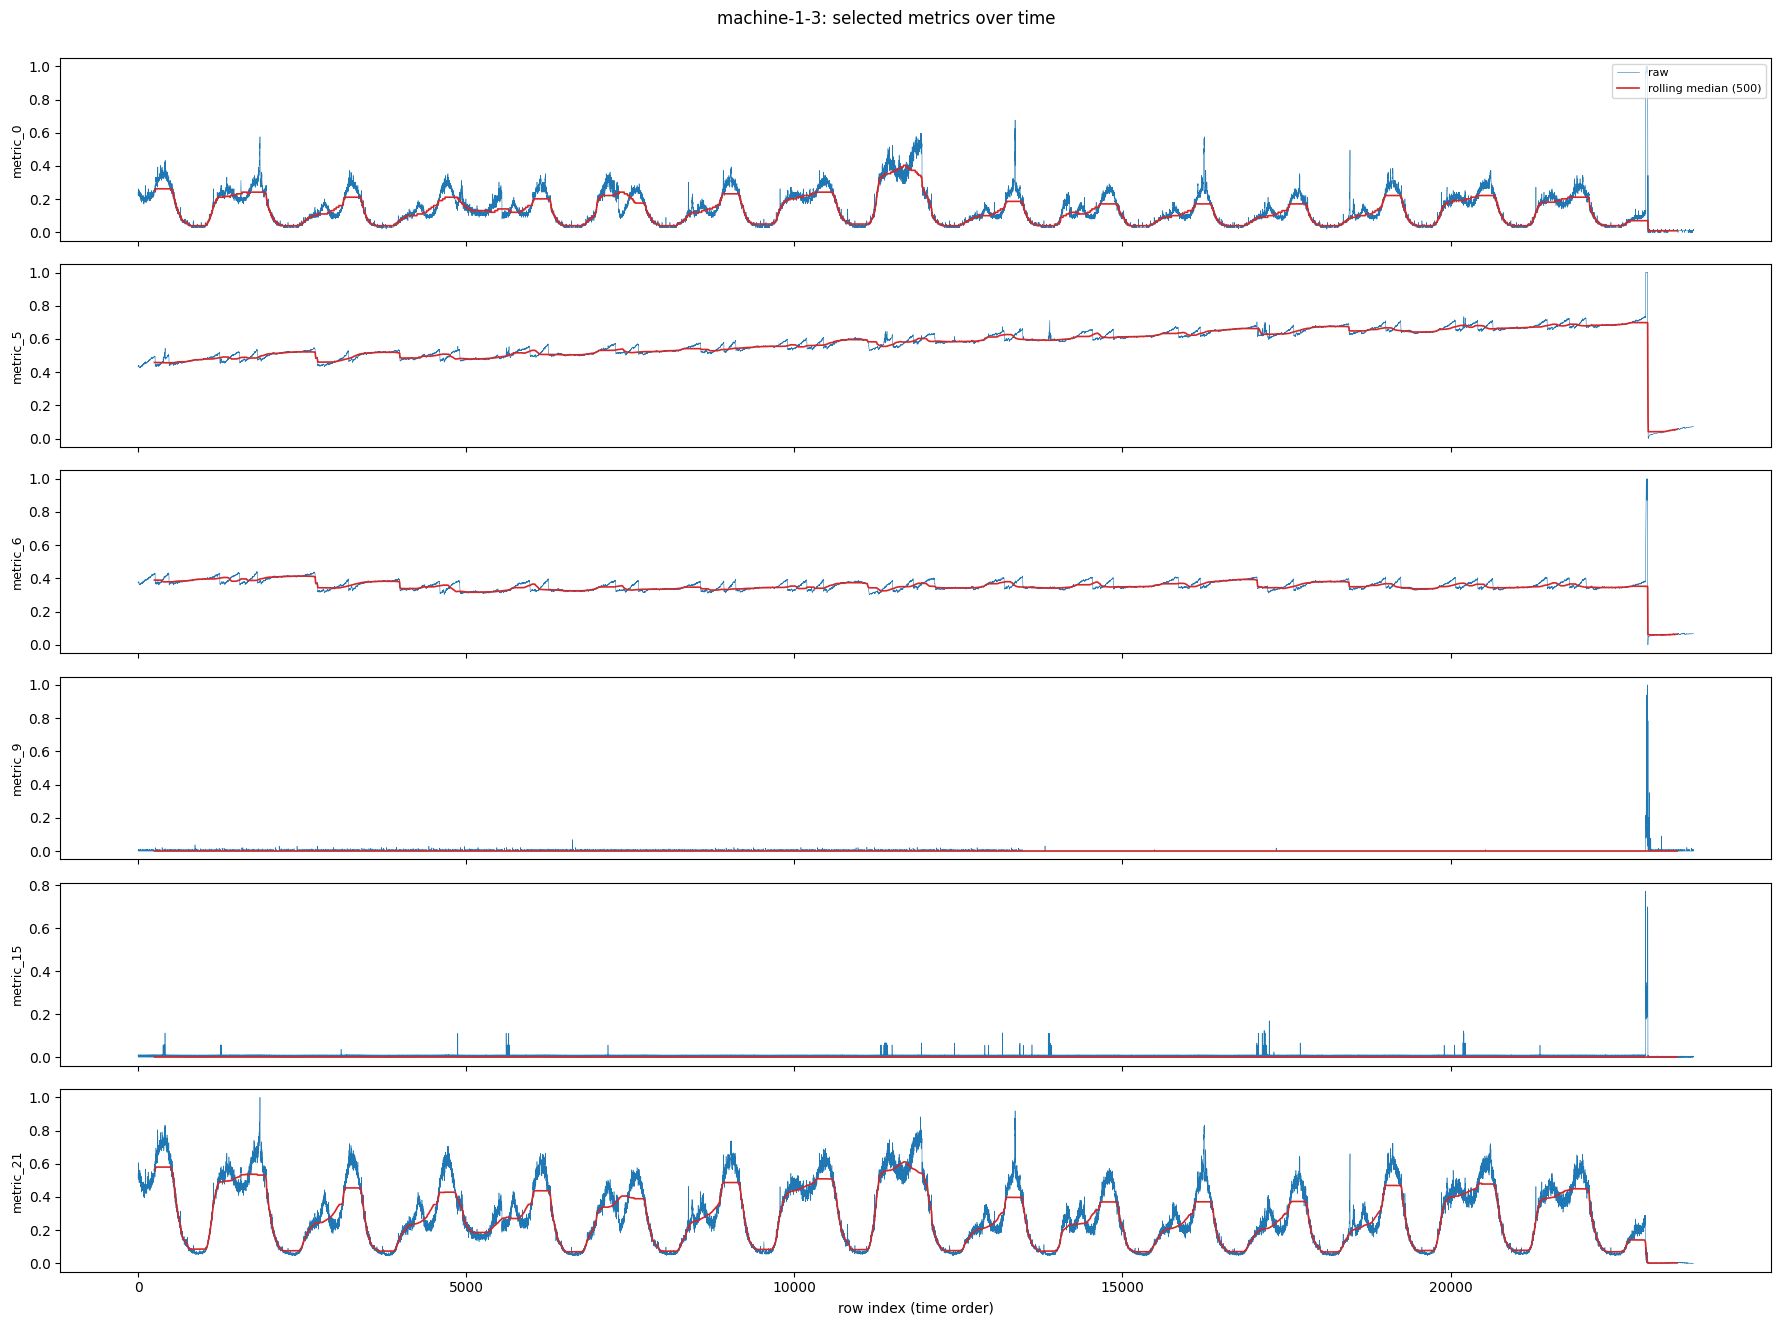

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plot_metrics = ["metric_0", "metric_5", "metric_6", "metric_9", "metric_15", "metric_21"]

for name, pop in test.items():
    fig, axes = plt.subplots(len(plot_metrics), 1, figsize=(18, 2.2 * len(plot_metrics)), sharex=True)
    for ax, c in zip(axes, plot_metrics):
        ax.plot(pop[c].values, lw=0.4, color="tab:blue", label="raw")
        ax.plot(pop[c].rolling(500, center=True).median().values, lw=1.2, color="tab:red", label="rolling median (500)")
        ax.set_ylabel(c, fontsize=9)
    axes[0].legend(loc="upper right", fontsize=8)
    axes[-1].set_xlabel("row index (time order)")
    fig.suptitle(f"{name}: selected metrics over time", y=1.0)
    plt.tight_layout()
    plt.show()

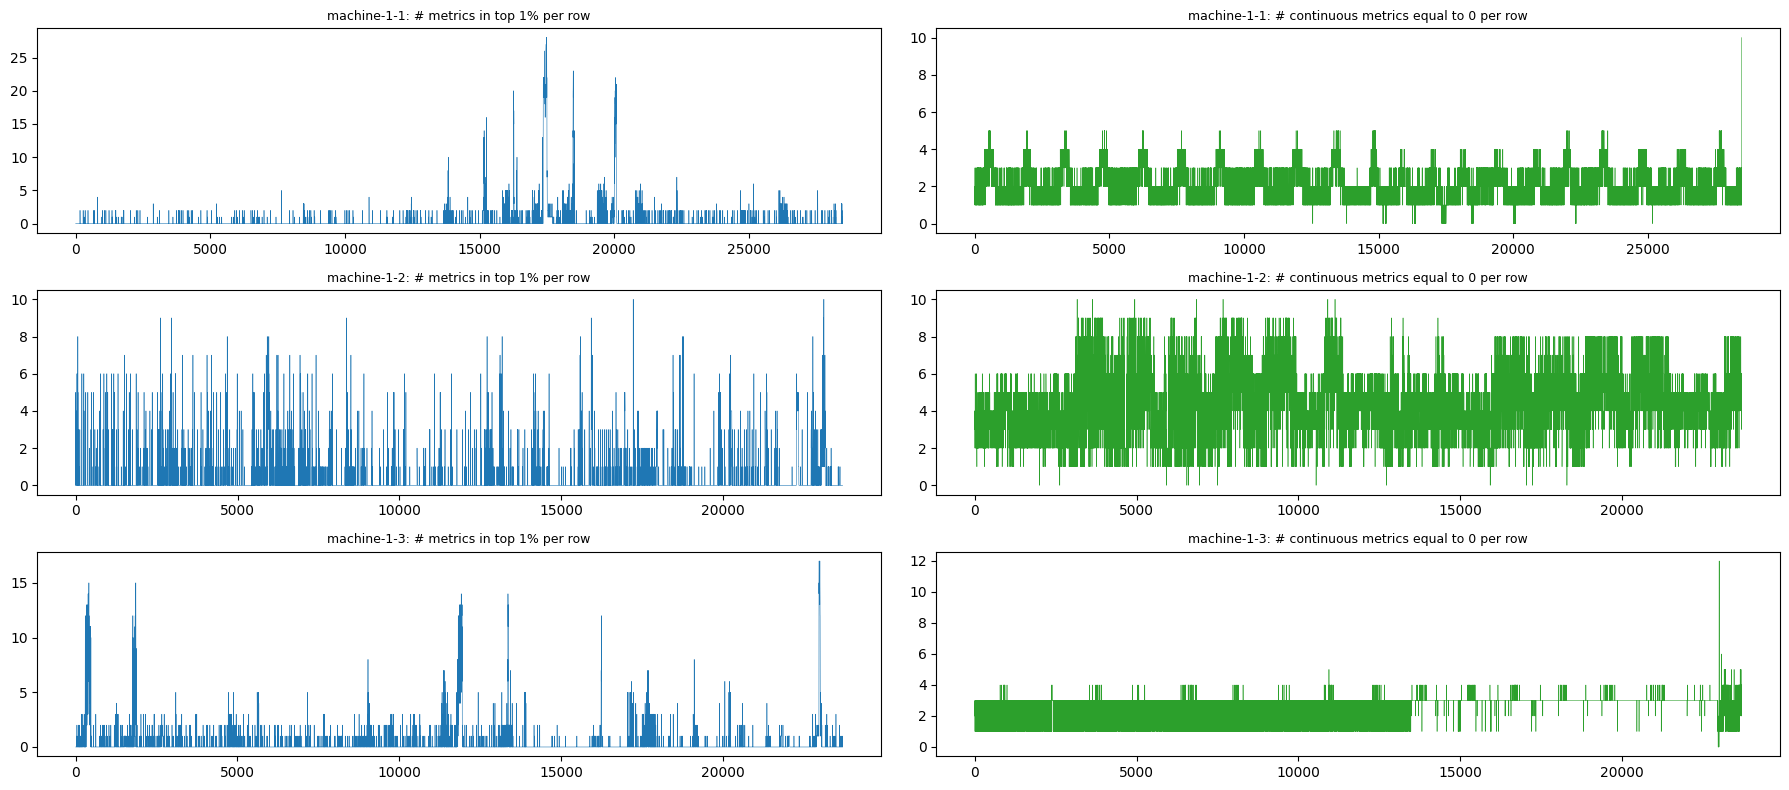

first / last zero-row: 3110 23666
2000     117
4000      97
6000      98
8000     147
10000     71
12000      8
14000      7
16000     58
18000     95
20000     72
22000     42
dtype: int64


In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(18, 8))
for i, (name, pop) in enumerate(test.items()):
    c = groups_test[name]["cont"]
    n_extreme = (pop[c] > pop[c].quantile(0.99)).sum(axis=1)
    n_zero = (pop[c] == 0).sum(axis=1)
    axes[i, 0].plot(n_extreme.values, lw=0.4)
    axes[i, 0].set_title(f"{name}: # metrics in top 1% per row", fontsize=9)
    axes[i, 1].plot(n_zero.values, lw=0.4, color="tab:green")
    axes[i, 1].set_title(f"{name}: # continuous metrics equal to 0 per row", fontsize=9)
plt.tight_layout()
plt.show()

# Where do machine-1-2's zero rows start, and are they spread evenly?
d = test["machine-1-2"]; c = groups_test["machine-1-2"]["cont"]
z = np.where((d[c] == 0).sum(axis=1) >= 8)[0]
print("first / last zero-row:", z.min(), z.max())
print(pd.Series(z).groupby(pd.Series(z) // 2000 * 2000).size())   # count per 2000-row block

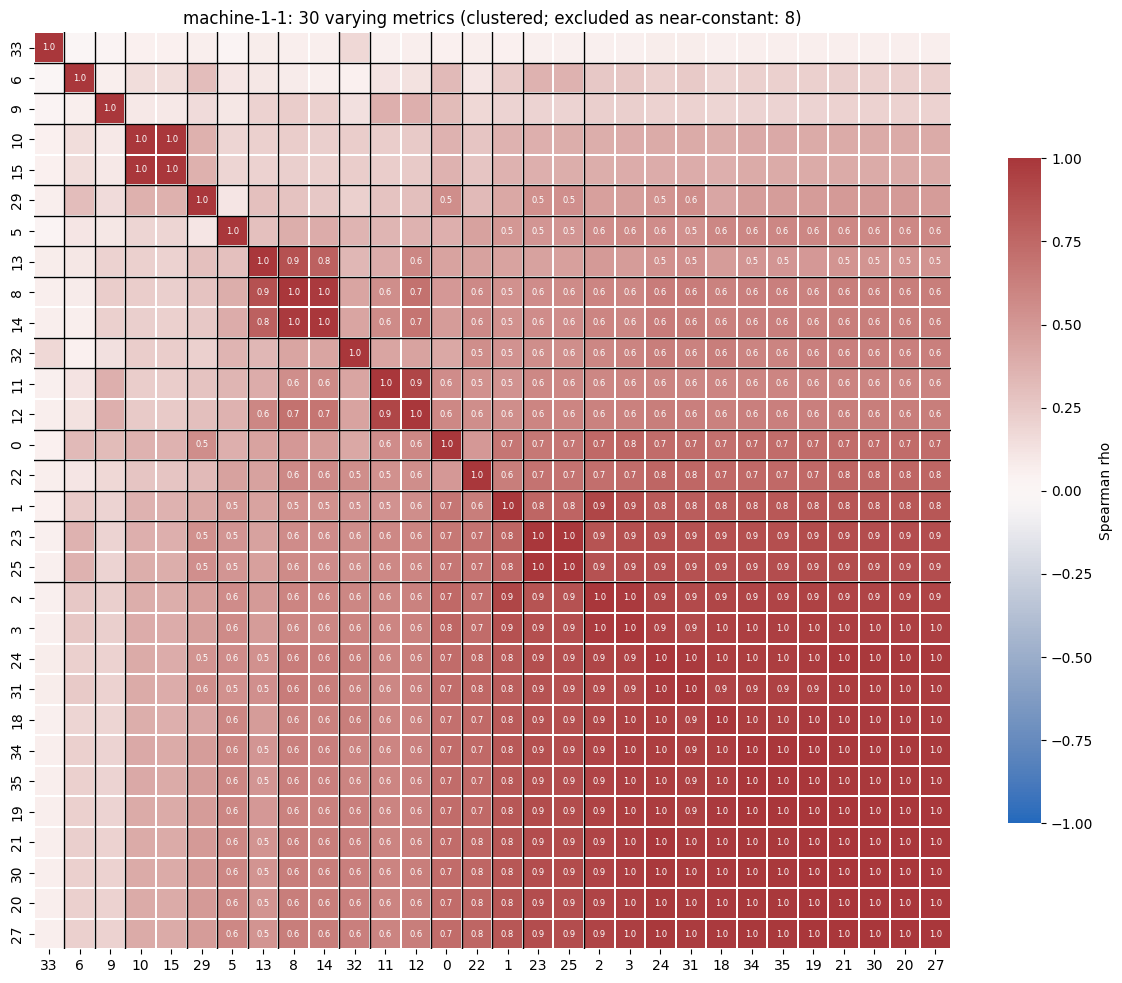

machine-1-1 excluded (near-constant): ['4', '7', '16', '17', '26', '28', '36', '37']
  group 1: ['10', '15']
  group 2: ['8', '14']
  group 4: ['11', '12']
  group 5: ['23', '25']
  group 6: ['2', '3', '18', '19', '20', '21', '24', '27', '30', '31', '34', '35']


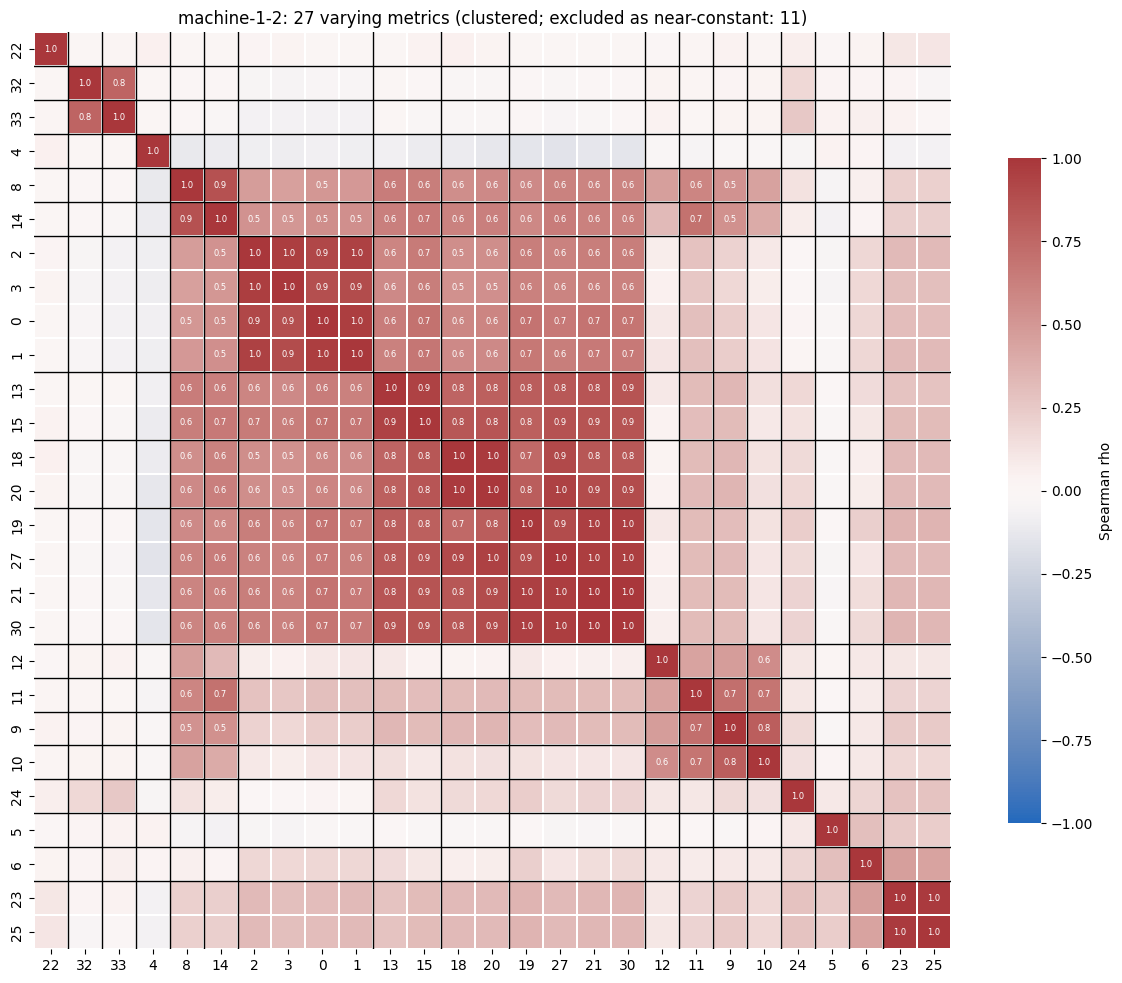

machine-1-2 excluded (near-constant): ['7', '16', '17', '26', '28', '29', '31', '34', '35', '36', '37']
  group 5: ['0', '1', '2', '3']
  group 6: ['13', '15']
  group 7: ['18', '20']
  group 8: ['19', '21', '27', '30']
  group 13: ['23', '25']


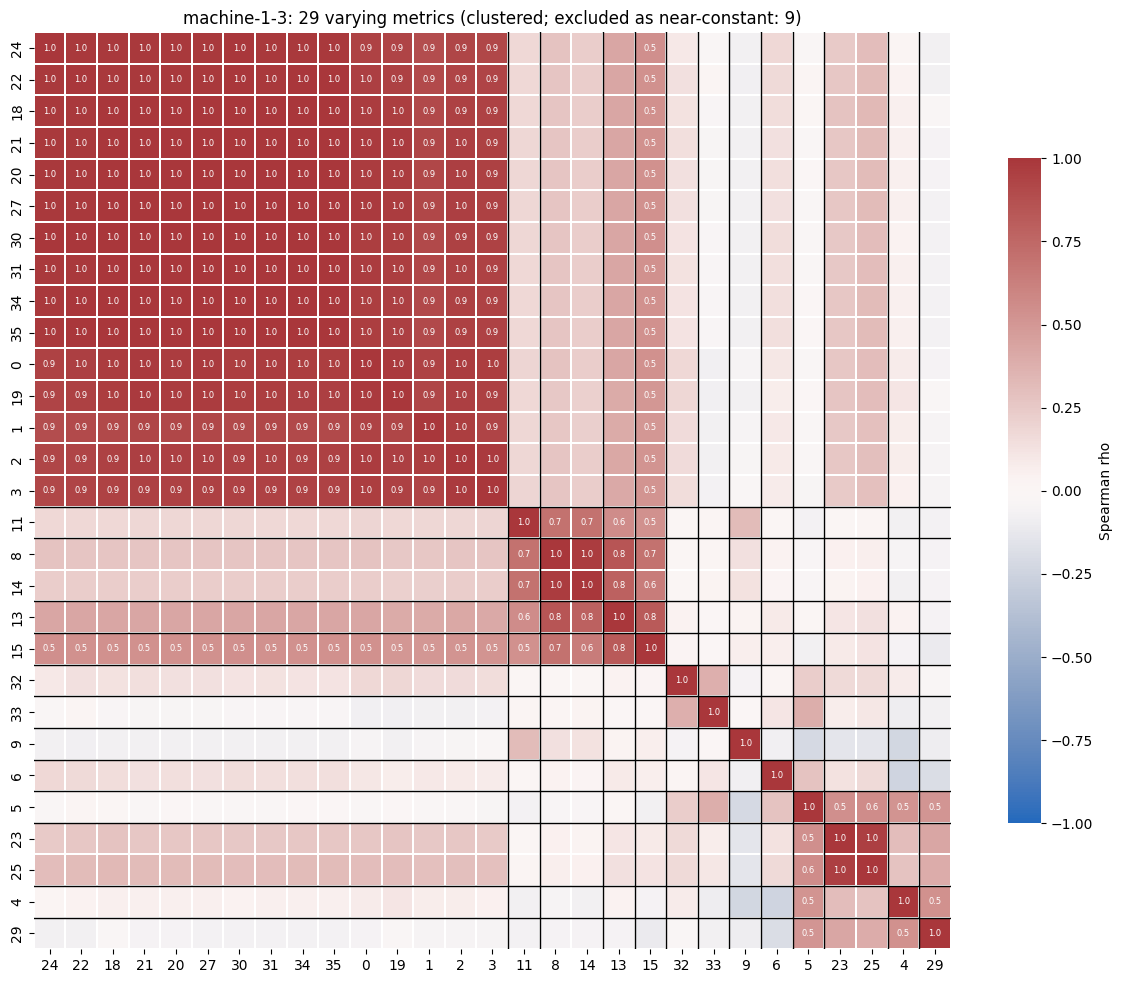

machine-1-3 excluded (near-constant): ['7', '10', '12', '16', '17', '26', '28', '36', '37']
  group 1: ['0', '1', '2', '3', '18', '19', '20', '21', '22', '24', '27', '30', '31', '34', '35']
  group 2: ['8', '14']
  group 8: ['23', '25']


In [ ]:
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, leaves_list, fcluster
from scipy.spatial.distance import squareform

def clean_corr(pop, top_freq_max=0.95, method="spearman"):
    # keep only metrics that really vary (one value in <95% of rows)
    keep = [c for c in pop.columns
            if pop[c].nunique() > 1 and pop[c].value_counts(normalize=True).iloc[0] < top_freq_max]
    dropped = [c for c in pop.columns if c not in keep]
    corr = pop[keep].corr(method=method).fillna(0)
    return corr, dropped

def order_and_groups(corr, cut=0.10):
    # distance = 1 - |rho|; cut=0.10 means groups with average |rho| >= ~0.9
    dist = 1 - corr.abs().values
    np.fill_diagonal(dist, 0)
    dist = (dist + dist.T) / 2
    Z = linkage(squareform(dist, checks=False), method="average")
    return leaves_list(Z), fcluster(Z, t=cut, criterion="distance")

def plot_corr(name, pop, cut=0.10):
    corr, dropped = clean_corr(pop)
    order, labels = order_and_groups(corr, cut)
    co = corr.iloc[order, order]
    lab_o = labels[order]
    short = [c.replace("metric_", "") for c in co.columns]

    annot = np.where(co.abs().values >= 0.5, co.round(1).astype(str).values, "")
    fig, ax = plt.subplots(figsize=(12, 10))
    sns.heatmap(co, cmap="vlag", vmin=-1, vmax=1, center=0, square=True,
                xticklabels=short, yticklabels=short,
                annot=annot, fmt="", annot_kws={"fontsize": 6},
                linewidths=0.3, linecolor="white",
                cbar_kws={"shrink": 0.7, "label": "Spearman rho"}, ax=ax)
    # outline the groups
    for i in range(1, len(lab_o)):
        if lab_o[i] != lab_o[i - 1]:
            ax.axhline(i, color="black", lw=1)
            ax.axvline(i, color="black", lw=1)
    ax.set_title(f"{name}: {len(co)} varying metrics (clustered; "
                 f"excluded as near-constant: {len(dropped)})")
    plt.tight_layout()
    plt.show()

    print(f"{name} excluded (near-constant):", [d.replace('metric_','') for d in dropped])
    for g in sorted(set(labels)):
        members = [corr.columns[i].replace("metric_", "") for i in range(len(labels)) if labels[i] == g]
        if len(members) > 1:
            print(f"  group {g}: {members}")

for name, pop in test.items():
    plot_corr(name, pop)

In [ ]:
for name, pop in test.items():
    corr, dropped = clean_corr(pop)
    order, labels = order_and_groups(corr, cut=0.25)
    print(f"\n{name}")
    for g in sorted(set(labels)):
        members = [corr.columns[i].replace("metric_", "") for i in range(len(labels)) if labels[i] == g]
        print(f"  group {g}: {members}")


machine-1-1
  group 1: ['10', '15']
  group 2: ['8', '13', '14']
  group 3: ['11', '12']
  group 4: ['1', '2', '3', '18', '19', '20', '21', '23', '24', '25', '27', '30', '31', '34', '35']
  group 5: ['22']
  group 6: ['0']
  group 7: ['32']
  group 8: ['5']
  group 9: ['29']
  group 10: ['9']
  group 11: ['6']
  group 12: ['33']

machine-1-2
  group 1: ['32', '33']
  group 2: ['8', '14']
  group 3: ['0', '1', '2', '3']
  group 4: ['13', '15', '18', '19', '20', '21', '27', '30']
  group 5: ['9', '10']
  group 6: ['11']
  group 7: ['12']
  group 8: ['23', '25']
  group 9: ['6']
  group 10: ['5']
  group 11: ['24']
  group 12: ['4']
  group 13: ['22']

machine-1-3
  group 1: ['0', '1', '2', '3', '18', '19', '20', '21', '22', '24', '27', '30', '31', '34', '35']
  group 2: ['8', '14']
  group 3: ['13', '15']
  group 4: ['11']
  group 5: ['32']
  group 6: ['33']
  group 7: ['23', '25']
  group 8: ['5']
  group 9: ['4']
  group 10: ['29']
  group 11: ['6']
  group 12: ['9']


In [ ]:
for var, val in list(globals().items()):
    if var.startswith("_"):
        continue
    if isinstance(val, pd.DataFrame):
        print(f"df   {var:10} shape={val.shape}  has metric_0: {'metric_0' in val.columns}  first cols: {val.columns[:3].tolist()}")
    elif isinstance(val, dict) and val and all(isinstance(v, pd.DataFrame) for v in val.values()):
        for k, v in val.items():
            print(f"dict {var:10}[{k}] shape={v.shape}  has metric_0: {'metric_0' in v.columns}  first cols: {v.columns[:3].tolist()}")

dict test_labels[machine-1-1] shape=(28479, 1)  has metric_0: False  first cols: ['label']
dict test_labels[machine-1-2] shape=(23694, 1)  has metric_0: False  first cols: ['label']
dict test_labels[machine-1-3] shape=(23703, 1)  has metric_0: False  first cols: ['label']
df   lol        shape=(23703, 1)  has metric_0: False  first cols: ['label']
dict data      [machine-1-1] shape=(28479, 38)  has metric_0: True  first cols: ['metric_0', 'metric_1', 'metric_2']
dict data      [machine-1-2] shape=(23694, 38)  has metric_0: True  first cols: ['metric_0', 'metric_1', 'metric_2']
dict data      [machine-1-3] shape=(23702, 38)  has metric_0: True  first cols: ['metric_0', 'metric_1', 'metric_2']
df   df         shape=(23702, 38)  has metric_0: True  first cols: ['metric_0', 'metric_1', 'metric_2']
df   summary_df shape=(3, 9)  has metric_0: False  first cols: ['rows', 'cols', 'missing']
df   d          shape=(23694, 38)  has metric_0: True  first cols: ['metric_0', 'metric_1', 'metric_2']


In [ ]:
print(pop.columns[:5].tolist() if isinstance(pop, pd.DataFrame) else {k: v.columns[:3].tolist() for k, v in pop.items()})

['metric_0', 'metric_1', 'metric_2', 'metric_3', 'metric_4']


In [ ]:
print(test["machine-1-1"].metric_0.max(), data["machine-1-1"].metric_0.max())   # expect 1.0  0.4946
print([d.shape[0] for d in test.values()], [d.shape[0] for d in data.values()])  # expect [28479, 23694, 23703]  [28479, 23694, 23702]

1.0 0.494624
[28479, 23694, 23703] [28479, 23694, 23702]


# **TEST_LABELS**



In [ ]:
import pandas as pd
import numpy as np

paths = {
    "machine-1-1": r"OmniAnomaly-master\ServerMachineDataset\test_label\machine-1-1.txt",   # adjust to your actual paths
    "machine-1-2": r"OmniAnomaly-master\ServerMachineDataset\test_label\machine-1-2.txt",
    "machine-1-3": r"OmniAnomaly-master\ServerMachineDataset\test_label\machine-1-3.txt",
}

cols = [f"metric_{i}" for i in range(38)]
test_labels = {}
for name, l in paths.items():
    lol = pd.read_csv(l, header=None, names=['label'])
    test_labels[name] = lol
    print(f"{name}: shape={lol.shape}")

machine-1-1: shape=(28479, 1)
machine-1-2: shape=(23694, 1)
machine-1-3: shape=(23703, 1)


In [ ]:
lol.head()

,label
0,0
1,0
2,0
3,0
4,0


In [ ]:
def segments(y):
    v = y.values
    d = np.diff(np.r_[0, v, 0])
    s, e = np.where(d == 1)[0], np.where(d == -1)[0] - 1
    return list(zip(s, e))

for m, lol in test_labels.items():
    y = lol["label"]
    seg = segments(y)
    lens = [e - s + 1 for s, e in seg]
    print(f"\n===== {m} =====")
    print(f"anomalous rows: {y.sum()} ({y.mean()*100:.2f}%)")
    print("segments:", len(seg), "| length min/median/max:", min(lens), int(np.median(lens)), max(lens))
    print("segments (start, end):", seg)


===== machine-1-1 =====
anomalous rows: 2694 (9.46%)
segments: 8 | length min/median/max: 2 433 721
segments (start, end): [(np.int64(15849), np.int64(16394)), (np.int64(16963), np.int64(17516)), (np.int64(18071), np.int64(18527)), (np.int64(19367), np.int64(20087)), (np.int64(20786), np.int64(21194)), (np.int64(24679), np.int64(24681)), (np.int64(26114), np.int64(26115)), (np.int64(27554), np.int64(27555))]

===== machine-1-2 =====
anomalous rows: 542 (2.29%)
segments: 10 | length min/median/max: 3 53 156
segments (start, end): [(np.int64(4629), np.int64(4687)), (np.int64(5486), np.int64(5490)), (np.int64(5875), np.int64(5950)), (np.int64(15415), np.int64(15417)), (np.int64(15540), np.int64(15604)), (np.int64(15925), np.int64(15972)), (np.int64(18645), np.int64(18800)), (np.int64(20235), np.int64(20270)), (np.int64(22264), np.int64(22335)), (np.int64(23093), np.int64(23114))]

===== machine-1-3 =====
anomalous rows: 817 (3.45%)
segments: 12 | length min/median/max: 3 46 225
segments 


===== machine-1-1: top 10 metrics by |effect| =====
           normal_mean  anom_mean  normal_median  anom_median   effect
metric_28       0.0000     0.0058         0.0000       0.0000  80.0832
metric_33       0.0000     0.0067         0.0000       0.0000  62.7444
metric_32       0.0002     0.0064         0.0004       0.0000  26.5894
metric_9        0.0002     0.0091         0.0001       0.0002   7.9029
metric_0        0.1145     0.4390         0.0968       0.4731   3.6036
metric_25       0.0120     0.0221         0.0122       0.0130   1.9835
metric_23       0.0130     0.0234         0.0134       0.0142   1.8836
metric_29       0.0198     0.0413         0.0172       0.0358   1.7509
metric_24       0.0455     0.1109         0.0369       0.0457   1.5568
metric_31       0.0676     0.1463         0.0561       0.0767   1.5433


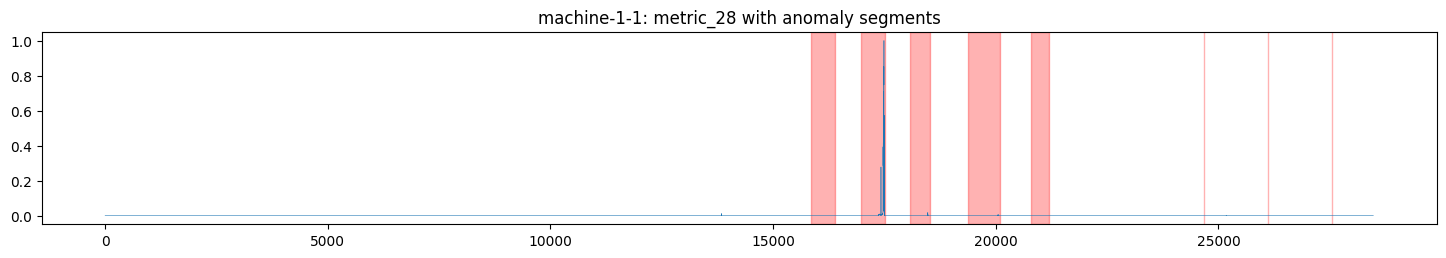


===== machine-1-2: top 10 metrics by |effect| =====
           normal_mean  anom_mean  normal_median  anom_median  effect
metric_12       0.0057     0.2549         0.0000       0.0050  4.8337
metric_9        0.0027     0.0614         0.0000       0.0024  3.1290
metric_11       0.0230     0.1628         0.0090       0.0578  2.9271
metric_10       0.0036     0.0703         0.0000       0.0021  2.8045
metric_2        0.0984     0.2231         0.0856       0.0787  1.5123
metric_3        0.1038     0.2256         0.0944       0.0997  1.5061
metric_17       0.0001     0.0069         0.0000       0.0000  1.3401
metric_1        0.0844     0.1905         0.0691       0.0600  1.3180
metric_6        0.2134     0.3264         0.1757       0.2990  0.9747
metric_23       0.0753     0.1142         0.0649       0.0711  0.8848


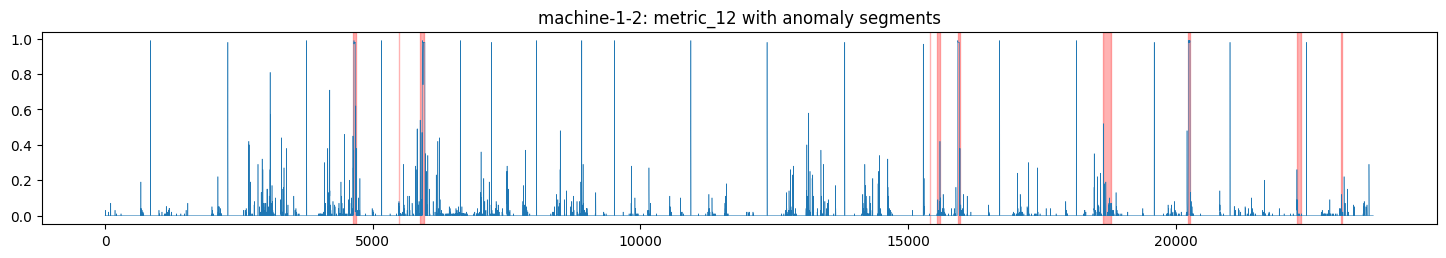


===== machine-1-3: top 10 metrics by |effect| =====
           normal_mean  anom_mean  normal_median  anom_median   effect
metric_8        0.0004     0.0464         0.0002       0.0002  34.7851
metric_12       0.0001     0.0503         0.0000       0.0000  24.6040
metric_2        0.0076     0.0474         0.0059       0.0126   6.5026
metric_1        0.0070     0.0432         0.0055       0.0109   6.2788
metric_14       0.0049     0.0632         0.0032       0.0039   5.6725
metric_15       0.0019     0.0233         0.0008       0.0009   5.3711
metric_13       0.0091     0.0256         0.0083       0.0090   4.8870
metric_3        0.0094     0.0517         0.0072       0.0150   4.2526
metric_9        0.0005     0.0133         0.0000       0.0000   3.8653
metric_11       0.0201     0.0818         0.0167       0.0193   3.6928


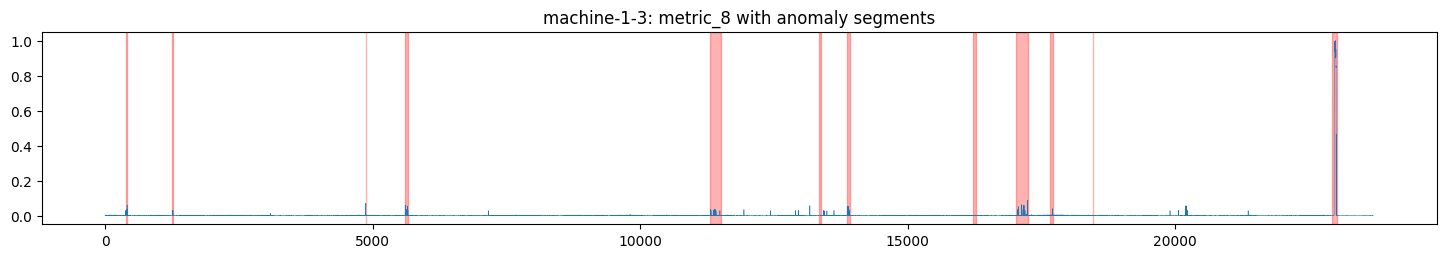

In [ ]:
for m, lol in test_labels.items():
    y = lol["label"]
    X = test[m]
    live = [c for c in X.columns if X.loc[y == 0, c].std() > 0]
    a, n = X.loc[y == 1, live], X.loc[y == 0, live]
    eff = ((a.mean() - n.mean()) / n.std()).rename("effect")
    out = pd.DataFrame({"normal_mean": n.mean(), "anom_mean": a.mean(),
                        "normal_median": n.median(), "anom_median": a.median(), "effect": eff})
    print(f"\n===== {m}: top 10 metrics by |effect| =====")
    print(out.reindex(eff.abs().sort_values(ascending=False).index).head(10).round(4).to_string())

    top = eff.abs().idxmax()
    fig, ax = plt.subplots(figsize=(18, 2.5))
    ax.plot(X[top].values, lw=0.4)
    for s, e in segments(y):
        ax.axvspan(s, e, color="red", alpha=0.3)
    ax.set_title(f"{m}: {top} with anomaly segments")
    plt.show()

In [ ]:
for m, lol in test_labels.items():
    y = lol["label"]
    print(m, "| dtype:", y.dtype, "| len:", len(y), "| test rows:", len(test[m]))
    print("   value counts:", y.value_counts(dropna=False).to_dict())
    print("   index matches test:", y.index.equals(test[m].index), "| (y==1).sum():", int((y == 1).sum()))

machine-1-1 | dtype: int64 | len: 28479 | test rows: 28479
   value counts: {0: 25785, 1: 2694}
   index matches test: True | (y==1).sum(): 2694
machine-1-2 | dtype: int64 | len: 23694 | test rows: 23694
   value counts: {0: 23152, 1: 542}
   index matches test: True | (y==1).sum(): 542
machine-1-3 | dtype: int64 | len: 23703 | test rows: 23703
   value counts: {0: 22886, 1: 817}
   index matches test: True | (y==1).sum(): 817


In [ ]:
from IPython.display import display

summ = {}
for m in test:
    tr, te = data[m], test[m]                        # train = data, test = test
    dead_tr = set(tr.columns[tr.nunique() == 1])
    dead_te = set(te.columns[te.nunique() == 1])
    live = [c for c in tr.columns if c not in dead_tr and c not in dead_te]

    # 1) distribution shift + values outside the train range
    shift = pd.DataFrame({
        "tr_median": tr[live].median(), "te_median": te[live].median(),
        "tr_mean": tr[live].mean(),     "te_mean": te[live].mean(),
        "shift_in_train_std": (te[live].mean() - tr[live].mean()) / tr[live].std(),
        "pct_above_train_max": (te[live] > tr[live].max()).mean() * 100,
        "pct_below_train_min": (te[live] < tr[live].min()).mean() * 100,
    })
    shift["pct_outside_range"] = shift.pct_above_train_max + shift.pct_below_train_min

    # 2) do the correlation groups carry over? (compare the two Spearman matrices)
    ctr, cte = tr[live].corr("spearman").fillna(0), te[live].corr("spearman").fillna(0)
    iu = np.triu_indices(len(live), k=1)
    corr_sim = np.corrcoef(ctr.values[iu], cte.values[iu])[0, 1]
    diff = (cte - ctr).abs().where(np.triu(np.ones(ctr.shape, dtype=bool), 1)).stack()

    # 3) daily cycle: autocorrelation at lag 1440 (1 day, if 1 row = 1 minute)
    ac = pd.DataFrame({c: {"train": tr[c].autocorr(1440), "test": te[c].autocorr(1440)}
                       for c in ["metric_0", "metric_5", "metric_9"] if c in live}).T

    print(f"\n===== {m} =====")
    print("dead in train only:", sorted(dead_tr - dead_te, key=lambda s: int(s[7:])),
          "| dead in test only:", sorted(dead_te - dead_tr, key=lambda s: int(s[7:])))
    print("\nTop 10 metrics by |shift| (in train std):")
    display(shift.reindex(shift.shift_in_train_std.abs().sort_values(ascending=False).index).head(10).round(4))
    print("Metrics with >1% of test rows outside the train range:")
    display(shift[shift.pct_outside_range > 1][["pct_above_train_max", "pct_below_train_min"]].round(2))
    print(f"Correlation-matrix similarity (train vs test): {corr_sim:.3f}")
    print("Pairs whose correlation changed most:")
    display(diff.sort_values(ascending=False).head(8).round(3))
    print("Lag-1440 autocorrelation:"); display(ac.round(3))

    summ[m] = {"rows_train": len(tr), "rows_test": len(te),
               "dead_train": len(dead_tr), "dead_test": len(dead_te),
               "metrics_shift_gt_1std": int((shift.shift_in_train_std.abs() > 1).sum()),
               "metrics_gt_1pct_outside_range": int((shift.pct_outside_range > 1).sum()),
               "corr_similarity": round(corr_sim, 3)}


===== machine-1-1 =====
dead in train only: ['metric_26', 'metric_28'] | dead in test only: []

Top 10 metrics by |shift| (in train std):


,tr_median,te_median,tr_mean,te_mean,shift_in_train_std,pct_above_train_max,pct_below_train_min,pct_outside_range
metric_33,0.0000,0.0000,0.0000,0.0007,43.3190,0.4635,0.0000,0.4635
metric_29,0.0043,0.0172,0.0055,0.0219,6.4313,30.0537,0.0000,30.0537
metric_32,0.0000,0.0004,0.0002,0.0008,3.1585,0.4073,0.0000,0.4073
metric_24,0.0145,0.0371,0.0209,0.0517,1.7266,4.3014,0.0000,4.3014
metric_35,0.0365,0.0806,0.0504,0.1079,1.6409,5.5374,0.0035,5.5409
metric_34,0.0364,0.0806,0.0504,0.1079,1.6409,5.5374,0.0035,5.5409
metric_31,0.0278,0.0566,0.0362,0.0750,1.6389,1.9102,0.0035,1.9137
metric_30,0.0349,0.0772,0.0473,0.0989,1.5599,5.3724,0.0035,5.3759
metric_27,0.0416,0.0877,0.0549,0.1095,1.5305,5.1652,0.0035,5.1687
metric_21,0.0376,0.0835,0.0510,0.1056,1.5202,5.0423,0.0035,5.0458


Metrics with >1% of test rows outside the train range:


,pct_above_train_max,pct_below_train_min
metric_0,1.89,0.0
metric_1,1.99,0.0
metric_2,6.20,0.0
metric_3,7.65,0.0
metric_6,1.96,0.0
metric_18,4.77,0.0
metric_19,4.03,0.0
metric_20,4.76,0.0
metric_21,5.04,0.0
metric_24,4.30,0.0


Correlation-matrix similarity (train vs test): 0.934
Pairs whose correlation changed most:


,,0
metric_6,metric_29,0.579
metric_0,metric_6,0.406
metric_3,metric_6,0.406
metric_2,metric_6,0.392
metric_0,metric_22,0.374
metric_22,metric_29,0.369
metric_1,metric_6,0.349
metric_6,metric_19,0.344


... (14 outputs left out)

Correlation-matrix similarity (train vs test): 0.965
Pairs whose correlation changed most:


metric_16  metric_17    0.725
metric_5   metric_29    0.679
metric_4   metric_6     0.614
metric_5   metric_6     0.523
           metric_33    0.394
metric_23  metric_29    0.306
metric_16  metric_28    0.292
metric_5   metric_23    0.284
dtype: float64

Lag-1440 autocorrelation:


,train,test
metric_0,0.822,0.623
metric_5,0.536,0.294
metric_9,0.021,0.031


In [ ]:
rows = []
for m in test:
    y = test_labels[m]["label"]
    seg = segments(y)
    rows.append({"machine": m, **summ[m],
                 "anomaly_rows": int(y.sum()), "anomaly_pct": round(y.mean() * 100, 2),
                 "segments": len(seg),
                 "median_segment_len": int(np.median([b - a + 1 for a, b in seg]))})
summary_final = pd.DataFrame(rows).set_index("machine")
display(summary_final.T)

machine,machine-1-1,machine-1-2,machine-1-3
rows_train,28479.000,23694.000,23702.000
rows_test,28479.000,23694.000,23703.000
dead_train,8.000,5.000,4.000
dead_test,6.000,5.000,4.000
metrics_shift_gt_1std,17.000,0.000,5.000
metrics_gt_1pct_outside_range,16.000,0.000,19.000
corr_similarity,0.934,0.962,0.965
anomaly_rows,2694.000,542.000,817.000
anomaly_pct,9.460,2.290,3.450
segments,8.000,10.000,12.000


In [ ]:
from sklearn.preprocessing import StandardScaler

def preprocess(m, red_thresh=0.98):
    tr, te = data[m], test[m]
    live = [c for c in tr.columns if tr[c].nunique() > 1]            # drop metrics dead in train
    corr = tr[live].corr("spearman").abs().fillna(0)
    keep = []
    for c in live:                                                   # drop near-duplicates, keep the first of each
        if all(corr.loc[c, k] < red_thresh for k in keep):
            keep.append(c)
    sc = StandardScaler().fit(tr[keep])                              # fitted on TRAIN only
    return keep, sc.transform(tr[keep]), sc.transform(te[keep])

prep = {}
for m in test:
    keep, Xtr, Xte = preprocess(m)
    prep[m] = (keep, Xtr, Xte)
    print(f"{m}: kept {len(keep)} of 38 | max |z| in test = {np.abs(Xte).max():.1f}")

machine-1-1: kept 21 of 38 | max |z| in test = 68130.9
machine-1-2: kept 30 of 38 | max |z| in test = 153.9
machine-1-3: kept 20 of 38 | max |z| in test = 3029.8


In [ ]:
from sklearn.svm import OneClassSVM
# For Isolation Forest, replace the model line with:
#   from sklearn.ensemble import IsolationForest;  model = IsolationForest(random_state=0).fit(Xtr)

scores = {}
for m, (keep, Xtr, Xte) in prep.items():
    model = OneClassSVM(kernel="rbf", gamma="scale", nu=0.01).fit(Xtr)
    s_tr, s_te = -model.decision_function(Xtr), -model.decision_function(Xte)   # higher = more anomalous
    scores[m] = (s_tr, s_te, np.quantile(s_tr, 0.99))    # threshold from TRAIN scores, no labels
    print(m, "done")

machine-1-1 done
machine-1-2 done
machine-1-3 done


In [ ]:
# which kept metrics produce the huge z-scores?
for m, (keep, Xtr, Xte) in prep.items():
    worst = pd.Series(np.abs(Xte).max(axis=0), index=keep).sort_values(ascending=False).head(3)
    print(m, worst.round(0).to_dict())

machine-1-1 {'metric_33': 68131.0, 'metric_32': 4969.0, 'metric_9': 777.0}
machine-1-2 {'metric_29': 154.0, 'metric_8': 87.0, 'metric_31': 58.0}
machine-1-3 {'metric_16': 3030.0, 'metric_17': 2442.0, 'metric_10': 458.0}


In [ ]:
from sklearn.metrics import precision_recall_fscore_support, average_precision_score, roc_auc_score

def run(clip=None, nu=0.01, q=0.99):
    rows = []
    for m, (keep, Xtr, Xte) in prep.items():
        A, B = (Xtr, Xte) if clip is None else (np.clip(Xtr, -clip, clip), np.clip(Xte, -clip, clip))
        model = OneClassSVM(kernel="rbf", gamma="scale", nu=nu).fit(A)
        s_tr, s_te = -model.decision_function(A), -model.decision_function(B)
        thr = np.quantile(s_tr, q)                       # threshold from train scores only
        lab_s = test_labels[m]["label"]
        y, pred = lab_s.values, (s_te > thr).astype(int)
        p, r, f, _ = precision_recall_fscore_support(y, pred, average="binary", zero_division=0)
        seg = segments(lab_s)
        rows.append({"machine": m, "flagged_%": round(pred.mean() * 100, 2),
                     "precision": round(p, 3), "recall": round(r, 3), "F1": round(f, 3),
                     "ROC_AUC": round(roc_auc_score(y, s_te), 3),
                     "PR_AUC": round(average_precision_score(y, s_te), 3),
                     "segments_hit": f"{sum(pred[a:b+1].any() for a, b in seg)}/{len(seg)}"})
    return pd.DataFrame(rows).set_index("machine")

display(pd.concat({"no clip": run(None), "clip ±10": run(10)}))

flagged_%  precision  recall     F1  ROC_AUC  PR_AUC  \
         machine                                                             
no clip  machine-1-1      60.30      0.156   0.995  0.270    0.876   0.556   
         machine-1-2       3.56      0.284   0.443  0.346    0.768   0.262   
         machine-1-3      68.84      0.046   0.912  0.087    0.738   0.095   
clip ±10 machine-1-1      61.82      0.153   0.997  0.265    0.871   0.553   
         machine-1-2       4.41      0.248   0.478  0.327    0.793   0.276   
         machine-1-3      73.67      0.044   0.941  0.084    0.763   0.155   

                     segments_hit  
         machine                   
no clip  machine-1-1          8/8  
         machine-1-2        10/10  
         machine-1-3        12/12  
clip ±10 machine-1-1          8/8  
         machine-1-2        10/10  
         machine-1-3        12/12

In [ ]:
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.metrics import (precision_recall_fscore_support, roc_auc_score,
                             average_precision_score, precision_recall_curve)

def pa_f1(y, pred):
    """Point-adjusted F1: a true segment counts as caught if any row in it is flagged (common for SMD, optimistic)."""
    adj = pred.copy()
    for a, b in segments(pd.Series(y)):
        if pred[a:b+1].any():
            adj[a:b+1] = 1
    return precision_recall_fscore_support(y, adj, average="binary", zero_division=0)[2]

def evaluate(m, s_te, flag_rate=0.05, win=15):
    y = test_labels[m]["label"].values
    sm = pd.Series(s_te).rolling(win, min_periods=1).mean().values       # smooth scores (trailing window)
    pred = (sm > np.quantile(sm, 1 - flag_rate)).astype(int)             # flag the top 5% of test scores, no labels used
    p, r, f, _ = precision_recall_fscore_support(y, pred, average="binary", zero_division=0)
    pr, rc, _ = precision_recall_curve(y, sm)
    seg = segments(test_labels[m]["label"])
    return {"flagged_%": round(pred.mean() * 100, 2), "precision": round(p, 3), "recall": round(r, 3),
            "F1": round(f, 3), "PA_F1": round(pa_f1(y, pred), 3),
            "ROC_AUC": round(roc_auc_score(y, sm), 3), "PR_AUC": round(average_precision_score(y, sm), 3),
            "best_F1_oracle": round(float(np.nanmax(2 * pr * rc / (pr + rc + 1e-12))), 3),
            "segments_hit": f"{sum(pred[a:b+1].any() for a, b in seg)}/{len(seg)}"}

rows = []
for m, (keep, Xtr, Xte) in prep.items():
    A, B = np.clip(Xtr, -10, 10), np.clip(Xte, -10, 10)
    models = {f"OCSVM nu={nu}": OneClassSVM(kernel="rbf", gamma="scale", nu=nu).fit(A) for nu in (0.01, 0.05)}
    models["IsolationForest"] = IsolationForest(n_estimators=300, random_state=0).fit(A)
    for name, mod in models.items():
        rows.append({"machine": m, "model": name, **evaluate(m, -mod.decision_function(B))})
    print(m, "done")

final = pd.DataFrame(rows).set_index(["machine", "model"])
display(final)

final.to_csv("/content/final_results.csv")
summary_final.to_csv("/content/data_summary.csv")

machine-1-1 done
machine-1-2 done
machine-1-3 done


flagged_%  precision  recall     F1  PA_F1  \
machine     model                                                         
machine-1-1 OCSVM nu=0.01          5.0      0.791   0.418  0.547  0.946   
            OCSVM nu=0.05          5.0      0.748   0.395  0.517  0.936   
            IsolationForest        5.0      0.462   0.244  0.320  0.874   
machine-1-2 OCSVM nu=0.01          5.0      0.264   0.577  0.362  0.548   
            OCSVM nu=0.05          5.0      0.269   0.589  0.369  0.550   
            IsolationForest        5.0      0.263   0.576  0.361  0.548   
machine-1-3 OCSVM nu=0.01          5.0      0.176   0.256  0.209  0.547   
            OCSVM nu=0.05          5.0      0.171   0.248  0.203  0.571   
            IsolationForest        5.0      0.243   0.353  0.288  0.607   

                             ROC_AUC  PR_AUC  best_F1_oracle segments_hit  
machine     model                                                          
machine-1-1 OCSVM nu=0.01      0.863   0.516           0.549          5/8  
            OCSVM nu=0.05      0.867   0.508           0.556          5/8  
            IsolationForest    0.891   0.429           0.495          5/8  
machine-1-2 OCSVM nu=0.01      0.841   0.438           0.471         8/10  
            OCSVM nu=0.05      0.864   0.426           0.465         8/10  
            IsolationForest    0.927   0.436           0.489         8/10  
machine-1-3 OCSVM nu=0.01      0.777   0.145           0.229         6/12  
            OCSVM nu=0.05      0.785   0.146           0.236         7/12  
            IsolationForest    0.811   0.308           0.315         9/12

In [ ]:
import sys
from io import StringIO
import pandas as pd

# ------------------------------------------------------------ CONFIG
# Anything left as None is written to the report as "NOT CONFIRMED".
CONFIG = {
    "label_free_selection": None,        # True/False: nu + redundancy thr chosen WITHOUT test labels?
    "redundancy_threshold": None,        # e.g. 0.95
    "scaler_fit_on_train_only": None,    # True/False
    "iforest_seeds": None,               # e.g. 5 (None = single run)
    "rolling_window_used": False,
    "train_threshold_flag_rate": {"machine-1-1": 0.60, "machine-1-3": 0.69},
    "baseline_ocsvm": {"machine-1-1": {"ROC_AUC": 0.88, "PR_AUC": 0.56}},
    "flag_rate": 0.05,
}

RAW = """machine,model,flagged_%,precision,recall,F1,PA_F1,ROC_AUC,PR_AUC,best_F1_oracle,segments_hit
machine-1-1,OCSVM nu=0.01,5.0,0.791,0.418,0.547,0.946,0.863,0.516,0.549,5/8
machine-1-1,OCSVM nu=0.05,5.0,0.748,0.395,0.517,0.936,0.867,0.508,0.556,5/8
machine-1-1,IsolationForest,5.0,0.462,0.244,0.320,0.874,0.891,0.429,0.495,5/8
machine-1-2,OCSVM nu=0.01,5.0,0.264,0.577,0.362,0.548,0.841,0.438,0.471,8/10
machine-1-2,OCSVM nu=0.05,5.0,0.269,0.589,0.369,0.550,0.864,0.426,0.465,8/10
machine-1-2,IsolationForest,5.0,0.263,0.576,0.361,0.548,0.927,0.436,0.489,8/10
machine-1-3,OCSVM nu=0.01,5.0,0.176,0.256,0.209,0.547,0.777,0.145,0.229,6/12
machine-1-3,OCSVM nu=0.05,5.0,0.171,0.248,0.203,0.571,0.785,0.146,0.236,7/12
machine-1-3,IsolationForest,5.0,0.243,0.353,0.288,0.607,0.811,0.308,0.315,9/12
"""

# ------------------------------------------------------------ HELPERS
def md_table(df, floatfmt="{:.3f}"):
    cols = list(df.columns)
    out = ["| " + " | ".join(cols) + " |", "|" + "|".join("---" for _ in cols) + "|"]
    for _, r in df.iterrows():
        cells = [floatfmt.format(v) if isinstance(v, float) else str(v) for v in r]
        out.append("| " + " | ".join(cells) + " |")
    return "\n".join(out)

def status(val, yes, no, unknown="NOT CONFIRMED - fill in before submitting"):
    return unknown if val is None else (yes if val else no)

def load(path=None):
    df = pd.read_csv(path) if path else pd.read_csv(StringIO(RAW))
    if isinstance(df.index, pd.MultiIndex):
        df = df.reset_index()
    return df

def add_derived(df, flag_rate):
    df = df.copy()
    df["prevalence"] = df["precision"] * flag_rate / df["recall"]
    df["prevalence"] = df.groupby("machine")["prevalence"].transform("mean")
    df["PR_lift"] = df["PR_AUC"] / df["prevalence"]
    df["PA_inflation"] = df["PA_F1"] - df["F1"]
    df["oracle_gap"] = df["best_F1_oracle"] - df["F1"]
    return df

def consistency_check(df, tol=0.02):
    raw = df["precision"] * CONFIG["flag_rate"] / df["recall"]
    spread = raw.groupby(df["machine"]).agg(lambda s: s.max() - s.min())
    return spread, bool((spread < tol).all())

# ------------------------------------------------------------ REPORT
def build_report(df, path="final_report.md"):
    df = df.reset_index() if isinstance(df.index, pd.MultiIndex) else df
    fr = CONFIG["flag_rate"]
    df = add_derived(df, fr)
    spread, consistent = consistency_check(df)
    L = []; add = L.append

    add("# Final Results: Anomaly Detection on SMD (machine-1-1, 1-2, 1-3)\n")

    add("## 1. Exploration summary\n")
    add("1. **Data inspection.** Train, test and labels were explored, and train was compared with test.")
    tf = CONFIG["train_threshold_flag_rate"]
    if tf:
        parts = ", ".join(f"{m.replace('machine-', '')}: {v:.0%}" for m, v in tf.items())
        prevs = ", ".join(f"{m.replace('machine-', '')}: {p:.1%}"
                          for m, p in df.groupby("machine")["prevalence"].first().items())
        add(f"2. **Distribution shift.** A threshold derived from train scores flagged far too many "
            f"test rows ({parts}). Implied true anomaly rates are only {prevs}, so train-derived "
            "thresholds are not usable here.")
    add("3. **Clipping.** Clipping outliers barely changed results, so the shift is not driven by extreme values.")
    b = CONFIG["baseline_ocsvm"]
    if b:
        parts = "; ".join(f"ROC-AUC {v['ROC_AUC']}, PR-AUC {v['PR_AUC']}" for v in b.values())
        add(f"4. **Baseline OCSVM.** Scores rank anomalies reasonably on 1-1 ({parts}) and less well "
            "on 1-2 and 1-3. The main weakness was thresholding, not scoring.")
    add(f"5. **Fix.** The train-based cutoff was replaced by a label-free, fixed top-{fr:.0%} flag rate on test scores.")
    add("6. **Model comparison.** OCSVM (nu = 0.01, 0.05) and IsolationForest were compared; the rolling "
        "window was " + ("used." if CONFIG["rolling_window_used"] else "considered but not used.") + "\n")
    add("**Internal consistency check.** Precision x flag rate = recall x prevalence, so implied "
        "prevalence should be identical across models on one machine. "
        + (f"It is (max spread {spread.max():.3f}), so there are no row-level bugs.\n" if consistent
           else f"It is NOT (max spread {spread.max():.3f}); investigate before reporting.\n"))

    add("## 2. Setup and items to confirm\n")
    add(f"- Nu and redundancy threshold selected without test labels: "
        f"**{status(CONFIG['label_free_selection'], 'Yes', 'No - results are optimistic')}**")
    add(f"- Redundancy threshold: **{CONFIG['redundancy_threshold'] or 'NOT CONFIRMED - fill in'}**")
    add(f"- Scaler fit on train only: "
        f"**{status(CONFIG['scaler_fit_on_train_only'], 'Yes', 'No - leakage')}**")
    seeds = CONFIG["iforest_seeds"]
    add(f"- IsolationForest seeds: **{seeds if seeds else 'single run (seed variance unmeasured)'}**")
    add(f"- Threshold: top-{fr:.0%} of test scores. Label-free but transductive, and mismatched to true prevalence.\n")

    add("## 3. Final results (headline metrics)\n")
    head = df[["machine", "model", "precision", "recall", "F1", "ROC_AUC", "PR_AUC",
               "prevalence", "PR_lift", "segments_hit"]].rename(
        columns={"prevalence": "PR baseline", "PR_lift": "PR lift (x)"})
    add(md_table(head) + "\n")
    add("*PR lift = PR-AUC / prevalence, i.e. how many times better than random.*\n")

    add("## 4. Findings per machine\n")
    for m, g in df.groupby("machine", sort=True):
        best = g.loc[g["PR_AUC"].idxmax()]; worst = g.loc[g["PR_AUC"].idxmin()]
        gap = best["PR_AUC"] - worst["PR_AUC"]
        verdict = "clear gap" if gap > 0.05 else "no meaningful gap between models"
        add(f"- **{m}** (prevalence ~{g['prevalence'].iloc[0]:.1%}): best PR-AUC is {best['model']} "
            f"({best['PR_AUC']:.3f}, {best['PR_lift']:.1f}x baseline); spread across models {gap:.3f} -> {verdict}.")
    nu = df[df["model"].str.contains("nu=")].pivot(index="machine", columns="model", values="PR_AUC")
    nu_gap = (nu.max(axis=1) - nu.min(axis=1)).max()
    add(f"- **nu = 0.01 vs 0.05:** max PR-AUC difference {nu_gap:.3f}; not meaningful, so no claim either is better.")
    winners = df.loc[df.groupby("machine")["PR_AUC"].idxmax(), "model"].nunique()
    add(f"- **Overall:** best model by PR-AUC differs across machines ({winners} distinct winners "
        "over 3 machines), so no overall ranking is claimed.\n")

    add("## 5. Which numbers can be trusted\n")
    pa = df.loc[df["PA_inflation"].idxmax()]; orc = df.loc[df["oracle_gap"].idxmax()]
    flags = pd.DataFrame([
        ["PR_AUC", "TRUST (headline)", "Threshold-free and label-free. Read against each machine's prevalence baseline."],
        ["ROC_AUC", "TRUST WITH CAUTION", "Label-free ranking check, but inflated under rare anomalies. Disagrees with PR_AUC on 1-1."],
        ["Precision / Recall / F1 @ top-5%", "VALID WITHIN A MACHINE ONLY", "Fixed 5% rate is arbitrary and mismatched to prevalence; do not average or compare across machines."],
        ["segments_hit", "TRUST WITH CAUTION", "Honest event-level view, but counts are small (8-12). Only the gap on 1-3 looks real."],
        ["PA_F1", "DO NOT TRUST", f"Point-adjustment inflates scores (up to +{pa['PA_inflation']:.2f} over F1). Diagnostic only."],
        ["best_F1_oracle", "DO NOT TRUST AS A RESULT", f"Threshold chosen with test labels: an upper bound (up to +{orc['oracle_gap']:.2f} over F1). Shows headroom only."],
        ["nu comparison", "NOT A FINDING", f"Differences within noise (max {nu_gap:.3f} PR-AUC)."],
        ["Overall ranking / cross-machine mean", "NOT SUPPORTED", "Only 3 machines, winners flip, no seeds or confidence intervals."],
    ], columns=["Metric", "Verdict", "Reason"])
    add(md_table(flags) + "\n")

    add("## 6. Diagnostic-only table (do not headline)\n")
    add(md_table(df[["machine", "model", "PA_F1", "PA_inflation", "best_F1_oracle", "oracle_gap"]]) + "\n")

    add("## 7. Caveats\n")
    add("- Single run: unmeasured seed variance, especially for IsolationForest.")
    add("- Top-5% cutoff is transductive (computed on test scores).")
    add("- Three machines is too few for general claims about model quality.")
    add("- Near-identical 1-2 results across three models suggest the same dominant segments are "
        "flagged; verify with an overlap check on flagged indices.")
    if CONFIG["label_free_selection"] is None:
        add("- **Selection of nu and the redundancy threshold is not confirmed as label-free. Confirm before submitting.**")

    text = "\n".join(L) + "\n"
    with open(path, "w") as f:
        f.write(text)
    return text

In [ ]:
# 1) fill in what you know (anything left as None shows as "NOT CONFIRMED")
CONFIG["label_free_selection"] = True
CONFIG["redundancy_threshold"] = 0.98
CONFIG["scaler_fit_on_train_only"] = True

# 2) use your real results DataFrame (MultiIndex machine/model is fine)...
report = build_report(final)

# ...or, to use the pasted table instead:
# report = build_report(load())

print(report)   # also saved to final_report.md in your working folder

# Final Results: Anomaly Detection on SMD (machine-1-1, 1-2, 1-3)

## 1. Exploration summary

1. **Data inspection.** Train, test and labels were explored, and train was compared with test.
2. **Distribution shift.** A threshold derived from train scores flagged far too many test rows (1-1: 60%, 1-3: 69%). Implied true anomaly rates are only 1-1: 9.5%, 1-2: 2.3%, 1-3: 3.4%, so train-derived thresholds are not usable here.
3. **Clipping.** Clipping outliers barely changed results, so the shift is not driven by extreme values.
4. **Baseline OCSVM.** Scores rank anomalies reasonably on 1-1 (ROC-AUC 0.88, PR-AUC 0.56) and less well on 1-2 and 1-3. The main weakness was thresholding, not scoring.
5. **Fix.** The train-based cutoff was replaced by a label-free, fixed top-5% flag rate on test scores.
6. **Model comparison.** OCSVM (nu = 0.01, 0.05) and IsolationForest were compared; the rolling window was considered but not used.

**Internal consistency check.** Precision x flag rate = recall

In [ ]:
# ============================================================
# SMD: FINAL 4 STEPS
# 1. Model overlap analysis
# 2. Isolation Forest stability testing
# 3. Evaluation methodology checks
# 4. Save final artifacts and documentation
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd

from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

ARTIFACT_DIR = "/content/smd_artifacts"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

SEEDS = [0, 1, 7, 21, 42]
FLAG_RATE = 0.05
ROLLING_WINDOW = 15


# ============================================================
# STEP 1: ANOMALY OVERLAP ANALYSIS
# ============================================================

def get_predictions(scores, flag_rate=FLAG_RATE):
    """Apply the same top-score flagging rule to each model."""
    smoothed = pd.Series(scores).rolling(
        ROLLING_WINDOW, min_periods=1
    ).mean()

    threshold = smoothed.quantile(1 - flag_rate)
    return (smoothed > threshold).astype(int).values


overlap_results = []

for machine, (keep, Xtr, Xte) in prep.items():

    A = np.clip(Xtr, -10, 10)
    B = np.clip(Xte, -10, 10)

    models = {
        "OCSVM_nu_001": OneClassSVM(
            kernel="rbf", gamma="scale", nu=0.01
        ).fit(A),

        "OCSVM_nu_005": OneClassSVM(
            kernel="rbf", gamma="scale", nu=0.05
        ).fit(A),

        "IsolationForest": IsolationForest(
            n_estimators=300,
            random_state=0
        ).fit(A)
    }

    predictions = {}

    for name, model in models.items():
        scores = -model.decision_function(B)
        predictions[name] = get_predictions(scores)

    model_names = list(predictions.keys())

    for i in range(len(model_names)):
        for j in range(i + 1, len(model_names)):

            name_a = model_names[i]
            name_b = model_names[j]

            pred_a = predictions[name_a].astype(bool)
            pred_b = predictions[name_b].astype(bool)

            intersection = np.logical_and(pred_a, pred_b).sum()
            union = np.logical_or(pred_a, pred_b).sum()

            jaccard = intersection / union if union else 1.0

            overlap_results.append({
                "machine": machine,
                "model_1": name_a,
                "model_2": name_b,
                "common_flags": int(intersection),
                "union_flags": int(union),
                "jaccard_similarity": round(jaccard, 3)
            })


overlap_df = pd.DataFrame(overlap_results)

print("STEP 1: MODEL OVERLAP")
display(overlap_df)

overlap_df.to_csv(
    f"{ARTIFACT_DIR}/model_overlap.csv", index=False
)


# ============================================================
# STEP 2: ISOLATION FOREST STABILITY TESTING
# ============================================================

stability_results = []

for machine, (keep, Xtr, Xte) in prep.items():

    A = np.clip(Xtr, -10, 10)
    B = np.clip(Xte, -10, 10)

    y = test_labels[machine]["label"].values

    for seed in SEEDS:

        model = IsolationForest(
            n_estimators=300,
            random_state=seed,
            n_jobs=-1
        )

        model.fit(A)

        scores = -model.decision_function(B)

        predictions = get_predictions(scores)

        stability_results.append({
            "machine": machine,
            "seed": seed,
            "precision": precision_score(
                y, predictions, zero_division=0
            ),
            "recall": recall_score(
                y, predictions, zero_division=0
            ),
            "F1": f1_score(
                y, predictions, zero_division=0
            ),
            "ROC_AUC": roc_auc_score(y, scores),
            "PR_AUC": average_precision_score(y, scores)
        })


stability_df = pd.DataFrame(stability_results)

print("STEP 2: RESULTS ACROSS RANDOM SEEDS")
display(stability_df.round(3))

stability_summary = (
    stability_df
    .groupby("machine")
    [["precision", "recall", "F1", "ROC_AUC", "PR_AUC"]]
    .agg(["mean", "std", "min", "max"])
)

print("STABILITY SUMMARY")
display(stability_summary.round(3))

stability_df.to_csv(
    f"{ARTIFACT_DIR}/iforest_seed_results.csv",
    index=False
)

stability_summary.to_csv(
    f"{ARTIFACT_DIR}/iforest_stability_summary.csv"
)


# ============================================================
# STEP 3: EVALUATION METHODOLOGY CHECKS
# ============================================================

methodology_results = []

for machine, (keep, Xtr, Xte) in prep.items():

    y = test_labels[machine]["label"].values

    assert len(y) == len(Xte), (
        f"{machine}: test labels and test features have different lengths"
    )

    assert set(np.unique(y)).issubset({0, 1}), (
        f"{machine}: unexpected label values"
    )

    model = IsolationForest(
        n_estimators=300,
        random_state=0,
        n_jobs=-1
    )

    model.fit(np.clip(Xtr, -10, 10))

    scores = -model.decision_function(
        np.clip(Xte, -10, 10)
    )

    predictions = get_predictions(scores)

    methodology_results.append({
        "machine": machine,
        "train_rows": len(Xtr),
        "test_rows": len(Xte),
        "test_anomaly_rows": int(y.sum()),
        "actual_flagged_pct": round(
            predictions.mean() * 100, 3
        ),
        "anomaly_prevalence_pct": round(
            y.mean() * 100, 3
        ),
        "threshold_method": "Top 5% of test scores",
        "test_distribution_used": True,
        "labels_used_for_threshold": False,
        "train_test_length_match": len(Xtr) > 0 and len(y) == len(Xte)
    })


methodology_df = pd.DataFrame(methodology_results)

print("STEP 3: METHODOLOGY CHECKS")
display(methodology_df)

methodology_df.to_csv(
    f"{ARTIFACT_DIR}/methodology_checks.csv",
    index=False
)

print("""
IMPORTANT EVALUATION NOTES:

1. Features are scaled using training data only.
2. Model fitting uses training data only.
3. Test labels are used for evaluation, not model fitting.
4. The top-5% threshold uses the test score distribution.
5. Therefore, the threshold is transductive, not a
   deployable training-only threshold.
6. best_F1_oracle uses test labels to find the best threshold.
   It is an upper-bound diagnostic, not a real model result.
7. PA_F1 is point-adjusted and can inflate performance.
""")


# ============================================================
# STEP 4: SAVE FINAL MODELS, PREPROCESSING AND REPORT
# ============================================================

final_models = {}

for machine, (keep, Xtr, Xte) in prep.items():

    # Recreate the scaler using training data only.
    scaler = StandardScaler()
    scaler.fit(data[machine][keep])

    A = np.clip(Xtr, -10, 10)

    models = {
        "ocsvm_nu_001": OneClassSVM(
            kernel="rbf", gamma="scale", nu=0.01
        ),

        "ocsvm_nu_005": OneClassSVM(
            kernel="rbf", gamma="scale", nu=0.05
        ),

        "isolation_forest": IsolationForest(
            n_estimators=300,
            random_state=0,
            n_jobs=-1
        )
    }

    machine_artifacts = {
        "features": keep,
        "scaler": scaler,
        "models": {}
    }

    for model_name, model in models.items():

        model.fit(A)

        machine_artifacts["models"][model_name] = model

    final_models[machine] = machine_artifacts

    joblib.dump(
        machine_artifacts,
        f"{ARTIFACT_DIR}/{machine}_models.joblib"
    )


# Save final results
final.reset_index().to_csv(
    f"{ARTIFACT_DIR}/final_results.csv",
    index=False
)

# Save a copy of the final report
if "report" in globals():

    with open(
        f"{ARTIFACT_DIR}/final_report.md",
        "w",
        encoding="utf-8"
    ) as file:
        file.write(report)


# Save project methodology notes
methodology_notes = """
# SMD Anomaly Detection: Methodology

## Dataset
Three machines were selected:
- machine-1-1
- machine-1-2
- machine-1-3

The complete SMD dataset contains 28 machines.
Results from this experiment should not be generalized
to all machines.

## Models
- One-Class SVM (nu=0.01)
- One-Class SVM (nu=0.05)
- Isolation Forest

## Preprocessing
- Constant training metrics removed.
- Redundant features removed using training correlations.
- StandardScaler fitted on training data only.
- Extreme scaled values clipped at +/-10 for model fitting.

## Evaluation
The fixed top-5% threshold is calculated from test scores.
It is label-free, but uses the test distribution.
It is therefore transductive and not a deployable threshold.

PR-AUC and ROC-AUC evaluate score ranking.
Precision, recall and F1 use the fixed alert budget.
Point-adjusted F1 and oracle F1 are diagnostic only.

## Limitations
- Only three of 28 machines were evaluated.
- Isolation Forest stability was assessed across five seeds.
- Results are dataset-specific.
- No production-ready threshold calibration is claimed.
"""

with open(
    f"{ARTIFACT_DIR}/METHODOLOGY.md",
    "w",
    encoding="utf-8"
) as file:
    file.write(methodology_notes)


print("\nSTEP 4: ARTIFACTS SAVED")

for filename in sorted(os.listdir(ARTIFACT_DIR)):
    print("✔", filename)

print("\nSMD EXPERIMENTAL BASELINE: REVIEW COMPLETE")

STEP 1: MODEL OVERLAP


,machine,model_1,model_2,common_flags,union_flags,jaccard_similarity
0,machine-1-1,OCSVM_nu_001,OCSVM_nu_005,1298,1550,0.837
1,machine-1-1,OCSVM_nu_001,IsolationForest,814,2034,0.400
2,machine-1-1,OCSVM_nu_005,IsolationForest,933,1915,0.487
3,machine-1-2,OCSVM_nu_001,OCSVM_nu_005,1027,1343,0.765
4,machine-1-2,OCSVM_nu_001,IsolationForest,795,1575,0.505
5,machine-1-2,OCSVM_nu_005,IsolationForest,889,1481,0.600
6,machine-1-3,OCSVM_nu_001,OCSVM_nu_005,1098,1274,0.862
7,machine-1-3,OCSVM_nu_001,IsolationForest,867,1505,0.576
8,machine-1-3,OCSVM_nu_005,IsolationForest,836,1536,0.544


STEP 2: RESULTS ACROSS RANDOM SEEDS


,machine,seed,precision,recall,F1,ROC_AUC,PR_AUC
0,machine-1-1,0,0.462,0.244,0.320,0.887,0.427
1,machine-1-1,1,0.477,0.252,0.330,0.876,0.423
2,machine-1-1,7,0.468,0.248,0.324,0.885,0.436
3,machine-1-1,21,0.466,0.246,0.322,0.888,0.426
4,machine-1-1,42,0.484,0.256,0.335,0.884,0.432
5,machine-1-2,0,0.263,0.576,0.361,0.881,0.265
6,machine-1-2,1,0.262,0.574,0.360,0.885,0.259
7,machine-1-2,7,0.263,0.576,0.361,0.888,0.284
8,machine-1-2,21,0.262,0.574,0.360,0.883,0.298
9,machine-1-2,42,0.269,0.589,0.369,0.887,0.260


STABILITY SUMMARY


precision                      recall                          F1  \
                 mean    std    min    max   mean    std    min    max   mean   
machine                                                                         
machine-1-1     0.471  0.009  0.462  0.484  0.249  0.005  0.244  0.256  0.326   
machine-1-2     0.264  0.003  0.262  0.269  0.577  0.006  0.574  0.589  0.362   
machine-1-3     0.236  0.011  0.217  0.243  0.343  0.016  0.315  0.353  0.280   

                                 ROC_AUC                      PR_AUC         \
               std    min    max    mean    std    min    max   mean    std   
machine                                                                       
machine-1-1  0.006  0.320  0.335   0.884  0.005  0.876  0.888  0.429  0.005   
machine-1-2  0.004  0.360  0.369   0.885  0.003  0.881  0.888  0.273  0.017   
machine-1-3  0.013  0.257  0.288   0.726  0.008  0.716  0.734  0.239  0.005   

                           
               min    max  
machine                    
machine-1-1  0.423  0.436  
machine-1-2  0.259  0.298  
machine-1-3  0.233  0.246

STEP 3: METHODOLOGY CHECKS


,machine,train_rows,test_rows,test_anomaly_rows,actual_flagged_pct,anomaly_prevalence_pct,threshold_method,test_distribution_used,labels_used_for_threshold,train_test_length_match
0,machine-1-1,28479,28479,2694,5.000,9.460,Top 5% of test scores,True,False,True
1,machine-1-2,23694,23694,542,5.001,2.287,Top 5% of test scores,True,False,True
2,machine-1-3,23702,23703,817,5.004,3.447,Top 5% of test scores,True,False,True



IMPORTANT EVALUATION NOTES:

1. Features are scaled using training data only.
2. Model fitting uses training data only.
3. Test labels are used for evaluation, not model fitting.
4. The top-5% threshold uses the test score distribution.
5. Therefore, the threshold is transductive, not a
   deployable training-only threshold.
6. best_F1_oracle uses test labels to find the best threshold.
   It is an upper-bound diagnostic, not a real model result.
7. PA_F1 is point-adjusted and can inflate performance.


STEP 4: ARTIFACTS SAVED
✔ METHODOLOGY.md
✔ final_report.md
✔ final_results.csv
✔ iforest_seed_results.csv
✔ iforest_stability_summary.csv
✔ machine-1-1_models.joblib
✔ machine-1-2_models.joblib
✔ machine-1-3_models.joblib
✔ methodology_checks.csv
✔ model_overlap.csv

SMD EXPERIMENTAL BASELINE: REVIEW COMPLETE


In [ ]:
len(test["machine-1-3"]) == len(test_labels["machine-1-3"])

True